In [ ]:
# ============================================================
# GLENDA PROJECT SETUP — CPU SAFE
# Creates a separate project from the earlier MRI project.
# No dataset download or model training yet.
# ============================================================

from google.colab import drive
from pathlib import Path
import subprocess
import json
import shutil

# Use the Drive account that contains our existing work.
drive.mount("/content/project_drive_2026")

GLENDA_PROJECT = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

for folder in [
    GLENDA_PROJECT / "baseline_repository",
    GLENDA_PROJECT / "raw",
    GLENDA_PROJECT / "processed",
    GLENDA_PROJECT / "splits",
    GLENDA_PROJECT / "checkpoints",
    GLENDA_PROJECT / "logs",
    GLENDA_PROJECT / "outputs",
]:
    folder.mkdir(parents=True, exist_ok=True)

REPO_DIR = GLENDA_PROJECT / "baseline_repository" / "glenda-xai"
REPO_URL = "https://github.com/Mahmoud-Elbattah/glenda-xai.git"

# Clone only once. Future runs keep the same saved repository.
if not REPO_DIR.exists():
    print("Cloning the published classification + Grad-CAM baseline repository...")
    subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)],
        check=True,
    )
else:
    print("Baseline repository already exists; keeping it unchanged.")

assert (REPO_DIR / "train.py").exists()
assert (REPO_DIR / "gradcam_demo.py").exists()
assert (REPO_DIR / "config.yaml").exists()

readme_text = (REPO_DIR / "README.md").read_text(
    encoding="utf-8",
    errors="replace",
)

(REPO_DIR.parent / "README_snapshot.md").write_text(
    readme_text,
    encoding="utf-8",
)

project_description = {
    "project_name": "GLENDA explainable endometriosis localization",
    "primary_question": (
        "Under strict surgery-level separation, does a segmentation model "
        "localize visible endometriosis lesions more reliably than post-hoc "
        "Grad-CAM explanations from a binary classifier?"
    ),
    "dataset": "GLENDA v1.0 official release",
    "baseline_repository": REPO_URL,
    "baseline_role": (
        "Reproduced binary classification and Grad-CAM baseline; "
        "repository code will not be presented as our segmentation contribution."
    ),
    "split_rule": (
        "Frames from the same surgery/video sequence must never appear in "
        "both training and evaluation sets."
    ),
    "outer_test_policy": (
        "A locked surgery-level test set will not be accessed while choosing "
        "models, thresholds, or training settings."
    ),
}

with open(GLENDA_PROJECT / "PROJECT_PROTOCOL.json", "w") as file:
    json.dump(project_description, file, indent=2)

print("\n================ SETUP COMPLETE ================")
print("Project folder:", GLENDA_PROJECT)
print("Baseline repository:", REPO_DIR)
print("Baseline files verified:")
print("- train.py")
print("- gradcam_demo.py")
print("- config.yaml")
print("- README_snapshot.md")
print("\nNo dataset has been downloaded and no model has trained yet.")

Mounted at /content/project_drive_2026
Cloning the published classification + Grad-CAM baseline repository...

================ SETUP COMPLETE ================
Project folder: /content/project_drive_2026/MyDrive/glenda_xai_localization
Baseline repository: /content/project_drive_2026/MyDrive/glenda_xai_localization/baseline_repository/glenda-xai
Baseline files verified:
- train.py
- gradcam_demo.py
- config.yaml
- README_snapshot.md

No dataset has been downloaded and no model has trained yet.


In [ ]:
# ============================================================
# DOWNLOAD OFFICIAL GLENDA v1.0 DATASET
# Includes lesion masks AND no-pathology frames for classification.
# One-time download; CPU is fine.
# ============================================================

from pathlib import Path
import subprocess
import zipfile

GLENDA_PROJECT = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

RAW_DIR = GLENDA_PROJECT / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

ARCHIVE_PATH = RAW_DIR / "GLENDA_v1.0.zip"

GLENDA_URL = (
    "https://ftp.itec.aau.at/datasets/GLENDA/v1_0/downloads/GLENDA_v1.0.zip"
)

if ARCHIVE_PATH.exists() and zipfile.is_zipfile(ARCHIVE_PATH):
    print("Official GLENDA archive already exists and is a valid ZIP.")
    print("Archive:", ARCHIVE_PATH)
    print(f"Size: {ARCHIVE_PATH.stat().st_size / (1024**3):.2f} GB")

else:
    if ARCHIVE_PATH.exists():
        print("A partial/invalid archive exists; wget will resume or replace it.")

    print("Downloading/resuming official GLENDA v1.0 archive...")
    print("This is approximately 1.7 GB and may take some time.")

    subprocess.run(
        [
            "wget",
            "--continue",
            "--show-progress",
            "--output-document",
            str(ARCHIVE_PATH),
            GLENDA_URL,
        ],
        check=True,
    )

assert zipfile.is_zipfile(ARCHIVE_PATH), (
    "Download did not produce a valid ZIP archive. Do not extract it."
)

with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    names = archive.namelist()

print("\n================ DOWNLOAD VERIFIED ================")
print("Archive:", ARCHIVE_PATH)
print(f"Size: {ARCHIVE_PATH.stat().st_size / (1024**3):.2f} GB")
print("Files listed inside archive:", len(names))
print("\nFirst 20 archive entries:")
for name in names[:20]:
    print("-", name)

print("\nNext step: inspect the real folder structure and build a surgery-level data manifest.")

Downloading/resuming official GLENDA v1.0 archive...
This is approximately 1.7 GB and may take some time.

================ DOWNLOAD VERIFIED ================
Archive: /content/project_drive_2026/MyDrive/glenda_xai_localization/raw/GLENDA_v1.0.zip
Size: 1.62 GB
Files listed inside archive: 27146

First 20 archive entries:
- GLENDA_v1.0/
- GLENDA_v1.0/DS/
- GLENDA_v1.0/DS/no_pathology/
- GLENDA_v1.0/DS/no_pathology/frames/
- GLENDA_v1.0/DS/no_pathology/frames/v_2506_s_0-95/
- GLENDA_v1.0/DS/no_pathology/frames/v_2506_s_0-95/f_0.jpg
- GLENDA_v1.0/DS/no_pathology/frames/v_2506_s_0-95/f_1.jpg
- GLENDA_v1.0/DS/no_pathology/frames/v_2506_s_0-95/f_10.jpg
- GLENDA_v1.0/DS/no_pathology/frames/v_2506_s_0-95/f_11.jpg
- GLENDA_v1.0/DS/no_pathology/frames/v_2506_s_0-95/f_12.jpg
- GLENDA_v1.0/DS/no_pathology/frames/v_2506_s_0-95/f_13.jpg
- GLENDA_v1.0/DS/no_pathology/frames/v_2506_s_0-95/f_14.jpg
- GLENDA_v1.0/DS/no_pathology/frames/v_2506_s_0-95/f_15.jpg
- GLENDA_v1.0/DS/no_pathology/frames/v_2506_

In [ ]:
# ============================================================
# GLENDA v1.0 ARCHIVE AUDIT
# Reads the ZIP index only: no extraction, no training.
# ============================================================

from pathlib import Path, PurePosixPath
from collections import Counter, defaultdict
import zipfile
import pandas as pd
from IPython.display import display

GLENDA_PROJECT = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)
ARCHIVE_PATH = GLENDA_PROJECT / "raw" / "GLENDA_v1.0.zip"
AUDIT_DIR = GLENDA_PROJECT / "outputs" / "dataset_audit"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

assert ARCHIVE_PATH.exists()
assert zipfile.is_zipfile(ARCHIVE_PATH)

with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    entries = [entry for entry in archive.infolist() if not entry.is_dir()]
    names = [entry.filename for entry in entries]

    # Read any README files stored in the official archive.
    readme_names = [
        name for name in names
        if Path(name).name.lower() in {"readme.txt", "readme.md"}
    ]

    readmes = {}
    for name in readme_names:
        try:
            readmes[name] = archive.read(name).decode(
                "utf-8",
                errors="replace",
            )
        except Exception:
            pass

# ------------------------------------------------------------
# 1. General file summary
# ------------------------------------------------------------

extension_counts = Counter(
    Path(name).suffix.lower() if Path(name).suffix else "[no extension]"
    for name in names
)

# Folder at the relevant depth: GLENDA_v1.0/DS/<group>/...
group_counts = Counter()
for name in names:
    parts = PurePosixPath(name).parts
    if len(parts) >= 3 and parts[1] == "DS":
        group_counts[parts[2]] += 1

# Files that look like lesion masks / annotations.
annotation_keywords = (
    "annot",
    "mask",
    "segment",
    "label",
    "ground",
)

possible_annotation_files = [
    name for name in names
    if any(keyword in name.lower() for keyword in annotation_keywords)
]

# All JPGs grouped by their immediate sequence folder.
sequence_to_images = defaultdict(list)

for name in names:
    if not name.lower().endswith((".jpg", ".jpeg", ".png")):
        continue

    parts = PurePosixPath(name).parts

    # A sequence is normally the parent folder of a frame/mask.
    if len(parts) >= 2:
        sequence_id = "/".join(parts[:-1])
        sequence_to_images[sequence_id].append(name)

sequence_rows = []
for sequence_path, image_paths in sequence_to_images.items():
    sequence_rows.append({
        "sequence_path": sequence_path,
        "n_image_or_mask_files": len(image_paths),
        "first_file": image_paths[0],
    })

sequence_table = pd.DataFrame(sequence_rows).sort_values(
    ["sequence_path"]
)

# ------------------------------------------------------------
# 2. Save concise audit tables
# ------------------------------------------------------------

extension_table = pd.DataFrame(
    sorted(extension_counts.items()),
    columns=["extension", "file_count"],
).sort_values("file_count", ascending=False)

group_table = pd.DataFrame(
    sorted(group_counts.items()),
    columns=["dataset_group", "file_count"],
).sort_values("file_count", ascending=False)

annotation_table = pd.DataFrame({
    "possible_annotation_path": possible_annotation_files
})

extension_table.to_csv(
    AUDIT_DIR / "archive_file_extensions.csv",
    index=False,
)
group_table.to_csv(
    AUDIT_DIR / "archive_dataset_groups.csv",
    index=False,
)
sequence_table.to_csv(
    AUDIT_DIR / "archive_sequence_inventory.csv",
    index=False,
)
annotation_table.to_csv(
    AUDIT_DIR / "possible_annotation_paths.csv",
    index=False,
)

# ------------------------------------------------------------
# 3. Display essential information
# ------------------------------------------------------------

print("================ GLENDA ARCHIVE AUDIT ================")
print("Total non-folder files:", len(entries))
print("\nFiles by dataset group:")
display(group_table)

print("\nFiles by extension:")
display(extension_table)

print("\nREADME files found:", len(readmes))
for name, text in readmes.items():
    print("\n---------------- README:", name, "----------------")
    print(text[:6000])

print("\nPotential annotation/mask paths found:", len(annotation_table))
display(annotation_table.head(40))

print("\nExample sequence folders:")
display(sequence_table.head(30))

print("\nSaved audit outputs to:", AUDIT_DIR)
print("No data have been extracted yet.")

================ GLENDA ARCHIVE AUDIT ================
Total non-folder files: 26205

Files by dataset group:


,dataset_group,file_count
0,no_pathology,13438
1,pathology,12764



Files by extension:


,extension,file_count
1,.jpg,25682
2,.png,520
0,.csv,2
3,.txt,1



README files found: 1

---------------- README: GLENDA_v1.0/Readme.txt ----------------
@Author: Andreas <aleibets>
@Date:   2019-08-07T13:04:33+02:00
@Filename: ds_readme.txt
@Last modified by:   aleibets
@Last modified time: 2019-09-30T17:40:05+02:00



GLENDA: Gynecologic Laparoscopy ENdometriosis DAtaset
*****************************************************


Folder structure
----------------

.
├── DS
│   ├── no_pathology
│   │   └── frames
│   └── pathology
│       ├── annotations
│       └── frames
├── Readme.txt
└── statistics
    ├── annotations.csv
    └── images.csv


Placeholders
------------

+-------------+------------------------------+
| Placeholder | Description                  |
+-------------+------------------------------+
| v_vID       | Video (v) with ID (vID)      |
+-------------+------------------------------+
| f_fID       | Frame (f) with ID (fID)      |
+-------------+------------------------------+
| a_aID       | Annotation (a) with ID (aID) |
+---------

,possible_annotation_path
0,GLENDA_v1.0/DS/pathology/annotations/v_1002_s_...
1,GLENDA_v1.0/DS/pathology/annotations/v_1002_s_...
2,GLENDA_v1.0/DS/pathology/annotations/v_1004_s_...
3,GLENDA_v1.0/DS/pathology/annotations/v_1044_s_...
4,GLENDA_v1.0/DS/pathology/annotations/v_1058_s_...
5,GLENDA_v1.0/DS/pathology/annotations/v_1058_s_...
6,GLENDA_v1.0/DS/pathology/annotations/v_1099_s_...
7,GLENDA_v1.0/DS/pathology/annotations/v_1099_s_...
8,GLENDA_v1.0/DS/pathology/annotations/v_1099_s_...
9,GLENDA_v1.0/DS/pathology/annotations/v_1099_s_...



Example sequence folders:


,sequence_path,n_image_or_mask_files,first_file
0,GLENDA_v1.0/DS/no_pathology/frames/v_2506_s_0-95,95,GLENDA_v1.0/DS/no_pathology/frames/v_2506_s_0-...
1,GLENDA_v1.0/DS/no_pathology/frames/v_2507_s_0-853,853,GLENDA_v1.0/DS/no_pathology/frames/v_2507_s_0-...
2,GLENDA_v1.0/DS/no_pathology/frames/v_2507_s_23...,1051,GLENDA_v1.0/DS/no_pathology/frames/v_2507_s_23...
3,GLENDA_v1.0/DS/no_pathology/frames/v_2607_s_25...,437,GLENDA_v1.0/DS/no_pathology/frames/v_2607_s_25...
4,GLENDA_v1.0/DS/no_pathology/frames/v_2690_s_15...,98,GLENDA_v1.0/DS/no_pathology/frames/v_2690_s_15...
5,GLENDA_v1.0/DS/no_pathology/frames/v_2736_s_19...,679,GLENDA_v1.0/DS/no_pathology/frames/v_2736_s_19...
6,GLENDA_v1.0/DS/no_pathology/frames/v_3312_s_0-278,278,GLENDA_v1.0/DS/no_pathology/frames/v_3312_s_0-...
7,GLENDA_v1.0/DS/no_pathology/frames/v_3312_s_17...,86,GLENDA_v1.0/DS/no_pathology/frames/v_3312_s_17...
8,GLENDA_v1.0/DS/no_pathology/frames/v_3315_s_1-237,236,GLENDA_v1.0/DS/no_pathology/frames/v_3315_s_1-...
9,GLENDA_v1.0/DS/no_pathology/frames/v_3528_s_10...,1201,GLENDA_v1.0/DS/no_pathology/frames/v_3528_s_10...



Saved audit outputs to: /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/dataset_audit
No data have been extracted yet.


In [ ]:
# ============================================================
# BUILD A VIDEO-LEVEL GLENDA MANIFEST DIRECTLY FROM THE ZIP
# No extraction and no model training.
#
# Important:
# - "video_id" is the strict split group.
# - All frames from one video stay in the same fold later.
# ============================================================

from pathlib import Path, PurePosixPath
from collections import defaultdict
import re
import zipfile
import pandas as pd
from IPython.display import display

GLENDA_PROJECT = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

ARCHIVE_PATH = GLENDA_PROJECT / "raw" / "GLENDA_v1.0.zip"
MANIFEST_DIR = GLENDA_PROJECT / "processed" / "manifests"
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

assert ARCHIVE_PATH.exists()
assert zipfile.is_zipfile(ARCHIVE_PATH)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------

def parse_video_id(text):
    """Extracts v_<ID> from an official GLENDA path."""
    match = re.search(r"(v_\d+)", text)
    return match.group(1) if match else None

def parse_sequence_id(text):
    """Extracts v_<ID>_s_<START>-<END> from an official GLENDA path."""
    match = re.search(r"(v_\d+_s_\d+-\d+)", text)
    return match.group(1) if match else None

def parse_frame_id(filename):
    """
    Maps both:
      f_123.jpg
      f_123_a.jpg
    to the same frame identifier: f_123
    """
    match = re.match(r"(f_\d+)(?:_a)?\.jpg$", filename, flags=re.IGNORECASE)
    return match.group(1) if match else None

# ------------------------------------------------------------
# Read archive index and the official statistics CSV files
# ------------------------------------------------------------

with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    names = [
        entry.filename
        for entry in archive.infolist()
        if not entry.is_dir()
    ]

    statistics_csv_names = [
        name for name in names
        if name.lower().endswith(".csv") and "/statistics/" in name.lower()
    ]

    statistics_tables = {}

    for csv_name in statistics_csv_names:
        with archive.open(csv_name) as csv_file:
            statistics_tables[Path(csv_name).name] = pd.read_csv(csv_file)

# Save exact official statistics tables.
for filename, table in statistics_tables.items():
    table.to_csv(MANIFEST_DIR / f"official_{filename}", index=False)

print("Official statistics CSV files found:", list(statistics_tables.keys()))

for filename, table in statistics_tables.items():
    print(f"\n---------------- {filename} ----------------")
    print("Columns:", list(table.columns))
    display(table.head(10))

# ------------------------------------------------------------
# Construct pathology-frame records and attach all masks.
# ------------------------------------------------------------

pathology_frame_paths = {}
pathology_masks_by_frame = defaultdict(list)

for archive_path in names:
    path = PurePosixPath(archive_path)
    parts = path.parts
    filename = path.name

    # Original pathology image frame.
    if (
        len(parts) >= 6
        and parts[1:4] == ("DS", "pathology", "frames")
        and filename.lower().endswith(".jpg")
    ):
        frame_id = parse_frame_id(filename)
        sequence_id = parse_sequence_id(archive_path)
        video_id = parse_video_id(archive_path)

        if frame_id and sequence_id and video_id:
            key = (sequence_id, frame_id)
            pathology_frame_paths[key] = archive_path

    # Binary lesion annotation.
    elif (
        len(parts) >= 7
        and parts[1:4] == ("DS", "pathology", "annotations")
        and filename.lower().endswith(".png")
    ):
        # Annotation structure:
        # .../annotations/v_<video>_s_<range>/f_<frame>/<CLASS>_a_<ID>.png
        sequence_id = parse_sequence_id(archive_path)
        video_id = parse_video_id(archive_path)

        frame_folder = parts[-2]
        mask_filename = parts[-1]

        frame_match = re.match(r"(f_\d+)$", frame_folder)
        class_match = re.match(r"(.+)_a_\d+\.png$", mask_filename)

        if sequence_id and video_id and frame_match and class_match:
            key = (sequence_id, frame_match.group(1))

            pathology_masks_by_frame[key].append({
                "mask_archive_path": archive_path,
                "lesion_class": class_match.group(1),
                "mask_filename": mask_filename,
            })

# A pathology frame is eligible for segmentation only if it has a mask.
pathology_rows = []

for key, image_archive_path in pathology_frame_paths.items():
    sequence_id, frame_id = key
    masks = pathology_masks_by_frame.get(key, [])

    pathology_rows.append({
        "group": "pathology",
        "binary_label": 1,
        "video_id": parse_video_id(image_archive_path),
        "sequence_id": sequence_id,
        "frame_id": frame_id,
        "image_archive_path": image_archive_path,
        "has_mask": len(masks) > 0,
        "n_instance_masks": len(masks),
        "mask_archive_paths": " | ".join(
            item["mask_archive_path"] for item in masks
        ),
        "lesion_classes": " | ".join(
            sorted(set(item["lesion_class"] for item in masks))
        ),
    })

pathology_manifest = pd.DataFrame(pathology_rows)

# ------------------------------------------------------------
# Construct no-pathology records.
# ------------------------------------------------------------

negative_rows = []

for archive_path in names:
    path = PurePosixPath(archive_path)
    parts = path.parts
    filename = path.name

    if (
        len(parts) >= 6
        and parts[1:4] == ("DS", "no_pathology", "frames")
        and filename.lower().endswith(".jpg")
    ):
        sequence_id = parse_sequence_id(archive_path)
        video_id = parse_video_id(archive_path)
        frame_id = parse_frame_id(filename)

        if sequence_id and video_id and frame_id:
            negative_rows.append({
                "group": "no_pathology",
                "binary_label": 0,
                "video_id": video_id,
                "sequence_id": sequence_id,
                "frame_id": frame_id,
                "image_archive_path": archive_path,
                "has_mask": False,
                "n_instance_masks": 0,
                "mask_archive_paths": "",
                "lesion_classes": "",
            })

negative_manifest = pd.DataFrame(negative_rows)

# ------------------------------------------------------------
# Combine and validate.
# ------------------------------------------------------------

full_manifest = pd.concat(
    [pathology_manifest, negative_manifest],
    ignore_index=True,
)

full_manifest = full_manifest.sort_values(
    ["group", "video_id", "sequence_id", "frame_id"]
).reset_index(drop=True)

assert full_manifest["video_id"].notna().all()
assert full_manifest["sequence_id"].notna().all()
assert full_manifest["image_archive_path"].notna().all()

segmentation_manifest = pathology_manifest[
    pathology_manifest["has_mask"]
].copy()

# Save reusable manifests.
full_manifest.to_csv(
    MANIFEST_DIR / "glenda_v1_full_archive_manifest.csv",
    index=False,
)

segmentation_manifest.to_csv(
    MANIFEST_DIR / "glenda_v1_segmentation_frame_manifest.csv",
    index=False,
)

# ------------------------------------------------------------
# Audit summaries.
# ------------------------------------------------------------

summary_by_group = (
    full_manifest
    .groupby("group")
    .agg(
        frames=("frame_id", "count"),
        videos=("video_id", "nunique"),
        sequences=("sequence_id", "nunique"),
        frames_with_masks=("has_mask", "sum"),
    )
    .reset_index()
)

pathology_mask_summary = (
    segmentation_manifest
    .groupby("lesion_classes")
    .agg(
        frames=("frame_id", "count"),
        videos=("video_id", "nunique"),
        sequences=("sequence_id", "nunique"),
        total_instance_masks=("n_instance_masks", "sum"),
    )
    .reset_index()
    .sort_values("frames", ascending=False)
)

summary_by_group.to_csv(
    MANIFEST_DIR / "glenda_v1_manifest_group_summary.csv",
    index=False,
)

pathology_mask_summary.to_csv(
    MANIFEST_DIR / "glenda_v1_mask_class_summary.csv",
    index=False,
)

print("\n================ MANIFEST BUILD COMPLETE ================")

print("\nDataset structure by group:")
display(summary_by_group)

print("\nAnnotated pathology-frame and mask summary:")
display(pathology_mask_summary)

print("\nFirst 15 segmentation records:")
display(
    segmentation_manifest[
        [
            "video_id",
            "sequence_id",
            "frame_id",
            "n_instance_masks",
            "lesion_classes",
            "image_archive_path",
        ]
    ].head(15)
)

print("\nSaved manifests:")
print("-", MANIFEST_DIR / "glenda_v1_full_archive_manifest.csv")
print("-", MANIFEST_DIR / "glenda_v1_segmentation_frame_manifest.csv")
print("-", MANIFEST_DIR / "glenda_v1_manifest_group_summary.csv")
print("-", MANIFEST_DIR / "glenda_v1_mask_class_summary.csv")
print("\nNo images or masks have been extracted yet.")

Official statistics CSV files found: ['annotations.csv', 'images.csv']

---------------- annotations.csv ----------------
Columns: ['label', 'annot_count', 'annot_img_count', 'img_count', 'max_annots_per_image']


,label,annot_count,annot_img_count,img_count,max_annots_per_image
0,peritoneum,402,203,6470,9
1,ovary,51,48,2478,2
2,die,53,43,2821,3
3,uterus,14,8,475,3
4,no_pathology,0,0,13438,0
5,total,520,302,25682,9



---------------- images.csv ----------------
Columns: ['label', 'img_count']


,label,img_count
0,pathology,12244
1,no_pathology,13438



================ MANIFEST BUILD COMPLETE ================

Dataset structure by group:


,group,frames,videos,sequences,frames_with_masks
0,no_pathology,13438,20,27,0
1,pathology,12244,168,302,302



Annotated pathology-frame and mask summary:


,lesion_classes,frames,videos,sequences,total_instance_masks
4,peritoneum,199,107,199,398
3,ovary,48,33,48,51
0,die,43,36,43,47
5,uterus,6,5,6,11
1,die | peritoneum,4,4,4,8
2,die | uterus,2,1,2,5



First 15 segmentation records:


,video_id,sequence_id,frame_id,n_instance_masks,lesion_classes,image_archive_path
0,v_1002,v_1002_s_499-499,f_499,1,peritoneum,GLENDA_v1.0/DS/pathology/frames/v_1002_s_499-4...
1,v_1002,v_1002_s_91-91,f_91,1,ovary,GLENDA_v1.0/DS/pathology/frames/v_1002_s_91-91...
2,v_1004,v_1004_s_869-869,f_869,1,die,GLENDA_v1.0/DS/pathology/frames/v_1004_s_869-8...
3,v_1044,v_1044_s_1545-1545,f_1545,1,peritoneum,GLENDA_v1.0/DS/pathology/frames/v_1044_s_1545-...
4,v_1058,v_1058_s_1034-1034,f_1034,1,peritoneum,GLENDA_v1.0/DS/pathology/frames/v_1058_s_1034-...
5,v_1058,v_1058_s_1254-1254,f_1254,1,die,GLENDA_v1.0/DS/pathology/frames/v_1058_s_1254-...
6,v_1099,v_1099_s_261-261,f_261,2,peritoneum,GLENDA_v1.0/DS/pathology/frames/v_1099_s_261-2...
7,v_1099,v_1099_s_5-5,f_5,2,peritoneum,GLENDA_v1.0/DS/pathology/frames/v_1099_s_5-5/f...
8,v_112,v_112_s_120-120,f_120,2,peritoneum,GLENDA_v1.0/DS/pathology/frames/v_112_s_120-12...
9,v_112,v_112_s_174-174,f_174,3,peritoneum,GLENDA_v1.0/DS/pathology/frames/v_112_s_174-17...



Saved manifests:
- /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/manifests/glenda_v1_full_archive_manifest.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/manifests/glenda_v1_segmentation_frame_manifest.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/manifests/glenda_v1_manifest_group_summary.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/manifests/glenda_v1_mask_class_summary.csv

No images or masks have been extracted yet.


In [ ]:
# ============================================================
# EXTRACT A COMPACT, REPRODUCIBLE GLENDA STUDY DATASET
#
# Extracts:
# - all 302 annotated pathology frames
# - all 520 linked binary lesion masks
# - 10 evenly spaced frames from each no-pathology sequence
#
# Does NOT extract the full 26,000-frame archive.
# ============================================================

from pathlib import Path, PurePosixPath
import zipfile
import numpy as np
import pandas as pd
from IPython.display import display

GLENDA_PROJECT = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

ARCHIVE_PATH = GLENDA_PROJECT / "raw" / "GLENDA_v1.0.zip"
MANIFEST_DIR = GLENDA_PROJECT / "processed" / "manifests"
SELECTED_RAW_DIR = GLENDA_PROJECT / "processed" / "selected_raw"
OUTPUT_DIR = GLENDA_PROJECT / "outputs" / "dataset_audit"

FULL_MANIFEST_PATH = MANIFEST_DIR / "glenda_v1_full_archive_manifest.csv"
SEGMENTATION_MANIFEST_PATH = (
    MANIFEST_DIR / "glenda_v1_segmentation_frame_manifest.csv"
)

assert ARCHIVE_PATH.exists()
assert FULL_MANIFEST_PATH.exists()
assert SEGMENTATION_MANIFEST_PATH.exists()

full_manifest = pd.read_csv(FULL_MANIFEST_PATH)
segmentation_manifest = pd.read_csv(SEGMENTATION_MANIFEST_PATH)

assert len(segmentation_manifest) == 302
assert segmentation_manifest["has_mask"].all()

# ------------------------------------------------------------
# 1. Select exactly 10 evenly spaced negative frames per
#    no-pathology sequence. This avoids allowing huge video
#    sequences to dominate the classifier baseline.
# ------------------------------------------------------------

NEGATIVE_FRAMES_PER_SEQUENCE = 10
negative_table = full_manifest[
    full_manifest["group"] == "no_pathology"
].copy()

def frame_number(frame_id):
    return int(str(frame_id).replace("f_", ""))

selected_negative_rows = []

for sequence_id, sequence_table in negative_table.groupby("sequence_id"):
    sequence_table = sequence_table.sort_values(
        "frame_id",
        key=lambda column: column.map(frame_number),
    ).reset_index(drop=True)

    n_frames = len(sequence_table)

    # Every official negative sequence has at least 10 frames,
    # but this keeps the code robust.
    n_select = min(NEGATIVE_FRAMES_PER_SEQUENCE, n_frames)

    selected_indices = np.linspace(
        0,
        n_frames - 1,
        num=n_select,
        dtype=int,
    )

    selected_negative_rows.append(
        sequence_table.iloc[np.unique(selected_indices)]
    )

selected_negative = pd.concat(
    selected_negative_rows,
    ignore_index=True,
).copy()

assert selected_negative["sequence_id"].nunique() == 27
assert len(selected_negative) == 27 * NEGATIVE_FRAMES_PER_SEQUENCE

selected_negative["selection_method"] = (
    "10_evenly_spaced_frames_per_no_pathology_sequence"
)

# ------------------------------------------------------------
# 2. Combine selected pathology and no-pathology frames.
# ------------------------------------------------------------

selected_pathology = segmentation_manifest.copy()
selected_pathology["selection_method"] = (
    "all_annotated_pathology_frames_with_expert_masks"
)

selected_frames = pd.concat(
    [selected_pathology, selected_negative],
    ignore_index=True,
).sort_values(
    ["group", "video_id", "sequence_id", "frame_id"]
).reset_index(drop=True)

assert len(selected_pathology) == 302
assert len(selected_negative) == 270
assert len(selected_frames) == 572

# ------------------------------------------------------------
# 3. Create one extraction list:
#    - selected JPG images
#    - every binary PNG mask belonging to pathology frames
# ------------------------------------------------------------

archive_files_to_extract = set(
    selected_frames["image_archive_path"].astype(str).tolist()
)

for mask_paths in selected_pathology["mask_archive_paths"].astype(str):
    for mask_path in mask_paths.split(" | "):
        if mask_path.strip():
            archive_files_to_extract.add(mask_path.strip())

expected_image_files = len(selected_frames)
expected_mask_files = int(selected_pathology["n_instance_masks"].sum())
expected_total_files = expected_image_files + expected_mask_files

assert expected_image_files == 572
assert expected_mask_files == 520
assert len(archive_files_to_extract) == expected_total_files

print("================ COMPACT EXTRACTION PLAN ================")
print("Selected pathology frames:", len(selected_pathology))
print("Selected no-pathology frames:", len(selected_negative))
print("Selected image files:", expected_image_files)
print("Linked binary annotation masks:", expected_mask_files)
print("Total files to extract:", expected_total_files)
print("Negative-frame selection:", NEGATIVE_FRAMES_PER_SEQUENCE,
      "evenly spaced frames per no-pathology sequence")

# ------------------------------------------------------------
# 4. Extract selected files only, preserving the official
#    folder structure below GLENDA_v1.0/.
# ------------------------------------------------------------

SELECTED_RAW_DIR.mkdir(parents=True, exist_ok=True)

def destination_for_archive_path(archive_path):
    parts = PurePosixPath(archive_path).parts

    # Remove "GLENDA_v1.0/" so the selected data have clean paths.
    relative_parts = parts[1:]
    return SELECTED_RAW_DIR.joinpath(*relative_parts)

newly_extracted = 0

with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    for index, archive_path in enumerate(sorted(archive_files_to_extract), start=1):
        destination = destination_for_archive_path(archive_path)
        destination.parent.mkdir(parents=True, exist_ok=True)

        archive_size = archive.getinfo(archive_path).file_size

        # Resume-safe: a file with the correct expected size is kept.
        if (
            destination.exists()
            and destination.stat().st_size == archive_size
        ):
            pass
        else:
            with archive.open(archive_path) as source, open(destination, "wb") as target:
                target.write(source.read())
            newly_extracted += 1

        if index % 100 == 0 or index == len(archive_files_to_extract):
            print(
                f"Extracted/verified {index}/{len(archive_files_to_extract)} files"
            )

# ------------------------------------------------------------
# 5. Add persistent local paths to the study manifest.
# ------------------------------------------------------------

selected_frames["local_image_path"] = selected_frames[
    "image_archive_path"
].map(lambda path: str(destination_for_archive_path(path)))

selected_pathology_for_masks = selected_pathology.copy()
selected_pathology_for_masks["local_mask_paths"] = selected_pathology_for_masks[
    "mask_archive_paths"
].astype(str).map(
    lambda joined_paths: " | ".join(
        str(destination_for_archive_path(path))
        for path in joined_paths.split(" | ")
        if path.strip()
    )
)

selected_frames = selected_frames.merge(
    selected_pathology_for_masks[
        ["image_archive_path", "local_mask_paths"]
    ],
    on="image_archive_path",
    how="left",
)

selected_frames["local_mask_paths"] = selected_frames[
    "local_mask_paths"
].fillna("")

# Verify all expected extracted files exist.
assert selected_frames["local_image_path"].map(
    lambda path: Path(path).exists()
).all()

assert selected_pathology_for_masks["local_mask_paths"].map(
    lambda joined_paths: all(
        Path(path).exists()
        for path in joined_paths.split(" | ")
        if path.strip()
    )
).all()

selected_manifest_path = (
    MANIFEST_DIR / "glenda_selected_study_frame_manifest.csv"
)

selected_frames.to_csv(selected_manifest_path, index=False)

selection_summary = (
    selected_frames
    .groupby(["group", "binary_label"])
    .agg(
        frames=("frame_id", "count"),
        videos=("video_id", "nunique"),
        sequences=("sequence_id", "nunique"),
        frames_with_masks=("has_mask", "sum"),
    )
    .reset_index()
)

selection_summary_path = (
    OUTPUT_DIR / "selected_compact_dataset_summary.csv"
)

selection_summary.to_csv(selection_summary_path, index=False)

print("\n================ COMPACT EXTRACTION COMPLETE ================")
print("Newly extracted this run:", newly_extracted)
print("Selected-data folder:", SELECTED_RAW_DIR)
print("Study manifest:", selected_manifest_path)

print("\nSelected study dataset:")
display(selection_summary)

print("\nDrive storage used by compact extracted study data:")
selected_size_gb = sum(
    path.stat().st_size
    for path in SELECTED_RAW_DIR.rglob("*")
    if path.is_file()
) / (1024 ** 3)
print(f"{selected_size_gb:.3f} GB")

print("\nImportant:")
print("- The original ZIP is preserved as the raw source.")
print("- Only the selected 572 study images and 520 masks were extracted.")
print("- No train/test split has been created yet.")

================ COMPACT EXTRACTION PLAN ================
Selected pathology frames: 302
Selected no-pathology frames: 270
Selected image files: 572
Linked binary annotation masks: 520
Total files to extract: 1092
Negative-frame selection: 10 evenly spaced frames per no-pathology sequence
Extracted/verified 100/1092 files
Extracted/verified 200/1092 files
Extracted/verified 300/1092 files
Extracted/verified 400/1092 files
Extracted/verified 500/1092 files
Extracted/verified 600/1092 files
Extracted/verified 700/1092 files
Extracted/verified 800/1092 files
Extracted/verified 900/1092 files
Extracted/verified 1000/1092 files
Extracted/verified 1092/1092 files

================ COMPACT EXTRACTION COMPLETE ================
Newly extracted this run: 1092
Selected-data folder: /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/selected_raw
Study manifest: /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/manifests/glenda_selected_study_frame_manifest.cs

,group,binary_label,frames,videos,sequences,frames_with_masks
0,no_pathology,0,270,20,27,0
1,pathology,1,302,168,302,302



Drive storage used by compact extracted study data:
0.037 GB

Important:
- The original ZIP is preserved as the raw source.
- Only the selected 572 study images and 520 masks were extracted.
- No train/test split has been created yet.


In [ ]:
# ============================================================
# STEP 2A — INSPECT THE COMPACT STUDY MANIFEST
# Purpose: verify the selected images and official masks before
# creating one clean binary lesion mask per image.
# No training. No GPU. No files are changed in this step.
# ============================================================

from google.colab import drive
from pathlib import Path
import pandas as pd

# Drive is already mounted in most sessions; this is safe either way.
try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

MANIFEST_PATH = (
    PROJECT_DIR
    / "processed"
    / "manifests"
    / "glenda_selected_study_frame_manifest.csv"
)

assert MANIFEST_PATH.exists(), f"Manifest not found: {MANIFEST_PATH}"

study_manifest = pd.read_csv(MANIFEST_PATH)

print("================ STUDY MANIFEST CHECK ================")
print("Manifest path:", MANIFEST_PATH)
print("Number of selected images:", len(study_manifest))
print("\nColumns:")
print(list(study_manifest.columns))

print("\nFirst two rows:")
display(study_manifest.head(2))

print("\nClass balance:")
display(
    study_manifest.groupby(["group", "binary_label"])
    .size()
    .reset_index(name="images")
)

print("\nMissing values per column:")
display(
    study_manifest.isna()
    .sum()
    .reset_index()
    .rename(columns={"index": "column", 0: "missing_values"})
)

print("\nPASSED: manifest loaded correctly.")
print("Next: create and visually verify the final binary lesion masks.")

Drive already mounted at /content/project_drive_2026; to attempt to forcibly remount, call drive.mount("/content/project_drive_2026", force_remount=True).
================ STUDY MANIFEST CHECK ================
Manifest path: /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/manifests/glenda_selected_study_frame_manifest.csv
Number of selected images: 572

Columns:
['group', 'binary_label', 'video_id', 'sequence_id', 'frame_id', 'image_archive_path', 'has_mask', 'n_instance_masks', 'mask_archive_paths', 'lesion_classes', 'selection_method', 'local_image_path', 'local_mask_paths']

First two rows:


,group,binary_label,video_id,sequence_id,frame_id,image_archive_path,has_mask,n_instance_masks,mask_archive_paths,lesion_classes,selection_method,local_image_path,local_mask_paths
0,no_pathology,0,v_2506,v_2506_s_0-95,f_0,GLENDA_v1.0/DS/no_pathology/frames/v_2506_s_0-...,False,0,NaN,NaN,10_evenly_spaced_frames_per_no_pathology_sequence,/content/project_drive_2026/MyDrive/glenda_xai...,NaN
1,no_pathology,0,v_2506,v_2506_s_0-95,f_10,GLENDA_v1.0/DS/no_pathology/frames/v_2506_s_0-...,False,0,NaN,NaN,10_evenly_spaced_frames_per_no_pathology_sequence,/content/project_drive_2026/MyDrive/glenda_xai...,NaN



Class balance:


,group,binary_label,images
0,no_pathology,0,270
1,pathology,1,302



Missing values per column:


,column,missing_values
0,group,0
1,binary_label,0
2,video_id,0
3,sequence_id,0
4,frame_id,0
5,image_archive_path,0
6,has_mask,0
7,n_instance_masks,0
8,mask_archive_paths,270
9,lesion_classes,270



PASSED: manifest loaded correctly.
Next: create and visually verify the final binary lesion masks.


Drive already mounted at /content/project_drive_2026; to attempt to forcibly remount, call drive.mount("/content/project_drive_2026", force_remount=True).
Created/verified 100/572 binary masks
Created/verified 200/572 binary masks
Created/verified 300/572 binary masks
Created/verified 400/572 binary masks
Created/verified 500/572 binary masks
Created/verified 572/572 binary masks


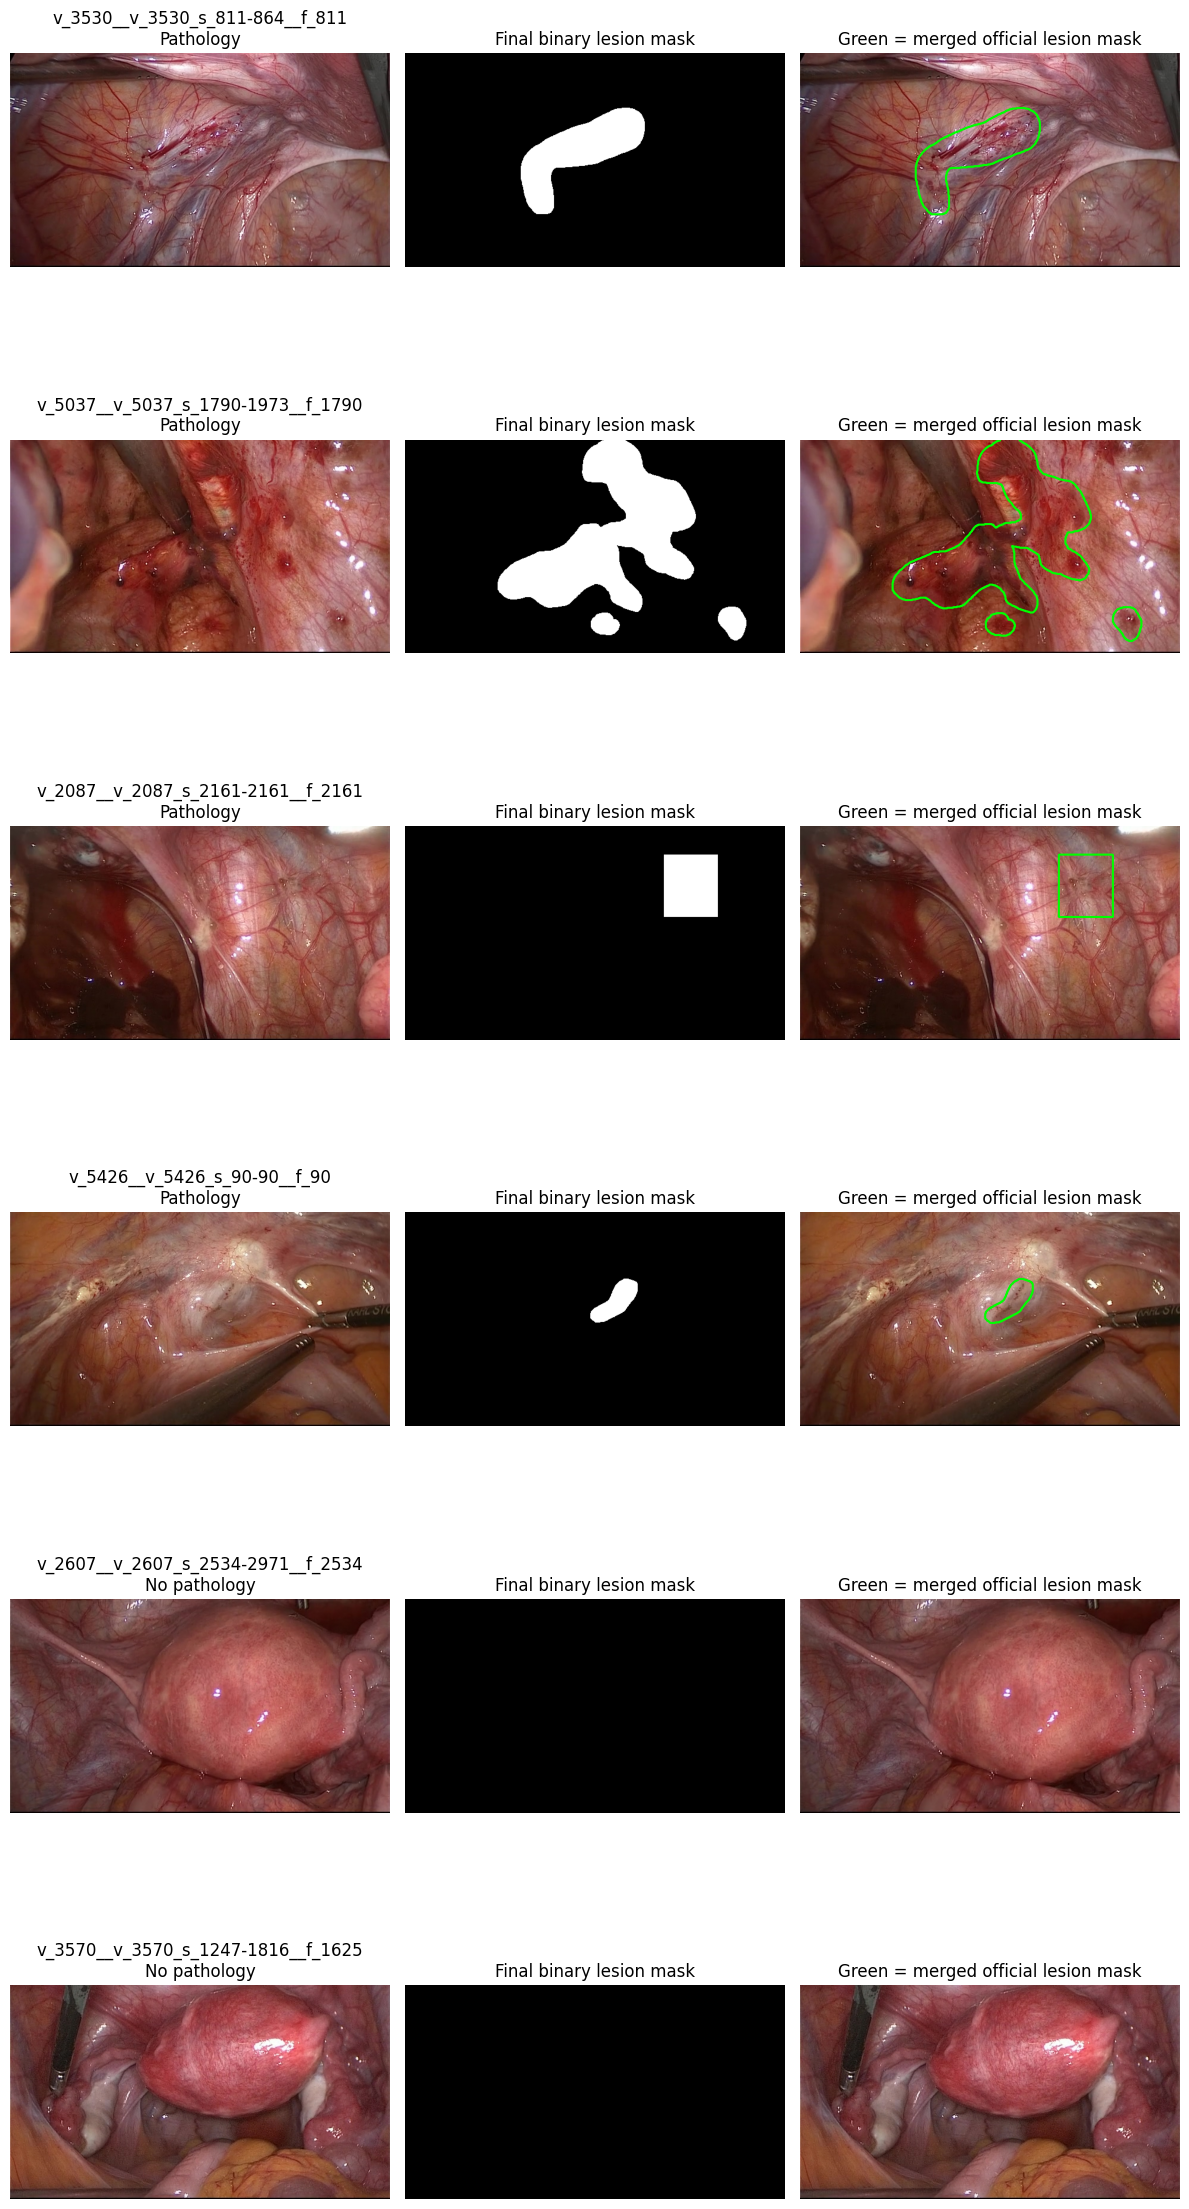


================ BINARY MASK CREATION COMPLETE ================
Final images: 572
Pathology images: 302
No-pathology images: 270
Binary masks created: 572
Final manifest: /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/manifests/glenda_final_binary_segmentation_manifest.csv
QC figure: /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/dataset_audit/binary_mask_alignment_qc.png
Audit summary: /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/dataset_audit/binary_mask_creation_summary.csv

PASSED: the final image-and-mask dataset is ready for a leakage-safe split.


In [ ]:
# ============================================================
# STEP 2B — CREATE AND VERIFY FINAL BINARY LESION MASKS
#
# Creates one final binary lesion mask for each selected image:
# - pathology images: merges all official instance masks
# - no-pathology images: creates a blank all-zero mask
#
# CPU-safe. No GPU. No model training.
# ============================================================

from google.colab import drive
from pathlib import Path
from PIL import Image
import ast
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Mount Drive and define project paths
# ------------------------------------------------------------
try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

INPUT_MANIFEST = (
    PROJECT_DIR
    / "processed"
    / "manifests"
    / "glenda_selected_study_frame_manifest.csv"
)

BINARY_MASK_DIR = (
    PROJECT_DIR
    / "processed"
    / "canonical_binary_lesion_masks"
)

FINAL_MANIFEST = (
    PROJECT_DIR
    / "processed"
    / "manifests"
    / "glenda_final_binary_segmentation_manifest.csv"
)

AUDIT_DIR = PROJECT_DIR / "outputs" / "dataset_audit"
QC_FIGURE = AUDIT_DIR / "binary_mask_alignment_qc.png"
QC_SUMMARY = AUDIT_DIR / "binary_mask_creation_summary.csv"

BINARY_MASK_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

assert INPUT_MANIFEST.exists(), f"Missing manifest: {INPUT_MANIFEST}"

manifest = pd.read_csv(INPUT_MANIFEST)

assert len(manifest) == 572, f"Expected 572 images, found {len(manifest)}"
assert int(manifest["binary_label"].sum()) == 302
assert int((manifest["binary_label"] == 0).sum()) == 270

# ------------------------------------------------------------
# 2. Helper functions
# ------------------------------------------------------------
def parse_mask_paths(value):
    """
    Read one manifest cell containing zero, one, or several mask paths.

    Supports:
    - JSON lists
    - Python lists
    - GLENDA's path1 | path2 format
    - one normal path
    """
    if pd.isna(value):
        return []

    text = str(value).strip()

    if text in ("", "[]", "nan", "None"):
        return []

    # JSON list, for example: ["path_1.png", "path_2.png"]
    try:
        parsed = json.loads(text)
        if isinstance(parsed, list):
            return [str(item).strip() for item in parsed if str(item).strip()]
    except Exception:
        pass

    # Python list, for example: ['path_1.png', 'path_2.png']
    try:
        parsed = ast.literal_eval(text)
        if isinstance(parsed, (list, tuple)):
            return [str(item).strip() for item in parsed if str(item).strip()]
    except Exception:
        pass

    # Actual GLENDA manifest format for several annotations.
    if " | " in text:
        return [part.strip() for part in text.split(" | ") if part.strip()]

    # One annotation-mask path.
    return [text]


def to_binary_mask(mask_image):
    """
    Convert grayscale/RGB/RGBA official annotation mask to Boolean mask.
    True = lesion; False = background.
    """
    array = np.asarray(mask_image)

    if array.ndim == 2:
        return array > 0

    # For RGB/RGBA masks, any non-black pixel is lesion.
    return np.any(array[..., :3] > 0, axis=-1)


# ------------------------------------------------------------
# 3. Merge official masks and create one canonical target/image
# ------------------------------------------------------------
records = []
missing_source_files = []
size_errors = []
positive_empty_masks = []

for index, row in manifest.iterrows():
    image_path = Path(row["local_image_path"])

    if not image_path.exists():
        missing_source_files.append(str(image_path))
        continue

    with Image.open(image_path) as image:
        image_rgb = image.convert("RGB")
        width, height = image_rgb.size

    sample_id = (
        f"{row['video_id']}__{row['sequence_id']}__{row['frame_id']}"
        .replace("/", "_")
        .replace("\\", "_")
    )

    output_mask_path = BINARY_MASK_DIR / f"{sample_id}.png"
    binary_label = int(row["binary_label"])
    source_mask_paths = parse_mask_paths(row["local_mask_paths"])

    if binary_label == 1:
        # Pathology image: combine all available lesion-instance masks.
        if len(source_mask_paths) == 0:
            raise ValueError(
                f"Pathology image has no linked mask paths: {image_path}"
            )

        merged_mask = np.zeros((height, width), dtype=bool)

        for source_mask_path in source_mask_paths:
            source_mask_path = Path(source_mask_path)

            if not source_mask_path.exists():
                missing_source_files.append(str(source_mask_path))
                continue

            with Image.open(source_mask_path) as instance_mask:
                if instance_mask.size != (width, height):
                    size_errors.append(
                        {
                            "sample_id": sample_id,
                            "image_path": str(image_path),
                            "mask_path": str(source_mask_path),
                            "image_size": (width, height),
                            "mask_size": instance_mask.size,
                        }
                    )
                    continue

                merged_mask |= to_binary_mask(instance_mask)

        if not merged_mask.any():
            positive_empty_masks.append(sample_id)

    else:
        # No-pathology image: correct target is an all-zero lesion mask.
        merged_mask = np.zeros((height, width), dtype=bool)

    # Save standard binary PNG: black=background, white=lesion.
    canonical_mask_array = (merged_mask.astype(np.uint8) * 255)
    Image.fromarray(canonical_mask_array).save(output_mask_path)

    records.append(
        {
            "sample_id": sample_id,
            "group": row["group"],
            "binary_label": binary_label,
            "video_id": row["video_id"],
            "sequence_id": row["sequence_id"],
            "frame_id": row["frame_id"],
            "lesion_classes": row["lesion_classes"],
            "selection_method": row["selection_method"],
            "image_path": str(image_path),
            "binary_mask_path": str(output_mask_path),
            "image_width": width,
            "image_height": height,
            "source_instance_mask_count": len(source_mask_paths),
            "binary_mask_foreground_pixels": int(merged_mask.sum()),
        }
    )

    if (index + 1) % 100 == 0 or (index + 1) == len(manifest):
        print(f"Created/verified {index + 1}/{len(manifest)} binary masks")

# ------------------------------------------------------------
# 4. Strict quality checks
# ------------------------------------------------------------
assert len(missing_source_files) == 0, (
    "A selected image or official annotation mask is missing.\n"
    f"First missing file: {missing_source_files[0]}"
)

assert len(size_errors) == 0, (
    "An annotation mask does not match the corresponding image size.\n"
    f"First error: {size_errors[0]}"
)

assert len(positive_empty_masks) == 0, (
    "A pathology image produced an empty binary lesion mask.\n"
    f"First affected sample: {positive_empty_masks[0]}"
)

final_manifest = (
    pd.DataFrame(records)
    .sort_values(["binary_label", "video_id", "sequence_id", "frame_id"])
    .reset_index(drop=True)
)

positive_rows = final_manifest[final_manifest["binary_label"] == 1].copy()
negative_rows = final_manifest[final_manifest["binary_label"] == 0].copy()

assert len(final_manifest) == 572
assert len(positive_rows) == 302
assert len(negative_rows) == 270
assert (positive_rows["binary_mask_foreground_pixels"] > 0).all()
assert (negative_rows["binary_mask_foreground_pixels"] == 0).all()
assert final_manifest["binary_mask_path"].map(lambda path: Path(path).exists()).all()

final_manifest.to_csv(FINAL_MANIFEST, index=False)

# ------------------------------------------------------------
# 5. Save audit summary
# ------------------------------------------------------------
summary = pd.DataFrame(
    [{
        "total_images": len(final_manifest),
        "pathology_images": len(positive_rows),
        "no_pathology_images": len(negative_rows),
        "binary_masks_created": len(final_manifest),
        "positive_masks_with_lesion": int(
            (positive_rows["binary_mask_foreground_pixels"] > 0).sum()
        ),
        "negative_masks_with_no_lesion": int(
            (negative_rows["binary_mask_foreground_pixels"] == 0).sum()
        ),
        "unique_videos": final_manifest["video_id"].nunique(),
        "final_manifest_path": str(FINAL_MANIFEST),
    }]
)

summary.to_csv(QC_SUMMARY, index=False)

# ------------------------------------------------------------
# 6. Create visual QC figure
# ------------------------------------------------------------
qc_positive = positive_rows.sample(n=4, random_state=42)
qc_negative = negative_rows.sample(n=2, random_state=42)
qc_cases = pd.concat([qc_positive, qc_negative], ignore_index=True)

fig, axes = plt.subplots(len(qc_cases), 3, figsize=(12, 4 * len(qc_cases)))

for axis_row, (_, sample) in zip(axes, qc_cases.iterrows()):
    image = np.asarray(Image.open(sample["image_path"]).convert("RGB"))
    mask = np.asarray(Image.open(sample["binary_mask_path"])) > 0

    axis_row[0].imshow(image)
    axis_row[0].set_title(
        f"{sample['sample_id']}\n"
        f"{'Pathology' if sample['binary_label'] == 1 else 'No pathology'}"
    )
    axis_row[0].axis("off")

    axis_row[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axis_row[1].set_title("Final binary lesion mask")
    axis_row[1].axis("off")

    axis_row[2].imshow(image)
    if mask.any():
        axis_row[2].contour(mask, colors="lime", linewidths=1.5)
    axis_row[2].set_title("Green = merged official lesion mask")
    axis_row[2].axis("off")

plt.tight_layout()
plt.savefig(QC_FIGURE, dpi=180, bbox_inches="tight")
plt.show()

print("\n================ BINARY MASK CREATION COMPLETE ================")
print("Final images:", len(final_manifest))
print("Pathology images:", len(positive_rows))
print("No-pathology images:", len(negative_rows))
print("Binary masks created:", len(final_manifest))
print("Final manifest:", FINAL_MANIFEST)
print("QC figure:", QC_FIGURE)
print("Audit summary:", QC_SUMMARY)
print("\nPASSED: the final image-and-mask dataset is ready for a leakage-safe split.")

In [ ]:
# ============================================================
# STEP 3 — CREATE A FIXED VIDEO-LEVEL 5-FOLD SPLIT
#
# Why:
# Frames from the same laparoscopic video are very similar.
# They must never be divided between training and validation.
#
# Output:
# A permanent 5-fold split file used identically by:
#   1) classifier + Grad-CAM baseline
#   2) segmentation model
#
# No GPU. No training.
# ============================================================

from pathlib import Path
import json
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

FINAL_MANIFEST = (
    PROJECT_DIR
    / "processed"
    / "manifests"
    / "glenda_final_binary_segmentation_manifest.csv"
)

SPLIT_MANIFEST = (
    PROJECT_DIR
    / "processed"
    / "manifests"
    / "glenda_video_level_5fold_splits.csv"
)

SPLIT_SUMMARY = (
    PROJECT_DIR
    / "outputs"
    / "dataset_audit"
    / "glenda_video_level_5fold_split_summary.csv"
)

SPLIT_PROTOCOL = (
    PROJECT_DIR
    / "outputs"
    / "dataset_audit"
    / "glenda_video_level_5fold_split_protocol.json"
)

assert FINAL_MANIFEST.exists(), f"Missing final manifest: {FINAL_MANIFEST}"

data = pd.read_csv(FINAL_MANIFEST)

assert len(data) == 572
assert set(data["binary_label"].unique()) == {0, 1}
assert data["video_id"].notna().all()

# Five folds are appropriate here:
# all 20 no-pathology videos can be distributed across folds,
# while all pathology videos remain represented too.
N_FOLDS = 5
RANDOM_SEED = 2026

splitter = StratifiedGroupKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=RANDOM_SEED,
)

data["validation_fold"] = -1

for fold_number, (_, validation_indices) in enumerate(
    splitter.split(
        X=data,
        y=data["binary_label"],
        groups=data["video_id"],
    )
):
    data.loc[validation_indices, "validation_fold"] = fold_number

# ------------------------------------------------------------
# Strict leakage checks
# ------------------------------------------------------------
assert (data["validation_fold"] >= 0).all()
assert set(data["validation_fold"].unique()) == set(range(N_FOLDS))

# Every video must appear in exactly one validation fold.
video_fold_counts = (
    data.groupby("video_id")["validation_fold"]
    .nunique()
)

assert (video_fold_counts == 1).all(), (
    "Leakage risk found: at least one video appears in multiple folds."
)

# Every fold must contain both pathology and no-pathology examples.
fold_label_counts = (
    data.groupby(["validation_fold", "binary_label"])
    .size()
    .unstack(fill_value=0)
)

for fold_number in range(N_FOLDS):
    assert fold_label_counts.loc[fold_number, 0] > 0, (
        f"Fold {fold_number} has no no-pathology images."
    )
    assert fold_label_counts.loc[fold_number, 1] > 0, (
        f"Fold {fold_number} has no pathology images."
    )

# ------------------------------------------------------------
# Build a clear audit table
# ------------------------------------------------------------
summary_rows = []

for fold_number in range(N_FOLDS):
    validation = data[data["validation_fold"] == fold_number]
    training = data[data["validation_fold"] != fold_number]

    summary_rows.append(
        {
            "fold": fold_number,
            "training_images": len(training),
            "validation_images": len(validation),
            "training_pathology_images": int(training["binary_label"].sum()),
            "training_no_pathology_images": int(
                (training["binary_label"] == 0).sum()
            ),
            "validation_pathology_images": int(
                validation["binary_label"].sum()
            ),
            "validation_no_pathology_images": int(
                (validation["binary_label"] == 0).sum()
            ),
            "training_videos": training["video_id"].nunique(),
            "validation_videos": validation["video_id"].nunique(),
            "shared_videos_between_train_and_validation": len(
                set(training["video_id"]) & set(validation["video_id"])
            ),
        }
    )

summary = pd.DataFrame(summary_rows)

assert (
    summary["shared_videos_between_train_and_validation"] == 0
).all(), "Video leakage found."

# Save permanent split files.
data.to_csv(SPLIT_MANIFEST, index=False)
summary.to_csv(SPLIT_SUMMARY, index=False)

protocol = {
    "split_type": "5-fold stratified group cross-validation",
    "group_variable": "video_id",
    "stratification_variable": "binary_label",
    "number_of_folds": N_FOLDS,
    "random_seed": RANDOM_SEED,
    "leakage_rule": (
        "All frames from one video_id are assigned to one validation fold only. "
        "The same video never appears in both training and validation."
    ),
    "models_using_this_exact_split": [
        "pretrained classifier with Grad-CAM",
        "pretrained segmentation model",
    ],
    "dataset_size": int(len(data)),
    "pathology_images": int(data["binary_label"].sum()),
    "no_pathology_images": int((data["binary_label"] == 0).sum()),
    "unique_videos": int(data["video_id"].nunique()),
}

with open(SPLIT_PROTOCOL, "w", encoding="utf-8") as file:
    json.dump(protocol, file, indent=2)

print("================ VIDEO-LEVEL 5-FOLD SPLIT COMPLETE ================\n")
display(summary)

print("\nSaved split manifest:")
print(SPLIT_MANIFEST)

print("\nSaved split summary:")
print(SPLIT_SUMMARY)

print("\nSaved protocol:")
print(SPLIT_PROTOCOL)

print("\nPASSED: all frames from each video stay together.")
print("This is the fixed fair split for both models.")

================ VIDEO-LEVEL 5-FOLD SPLIT COMPLETE ================



,fold,training_images,validation_images,training_pathology_images,training_no_pathology_images,validation_pathology_images,validation_no_pathology_images,training_videos,validation_videos,shared_videos_between_train_and_validation
0,0,467,105,237,230,65,40,148,36,0
1,1,474,98,254,220,48,50,148,36,0
2,2,444,128,244,200,58,70,146,38,0
3,3,446,126,236,210,66,60,148,36,0
4,4,457,115,237,220,65,50,146,38,0



Saved split manifest:
/content/project_drive_2026/MyDrive/glenda_xai_localization/processed/manifests/glenda_video_level_5fold_splits.csv

Saved split summary:
/content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/dataset_audit/glenda_video_level_5fold_split_summary.csv

Saved protocol:
/content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/dataset_audit/glenda_video_level_5fold_split_protocol.json

PASSED: all frames from each video stay together.
This is the fixed fair split for both models.


In [ ]:
# ============================================================
# STEP 4A — AUDIT THE DOWNLOADED CLASSIFIER + GRAD-CAM REPOSITORY
#
# Purpose:
# Inspect how the published baseline repository expects data,
# handles splits, trains its classifier, and produces Grad-CAM.
#
# No training. No GPU. No files are modified in the repository.
# ============================================================

from pathlib import Path
import re

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

REPO_DIR = PROJECT_DIR / "baseline_repository" / "glenda-xai"
AUDIT_DIR = PROJECT_DIR / "outputs" / "repository_audit"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

REPORT_PATH = AUDIT_DIR / "baseline_repository_compatibility_audit.txt"

assert REPO_DIR.exists(), f"Repository not found: {REPO_DIR}"

important_files = [
    "README_snapshot.md",
    "train.py",
    "gradcam_demo.py",
    "config.yaml",
]

print("================ REPOSITORY AUDIT ================\n")
print("Repository:", REPO_DIR)

report_lines = [
    "GLENDA XAI BASELINE REPOSITORY COMPATIBILITY AUDIT",
    f"Repository: {REPO_DIR}",
    "",
]

for filename in important_files:
    file_path = REPO_DIR / filename

    print(f"\n--- {filename} ---")
    report_lines.append(f"\n--- {filename} ---")

    if not file_path.exists():
        print("NOT FOUND")
        report_lines.append("NOT FOUND")
        continue

    text = file_path.read_text(encoding="utf-8", errors="replace")
    lines = text.splitlines()

    print("Found")
    print("Total lines:", len(lines))
    report_lines.append("Found")
    report_lines.append(f"Total lines: {len(lines)}")

    # Print only lines relevant to data, labels, splitting,
    # pretraining, training, checkpointing, or Grad-CAM.
    keywords = [
        "csv", "metadata", "data", "dataset", "image",
        "label", "patient", "video", "split", "fold",
        "train", "valid", "checkpoint", "pretrained",
        "gradcam", "cam", "model",
    ]

    matched = []
    for line_number, line in enumerate(lines, start=1):
        line_lower = line.lower()
        if any(keyword in line_lower for keyword in keywords):
            matched.append((line_number, line))

    # Keep output readable while preserving enough information
    # to determine how we should adapt the repository.
    matched = matched[:80]

    print("Relevant lines found:", len(matched))
    report_lines.append(f"Relevant lines shown: {len(matched)}")

    for line_number, line in matched:
        display_line = f"{line_number:>4}: {line}"
        print(display_line)
        report_lines.append(display_line)

report_lines.extend(
    [
        "",
        "PROJECT DECISION:",
        "The repository will be used as a pretrained classifier and "
        "Grad-CAM baseline only.",
        "Our own fixed video-level split will replace any repository "
        "random image-level split, preventing leakage.",
    ]
)

REPORT_PATH.write_text("\n".join(report_lines), encoding="utf-8")

print("\n================ AUDIT COMPLETE ================")
print("Saved report:", REPORT_PATH)
print("\nNext: create a repository-compatible metadata file using")
print("our fixed Fold-0 video-level training/validation split.")

================ REPOSITORY AUDIT ================

Repository: /content/project_drive_2026/MyDrive/glenda_xai_localization/baseline_repository/glenda-xai

--- README_snapshot.md ---
NOT FOUND

--- train.py ---
Found
Total lines: 93
Relevant lines found: 35
   8: from torch.utils.data import DataLoader
  10: from glenda.dataset import GlendaDataset
  11: from glenda.models import make_model
  12: from glenda.utils import set_seed, patient_level_split, make_class_weights
  15:     if cfg["training"]["loss"] == "weighted_ce" and class_weights is not None:
  19: def evaluate(loader, model, device):
  20:     model.eval()
  24:             x = batch["image"].to(device)
  25:             y = batch["label"].to(device)
  26:             logits = model(x)
  44:     set_seed(cfg["training"].get("seed", 42))
  47:     df = pd.read_csv(cfg["data"]["metadata_csv"])    
  48:     tr_df, va_df = patient_level_split(df, val_frac=cfg["training"]["val_split"], seed=cfg["training"].get("seed",42))
  50:

In [ ]:
# ============================================================
# STEP 4B — INSPECT THE REPOSITORY DATASET LOADER
#
# Why:
# We reuse the repository's pretrained classifier and Grad-CAM,
# but must feed it our leakage-safe video-level Fold-0 split.
#
# No GPU. No training. No project data are changed.
# ============================================================

from pathlib import Path

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

REPO_DIR = PROJECT_DIR / "baseline_repository" / "glenda-xai"

FILES_TO_INSPECT = [
    REPO_DIR / "glenda" / "dataset.py",
    REPO_DIR / "glenda" / "models.py",
    REPO_DIR / "glenda" / "utils.py",
]

print("================ BASELINE CODE COMPATIBILITY CHECK ================\n")

for file_path in FILES_TO_INSPECT:
    print(f"\n--- {file_path.relative_to(REPO_DIR)} ---")

    assert file_path.exists(), f"Required repository file not found: {file_path}"

    source = file_path.read_text(encoding="utf-8", errors="replace")
    lines = source.splitlines()

    print(f"Total lines: {len(lines)}\n")

    # The repository files are small. Show all lines so we can
    # correctly use its classes instead of guessing their inputs.
    for line_number, line in enumerate(lines, start=1):
        print(f"{line_number:>4}: {line}")

print("\n================ INSPECTION COMPLETE ================")
print("Next: generate the exact Fold-0 training and validation metadata")
print("required by the repository, without changing the fair split.")

================ BASELINE CODE COMPATIBILITY CHECK ================


--- glenda/dataset.py ---
Total lines: 31

   1: import os
   2: import cv2
   3: import torch
   4: import pandas as pd
   5: from torch.utils.data import Dataset
   6: from .transforms import get_train_tfms, get_test_tfms
   7: 
   8: class GlendaDataset(Dataset):
   9:     def __init__(self, df: pd.DataFrame, img_size=320, train=True, img_root=""):
  10:         self.df = df.reset_index(drop=True)
  11:         self.img_size = img_size
  12:         self.img_root = img_root or ""
  13:         self.tfms = get_train_tfms(img_size) if train else get_test_tfms(img_size)
  14: 
  15:     def __len__(self):
  16:         return len(self.df)
  17: 
  18:     def _read_img(self, p):
  19:         p = os.path.join(self.img_root, p) if self.img_root else p
  20:         img = cv2.imread(p, cv2.IMREAD_COLOR)
  21:         if img is None:
  22:             raise FileNotFoundError(f"Image not found: {p}")
  23:         return

In [ ]:
# ============================================================
# STEP 4C — CREATE FIXED FOLD-0 CLASSIFIER METADATA
#
# Uses our fair video-level split:
# - Training: folds 1, 2, 3, 4
# - Validation: fold 0
#
# These files are compatible with the repository's GlendaDataset:
#   image_path, label
#
# No GPU. No training.
# ============================================================

from pathlib import Path
import json
import pandas as pd

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

SPLIT_MANIFEST = (
    PROJECT_DIR
    / "processed"
    / "manifests"
    / "glenda_video_level_5fold_splits.csv"
)

FOLD_NUMBER = 0

FOLD_DIR = (
    PROJECT_DIR
    / "processed"
    / "fixed_folds"
    / f"fold_{FOLD_NUMBER}"
)

FOLD_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_CSV = FOLD_DIR / "classifier_train.csv"
VALIDATION_CSV = FOLD_DIR / "classifier_validation.csv"
COMBINED_CSV = FOLD_DIR / "classifier_fold_0_all.csv"
PROTOCOL_JSON = FOLD_DIR / "classifier_fold_0_protocol.json"

assert SPLIT_MANIFEST.exists(), f"Missing split manifest: {SPLIT_MANIFEST}"

data = pd.read_csv(SPLIT_MANIFEST)

assert len(data) == 572
assert "validation_fold" in data.columns

# Fold 0 is validation; all other folds are development training data.
train_data = data[data["validation_fold"] != FOLD_NUMBER].copy()
validation_data = data[data["validation_fold"] == FOLD_NUMBER].copy()

# The baseline repository expects exactly these two columns.
# patient_id is included only as a readable identifier;
# our custom training code will NOT call the repository's random splitter.
train_metadata = pd.DataFrame(
    {
        "image_path": train_data["image_path"],
        "label": train_data["binary_label"].astype(int),
        "patient_id": train_data["video_id"].astype(str),
        "video_id": train_data["video_id"].astype(str),
        "sample_id": train_data["sample_id"],
        "fold_role": "train",
    }
)

validation_metadata = pd.DataFrame(
    {
        "image_path": validation_data["image_path"],
        "label": validation_data["binary_label"].astype(int),
        "patient_id": validation_data["video_id"].astype(str),
        "video_id": validation_data["video_id"].astype(str),
        "sample_id": validation_data["sample_id"],
        "fold_role": "validation",
    }
)

# ------------------------------------------------------------
# Strict leakage and path checks
# ------------------------------------------------------------
train_videos = set(train_metadata["video_id"])
validation_videos = set(validation_metadata["video_id"])

assert len(train_videos & validation_videos) == 0, (
    "Leakage detected: some videos appear in both training and validation."
)

assert train_metadata["image_path"].map(lambda path: Path(path).exists()).all()
assert validation_metadata["image_path"].map(lambda path: Path(path).exists()).all()

assert set(train_metadata["label"].unique()) == {0, 1}
assert set(validation_metadata["label"].unique()) == {0, 1}

# Save stable metadata files.
train_metadata.to_csv(TRAIN_CSV, index=False)
validation_metadata.to_csv(VALIDATION_CSV, index=False)

combined_metadata = pd.concat(
    [train_metadata, validation_metadata],
    ignore_index=True,
)
combined_metadata.to_csv(COMBINED_CSV, index=False)

# Save a short machine-readable record of this experiment.
protocol = {
    "experiment": "GLENDA classifier and Grad-CAM baseline",
    "baseline_repository_model": "EdgeNeXt-Small from timm",
    "initialization": "ImageNet pretrained weights",
    "fold_number_used_for_first_experiment": FOLD_NUMBER,
    "training_folds": [1, 2, 3, 4],
    "validation_fold": 0,
    "split_unit": "video_id",
    "leakage_rule": (
        "All frames from any one laparoscopic video remain entirely "
        "in either training or validation."
    ),
    "training_images": int(len(train_metadata)),
    "validation_images": int(len(validation_metadata)),
    "training_pathology_images": int(train_metadata["label"].sum()),
    "validation_pathology_images": int(validation_metadata["label"].sum()),
    "training_no_pathology_images": int((train_metadata["label"] == 0).sum()),
    "validation_no_pathology_images": int(
        (validation_metadata["label"] == 0).sum()
    ),
    "outer_test_set_used": False,
}

with open(PROTOCOL_JSON, "w", encoding="utf-8") as file:
    json.dump(protocol, file, indent=2)

summary = pd.DataFrame(
    [
        {
            "role": "training",
            "images": len(train_metadata),
            "pathology_images": int(train_metadata["label"].sum()),
            "no_pathology_images": int((train_metadata["label"] == 0).sum()),
            "videos": train_metadata["video_id"].nunique(),
        },
        {
            "role": "validation",
            "images": len(validation_metadata),
            "pathology_images": int(validation_metadata["label"].sum()),
            "no_pathology_images": int((validation_metadata["label"] == 0).sum()),
            "videos": validation_metadata["video_id"].nunique(),
        },
    ]
)

print("================ FIXED FOLD-0 METADATA COMPLETE ================\n")
display(summary)

print("\nTraining CSV:", TRAIN_CSV)
print("Validation CSV:", VALIDATION_CSV)
print("Combined CSV:", COMBINED_CSV)
print("Protocol:", PROTOCOL_JSON)

print("\nPASSED: repository-compatible metadata is ready.")
print("The original repository train.py will NOT be used because it creates")
print("a new random split. We will use its pretrained EdgeNeXt model and")
print("dataset loader with this fixed split instead.")

================ FIXED FOLD-0 METADATA COMPLETE ================



,role,images,pathology_images,no_pathology_images,videos
0,training,467,237,230,148
1,validation,105,65,40,36



Training CSV: /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/fixed_folds/fold_0/classifier_train.csv
Validation CSV: /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/fixed_folds/fold_0/classifier_validation.csv
Combined CSV: /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/fixed_folds/fold_0/classifier_fold_0_all.csv
Protocol: /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/fixed_folds/fold_0/classifier_fold_0_protocol.json

PASSED: repository-compatible metadata is ready.
The original repository train.py will NOT be used because it creates
a new random split. We will use its pretrained EdgeNeXt model and
dataset loader with this fixed split instead.


In [ ]:
# ============================================================
# STEP 4D — PRETRAINED CLASSIFIER SMOKE TEST
#
# Verifies:
# - repository dataset loader reads our images
# - pretrained EdgeNeXt-Small loads successfully
# - one real batch produces valid predictions
#
# No model training occurs in this cell.
# Works on CPU; automatically uses GPU if available.
# ============================================================

from pathlib import Path
import sys
import subprocess
import importlib.util
import json
import time

# Install only missing libraries required by the published repository.
required_packages = {
    "timm": "timm",
    "albumentations": "albumentations",
    "cv2": "opencv-python-headless",
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing missing package: {package_name}")
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package_name]
        )

import pandas as pd
import torch
from torch.utils.data import DataLoader

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

REPO_DIR = PROJECT_DIR / "baseline_repository" / "glenda-xai"
FOLD_DIR = PROJECT_DIR / "processed" / "fixed_folds" / "fold_0"

TRAIN_CSV = FOLD_DIR / "classifier_train.csv"
VALIDATION_CSV = FOLD_DIR / "classifier_validation.csv"

OUTPUT_DIR = PROJECT_DIR / "outputs" / "classifier_fold_0"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SMOKE_TEST_JSON = OUTPUT_DIR / "classifier_pretrained_smoke_test.json"

assert REPO_DIR.exists()
assert TRAIN_CSV.exists()
assert VALIDATION_CSV.exists()

# Allow imports from the downloaded published repository.
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from glenda.dataset import GlendaDataset
from glenda.models import make_model

train_metadata = pd.read_csv(TRAIN_CSV)
validation_metadata = pd.read_csv(VALIDATION_CSV)

assert len(train_metadata) == 467
assert len(validation_metadata) == 105

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Four images are enough for a realistic smoke test.
SMOKE_BATCH_SIZE = 4
IMAGE_SIZE = 320

dataset = GlendaDataset(
    train_metadata.head(8),
    img_size=IMAGE_SIZE,
    train=True,
    img_root="",
)

loader = DataLoader(
    dataset,
    batch_size=SMOKE_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

batch = next(iter(loader))

images = batch["image"].to(device)
labels = batch["label"].to(device)

print("Real image batch shape:", tuple(images.shape))
print("Real label batch shape:", tuple(labels.shape))
print("Labels in this test batch:", labels.detach().cpu().tolist())

# pretrained=True downloads/uses ImageNet initialization.
# This is transfer learning, not a model trained on GLENDA.
start_time = time.time()

model = make_model(
    name="edgenext_small",
    num_classes=2,
    pretrained=True,
).to(device)

model.eval()

with torch.no_grad():
    logits = model(images)
    probabilities = torch.softmax(logits, dim=1)

elapsed_seconds = time.time() - start_time

assert logits.shape == (SMOKE_BATCH_SIZE, 2)
assert torch.isfinite(logits).all()
assert torch.isfinite(probabilities).all()

predicted_labels = probabilities.argmax(dim=1)

smoke_result = {
    "device": str(device),
    "model": "edgenext_small",
    "initialization": "ImageNet pretrained",
    "image_size": IMAGE_SIZE,
    "input_shape": list(images.shape),
    "output_shape": list(logits.shape),
    "batch_size": SMOKE_BATCH_SIZE,
    "forward_pass_seconds_including_model_load": round(elapsed_seconds, 3),
    "predicted_labels": predicted_labels.detach().cpu().tolist(),
    "pathology_probabilities": [
        round(float(value), 4)
        for value in probabilities[:, 1].detach().cpu()
    ],
    "training_has_started": False,
}

with open(SMOKE_TEST_JSON, "w", encoding="utf-8") as file:
    json.dump(smoke_result, file, indent=2)

print("\n================ CLASSIFIER SMOKE TEST PASSED ================")
print("Model: ImageNet-pretrained EdgeNeXt-Small")
print("Input shape:", tuple(images.shape))
print("Output shape:", tuple(logits.shape))
print("Predicted pathology probabilities:",
      [round(float(x), 4) for x in probabilities[:, 1].detach().cpu()])
print("Saved:", SMOKE_TEST_JSON)
print("\nNext: start the short checkpointed Fold-0 classifier training run.")

Device: cpu
Real image batch shape: (4, 3, 320, 320)
Real label batch shape: (4,)
Labels in this test batch: [0, 0, 0, 0]


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.4MB            

model.safetensors: downloading bytes:           |  0.00B            


================ CLASSIFIER SMOKE TEST PASSED ================
Model: ImageNet-pretrained EdgeNeXt-Small
Input shape: (4, 3, 320, 320)
Output shape: (4, 2)
Predicted pathology probabilities: [0.431, 0.5126, 0.4501, 0.4539]
Saved: /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/classifier_fold_0/classifier_pretrained_smoke_test.json

Next: start the short checkpointed Fold-0 classifier training run.


In [ ]:
# ============================================================
# STEP 5 — CHECKPOINTED FOLD-0 CLASSIFIER TRAINING
#
# Model: ImageNet-pretrained EdgeNeXt-Small
# Task: pathology (1) vs no-pathology (0)
# Split: fixed video-level Fold-0 split only
#
# CPU: trains 2 epochs per run
# GPU: trains 12 epochs per run
# Every completed epoch is saved safely to Google Drive.
# ============================================================

from pathlib import Path
import sys
import json
import random
import time

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

# ------------------------------------------------------------
# 1. Reproducibility and paths
# ------------------------------------------------------------
SEED = 2026

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

REPO_DIR = PROJECT_DIR / "baseline_repository" / "glenda-xai"
FOLD_DIR = PROJECT_DIR / "processed" / "fixed_folds" / "fold_0"

TRAIN_CSV = FOLD_DIR / "classifier_train.csv"
VALIDATION_CSV = FOLD_DIR / "classifier_validation.csv"

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints" / "classifier_edgenext_fold_0"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "classifier_fold_0"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LAST_CHECKPOINT = CHECKPOINT_DIR / "last_checkpoint.pt"
BEST_CHECKPOINT = CHECKPOINT_DIR / "best_validation_auc.pt"
HISTORY_CSV = OUTPUT_DIR / "classifier_training_history.csv"
CONFIG_JSON = OUTPUT_DIR / "classifier_training_configuration.json"

assert TRAIN_CSV.exists()
assert VALIDATION_CSV.exists()
assert REPO_DIR.exists()

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from glenda.dataset import GlendaDataset
from glenda.models import make_model

# ------------------------------------------------------------
# 2. Device-aware settings
# ------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# A short safe CPU block; a larger productive GPU block.
if device.type == "cuda":
    EPOCHS_THIS_RUN = 12
    BATCH_SIZE = 16
else:
    EPOCHS_THIS_RUN = 20
    BATCH_SIZE = 8

IMAGE_SIZE = 320
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4
MAX_TOTAL_EPOCHS = 20
PATIENCE = 5

print("Device:", device)
print("Epochs in this run:", EPOCHS_THIS_RUN)
print("Maximum total epochs:", MAX_TOTAL_EPOCHS)
print("Batch size:", BATCH_SIZE)

# ------------------------------------------------------------
# 3. Load our fixed split only
# ------------------------------------------------------------
train_metadata = pd.read_csv(TRAIN_CSV)
validation_metadata = pd.read_csv(VALIDATION_CSV)

assert len(train_metadata) == 467
assert len(validation_metadata) == 105
assert set(train_metadata["video_id"]).isdisjoint(
    set(validation_metadata["video_id"])
), "Video leakage detected."

print(
    "Training images:", len(train_metadata),
    "| pathology:", int(train_metadata["label"].sum()),
    "| no-pathology:", int((train_metadata["label"] == 0).sum()),
)
print(
    "Validation images:", len(validation_metadata),
    "| pathology:", int(validation_metadata["label"].sum()),
    "| no-pathology:", int((validation_metadata["label"] == 0).sum()),
)
print("Outer-test patients/videos used during training: 0")

train_dataset = GlendaDataset(
    train_metadata,
    img_size=IMAGE_SIZE,
    train=True,
    img_root="",
)

validation_dataset = GlendaDataset(
    validation_metadata,
    img_size=IMAGE_SIZE,
    train=False,
    img_root="",
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

# ------------------------------------------------------------
# 4. Model, weighted loss, optimiser, scheduler
# ------------------------------------------------------------
resuming = LAST_CHECKPOINT.exists()

model = make_model(
    name="edgenext_small",
    num_classes=2,
    pretrained=not resuming,
).to(device)

class_counts = train_metadata["label"].value_counts().to_dict()
class_weights = torch.tensor(
    [
        1.0 / class_counts.get(0, 1),
        1.0 / class_counts.get(1, 1),
    ],
    dtype=torch.float32,
)
class_weights = (class_weights / class_weights.mean()).to(device)

criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.03,
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=MAX_TOTAL_EPOCHS,
)

def move_optimizer_state_to_device(optimizer, target_device):
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(target_device)

def evaluate(model, loader):
    model.eval()
    all_labels = []
    all_probabilities = []
    total_loss = 0.0
    total_items = 0

    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(device, non_blocking=True)
            labels = batch["label"].to(device, non_blocking=True)

            logits = model(images)
            loss = criterion(logits, labels)

            probabilities = torch.softmax(logits, dim=1)[:, 1]

            total_loss += float(loss.item()) * len(labels)
            total_items += len(labels)

            all_labels.extend(labels.detach().cpu().numpy().tolist())
            all_probabilities.extend(
                probabilities.detach().cpu().numpy().tolist()
            )

    labels_array = np.asarray(all_labels)
    probabilities_array = np.asarray(all_probabilities)
    predictions_array = (probabilities_array >= 0.5).astype(int)

    return {
        "validation_loss": total_loss / max(total_items, 1),
        "validation_auc": float(
            roc_auc_score(labels_array, probabilities_array)
        ),
        "validation_accuracy": float(
            accuracy_score(labels_array, predictions_array)
        ),
        "validation_balanced_accuracy": float(
            balanced_accuracy_score(labels_array, predictions_array)
        ),
        "validation_f1": float(
            f1_score(labels_array, predictions_array, zero_division=0)
        ),
    }

def save_checkpoint_safely(path, checkpoint_data):
    temporary_path = path.with_suffix(path.suffix + ".temporary")
    torch.save(checkpoint_data, temporary_path)
    temporary_path.replace(path)

# ------------------------------------------------------------
# 5. Resume safely, if a checkpoint exists
# ------------------------------------------------------------
history = []
best_validation_auc = -float("inf")
completed_epoch = 0
epochs_without_improvement = 0

if resuming:
    checkpoint = torch.load(
        LAST_CHECKPOINT,
        map_location=device,
        weights_only=False,
    )

    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])
    move_optimizer_state_to_device(optimizer, device)
    scheduler.load_state_dict(checkpoint["scheduler_state"])

    completed_epoch = int(checkpoint["completed_epoch"])
    best_validation_auc = float(checkpoint["best_validation_auc"])
    epochs_without_improvement = int(
        checkpoint.get("epochs_without_improvement", 0)
    )
    history = checkpoint.get("history", [])

    print(
        f"Resuming safely after epoch {completed_epoch}. "
        f"Best validation AUC so far: {best_validation_auc:.4f}"
    )
else:
    print("Starting a new ImageNet-pretrained classifier run.")

target_epoch = min(completed_epoch + EPOCHS_THIS_RUN, MAX_TOTAL_EPOCHS)

if completed_epoch >= MAX_TOTAL_EPOCHS:
    print(
        f"\nTraining already reached the configured maximum of "
        f"{MAX_TOTAL_EPOCHS} epochs."
    )

# ------------------------------------------------------------
# 6. Train, validate, and checkpoint every epoch
# ------------------------------------------------------------
for epoch in range(completed_epoch + 1, target_epoch + 1):
    epoch_start = time.time()

    model.train()
    training_loss_sum = 0.0
    training_items = 0

    for batch in train_loader:
        images = batch["image"].to(device, non_blocking=True)
        labels = batch["label"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        training_loss_sum += float(loss.item()) * len(labels)
        training_items += len(labels)

    scheduler.step()

    validation_metrics = evaluate(model, validation_loader)

    record = {
        "epoch": epoch,
        "training_loss": training_loss_sum / max(training_items, 1),
        "learning_rate": optimizer.param_groups[0]["lr"],
        **validation_metrics,
        "epoch_minutes": (time.time() - epoch_start) / 60.0,
    }

    history = [
        item for item in history
        if int(item.get("epoch", -1)) != epoch
    ]
    history.append(record)
    history = sorted(history, key=lambda item: int(item["epoch"]))

    improved = record["validation_auc"] > best_validation_auc

    if improved:
        best_validation_auc = record["validation_auc"]
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    checkpoint_data = {
        "model_name": "edgenext_small",
        "initialization": "ImageNet pretrained",
        "completed_epoch": epoch,
        "best_validation_auc": best_validation_auc,
        "epochs_without_improvement": epochs_without_improvement,
        "model_state": {
            key: value.detach().cpu()
            for key, value in model.state_dict().items()
        },
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "history": history,
        "training_videos": int(train_metadata["video_id"].nunique()),
        "validation_videos": int(validation_metadata["video_id"].nunique()),
        "outer_test_used": False,
    }

    # Always save latest progress.
    save_checkpoint_safely(LAST_CHECKPOINT, checkpoint_data)

    # Save the best validation-AUC checkpoint separately.
    if improved:
        save_checkpoint_safely(BEST_CHECKPOINT, checkpoint_data)

    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)

    print(
        f"Epoch {epoch:02d}/{MAX_TOTAL_EPOCHS} | "
        f"train loss={record['training_loss']:.4f} | "
        f"val AUC={record['validation_auc']:.4f} | "
        f"val balanced accuracy={record['validation_balanced_accuracy']:.4f} | "
        f"time={record['epoch_minutes']:.1f} min | "
        f"{'BEST checkpoint saved' if improved else 'checkpoint saved'}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"Early stopping: no validation-AUC improvement for "
            f"{PATIENCE} consecutive epochs."
        )
        break

# ------------------------------------------------------------
# 7. Save run configuration
# ------------------------------------------------------------
configuration = {
    "model": "EdgeNeXt-Small",
    "initialization": "ImageNet pretrained",
    "image_size": IMAGE_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "loss": "weighted cross entropy with label smoothing",
    "validation_metric_for_best_checkpoint": "ROC-AUC",
    "fold": 0,
    "split_unit": "video_id",
    "outer_test_used": False,
    "checkpoint_frequency": "every epoch",
    "device_used_in_this_run": str(device),
}

with open(CONFIG_JSON, "w", encoding="utf-8") as file:
    json.dump(configuration, file, indent=2)

print("\n================ TRAINING BLOCK COMPLETE ================")
print("Latest checkpoint:", LAST_CHECKPOINT)
print("Best validation-AUC checkpoint:", BEST_CHECKPOINT)
print("Training history:", HISTORY_CSV)
print("Configuration:", CONFIG_JSON)
print("\nRun this same cell again to resume safely.")
print("GPU runs automatically use a larger 12-epoch block.")

Device: cpu
Epochs in this run: 20
Maximum total epochs: 20
Batch size: 8
Training images: 467 | pathology: 237 | no-pathology: 230
Validation images: 105 | pathology: 65 | no-pathology: 40
Outer-test patients/videos used during training: 0
Starting a new ImageNet-pretrained classifier run.
Epoch 01/20 | train loss=0.5524 | val AUC=0.9454 | val balanced accuracy=0.8000 | time=3.6 min | BEST checkpoint saved
Epoch 02/20 | train loss=0.3370 | val AUC=0.9558 | val balanced accuracy=0.8587 | time=3.5 min | BEST checkpoint saved
Epoch 03/20 | train loss=0.2272 | val AUC=0.9623 | val balanced accuracy=0.8962 | time=3.6 min | BEST checkpoint saved
Epoch 04/20 | train loss=0.1636 | val AUC=0.8346 | val balanced accuracy=0.8625 | time=3.6 min | checkpoint saved
Epoch 05/20 | train loss=0.1455 | val AUC=0.8573 | val balanced accuracy=0.8500 | time=3.6 min | checkpoint saved
Epoch 06/20 | train loss=0.0985 | val AUC=0.8585 | val balanced accuracy=0.8442 | time=3.6 min | checkpoint saved
Epoch 07/

Device: cpu


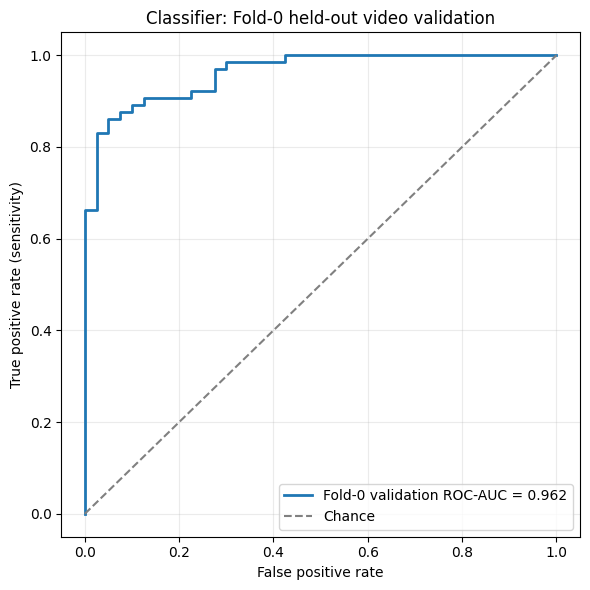


================ CLASSIFIER VALIDATION COMPLETE ================


,checkpoint_epoch,selection_metric,roc_auc,selected_threshold_from_validation,accuracy_at_selected_threshold,balanced_accuracy_at_selected_threshold,sensitivity_at_selected_threshold,specificity_at_selected_threshold,precision_at_selected_threshold,f1_at_selected_threshold,validation_images,validation_pathology_images,validation_no_pathology_images,validation_videos,outer_test_used
0,3,validation ROC-AUC,0.962308,0.6,0.895238,0.905769,0.861538,0.95,0.965517,0.910569,105,65,40,36,False



Threshold comparison:


,threshold,balanced_accuracy,sensitivity,specificity,precision,f1_score
0,0.10,0.866346,0.907692,0.825,0.893939,0.900763
1,0.15,0.878846,0.907692,0.850,0.907692,0.907692
2,0.20,0.891346,0.907692,0.875,0.921875,0.914729
3,0.25,0.896154,0.892308,0.900,0.935484,0.913386
4,0.30,0.896154,0.892308,0.900,0.935484,0.913386
5,0.35,0.896154,0.892308,0.900,0.935484,0.913386
6,0.40,0.896154,0.892308,0.900,0.935484,0.913386
7,0.45,0.896154,0.892308,0.900,0.935484,0.913386
8,0.50,0.896154,0.892308,0.900,0.935484,0.913386
9,0.55,0.888462,0.876923,0.900,0.934426,0.904762



Saved:
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/classifier_fold_0/best_classifier_validation_predictions.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/classifier_fold_0/best_classifier_validation_metrics.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/classifier_fold_0/best_classifier_validation_thresholds.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/classifier_fold_0/best_classifier_validation_roc_curve.png
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/classifier_fold_0/best_classifier_validation_summary.json

Important: these are Fold-0 validation results only.
They will later be combined with the same evaluation from folds 1–4.


In [ ]:
# ============================================================
# STEP 6 — DETAILED FOLD-0 CLASSIFIER VALIDATION
#
# Evaluates the best saved checkpoint from epoch 3.
# No training occurs. No validation data are used to update
# the model.
# ============================================================

from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

REPO_DIR = PROJECT_DIR / "baseline_repository" / "glenda-xai"
FOLD_DIR = PROJECT_DIR / "processed" / "fixed_folds" / "fold_0"

VALIDATION_CSV = FOLD_DIR / "classifier_validation.csv"

CHECKPOINT_PATH = (
    PROJECT_DIR
    / "checkpoints"
    / "classifier_edgenext_fold_0"
    / "best_validation_auc.pt"
)

OUTPUT_DIR = PROJECT_DIR / "outputs" / "classifier_fold_0"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PREDICTIONS_CSV = OUTPUT_DIR / "best_classifier_validation_predictions.csv"
METRICS_CSV = OUTPUT_DIR / "best_classifier_validation_metrics.csv"
THRESHOLDS_CSV = OUTPUT_DIR / "best_classifier_validation_thresholds.csv"
ROC_FIGURE = OUTPUT_DIR / "best_classifier_validation_roc_curve.png"
SUMMARY_JSON = OUTPUT_DIR / "best_classifier_validation_summary.json"

assert VALIDATION_CSV.exists()
assert CHECKPOINT_PATH.exists()

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from glenda.dataset import GlendaDataset
from glenda.models import make_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

validation_metadata = pd.read_csv(VALIDATION_CSV)

validation_dataset = GlendaDataset(
    validation_metadata,
    img_size=320,
    train=False,
    img_root="",
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

# Load best validation-AUC model. pretrained=False means we load
# exactly the saved GLENDA-trained checkpoint, not fresh weights.
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)

model = make_model(
    name="edgenext_small",
    num_classes=2,
    pretrained=False,
).to(device)

model.load_state_dict(checkpoint["model_state"])
model.eval()

labels = []
probabilities = []
paths = []

with torch.no_grad():
    for batch in validation_loader:
        images = batch["image"].to(device, non_blocking=True)
        logits = model(images)

        pathology_probability = torch.softmax(logits, dim=1)[:, 1]

        labels.extend(batch["label"].numpy().tolist())
        probabilities.extend(
            pathology_probability.detach().cpu().numpy().tolist()
        )
        paths.extend(batch["path"])

labels = np.asarray(labels, dtype=int)
probabilities = np.asarray(probabilities, dtype=float)

assert len(labels) == 105
assert len(probabilities) == 105
assert np.isfinite(probabilities).all()

auc = float(roc_auc_score(labels, probabilities))

# Evaluate several thresholds transparently.
threshold_rows = []

for threshold in np.arange(0.10, 0.91, 0.05):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else 0.0
    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    threshold_rows.append(
        {
            "threshold": round(float(threshold), 2),
            "accuracy": accuracy_score(labels, predictions),
            "balanced_accuracy": balanced_accuracy_score(labels, predictions),
            "sensitivity": sensitivity,
            "specificity": specificity,
            "precision": precision_score(labels, predictions, zero_division=0),
            "f1_score": f1_score(labels, predictions, zero_division=0),
            "youden_j": sensitivity + specificity - 1.0,
            "true_negative": int(tn),
            "false_positive": int(fp),
            "false_negative": int(fn),
            "true_positive": int(tp),
        }
    )

threshold_table = pd.DataFrame(threshold_rows)
selected_threshold_row = threshold_table.loc[
    threshold_table["youden_j"].idxmax()
].copy()

selected_threshold = float(selected_threshold_row["threshold"])
selected_predictions = (probabilities >= selected_threshold).astype(int)

# Save one row per held-out validation image.
predictions_table = validation_metadata.copy()
predictions_table["true_label"] = labels
predictions_table["pathology_probability"] = probabilities
predictions_table["prediction_at_selected_threshold"] = selected_predictions
predictions_table["selected_threshold"] = selected_threshold
predictions_table.to_csv(PREDICTIONS_CSV, index=False)

threshold_table.to_csv(THRESHOLDS_CSV, index=False)

metrics_table = pd.DataFrame(
    [{
        "checkpoint_epoch": int(checkpoint["completed_epoch"]),
        "selection_metric": "validation ROC-AUC",
        "roc_auc": auc,
        "selected_threshold_from_validation": selected_threshold,
        "accuracy_at_selected_threshold": float(
            selected_threshold_row["accuracy"]
        ),
        "balanced_accuracy_at_selected_threshold": float(
            selected_threshold_row["balanced_accuracy"]
        ),
        "sensitivity_at_selected_threshold": float(
            selected_threshold_row["sensitivity"]
        ),
        "specificity_at_selected_threshold": float(
            selected_threshold_row["specificity"]
        ),
        "precision_at_selected_threshold": float(
            selected_threshold_row["precision"]
        ),
        "f1_at_selected_threshold": float(
            selected_threshold_row["f1_score"]
        ),
        "validation_images": len(labels),
        "validation_pathology_images": int(labels.sum()),
        "validation_no_pathology_images": int((labels == 0).sum()),
        "validation_videos": int(validation_metadata["video_id"].nunique()),
        "outer_test_used": False,
    }]
)

metrics_table.to_csv(METRICS_CSV, index=False)

# ROC curve figure.
false_positive_rate, true_positive_rate, _ = roc_curve(labels, probabilities)

plt.figure(figsize=(6, 6))
plt.plot(
    false_positive_rate,
    true_positive_rate,
    linewidth=2,
    label=f"Fold-0 validation ROC-AUC = {auc:.3f}",
)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (sensitivity)")
plt.title("Classifier: Fold-0 held-out video validation")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(ROC_FIGURE, dpi=180, bbox_inches="tight")
plt.show()

summary = metrics_table.iloc[0].to_dict()
summary["checkpoint_path"] = str(CHECKPOINT_PATH)
summary["predictions_path"] = str(PREDICTIONS_CSV)
summary["threshold_results_path"] = str(THRESHOLDS_CSV)

with open(SUMMARY_JSON, "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)

print("\n================ CLASSIFIER VALIDATION COMPLETE ================")
display(metrics_table)

print("\nThreshold comparison:")
display(
    threshold_table[
        [
            "threshold",
            "balanced_accuracy",
            "sensitivity",
            "specificity",
            "precision",
            "f1_score",
        ]
    ]
)

print("\nSaved:")
print("-", PREDICTIONS_CSV)
print("-", METRICS_CSV)
print("-", THRESHOLDS_CSV)
print("-", ROC_FIGURE)
print("-", SUMMARY_JSON)

print("\nImportant: these are Fold-0 validation results only.")
print("They will later be combined with the same evaluation from folds 1–4.")

In [ ]:
# ============================================================
# STEP 7 — CREATE FIXED FOLD-0 SEGMENTATION METADATA
#
# Uses exactly the same video-level Fold-0 split as the classifier.
# Each row contains an image and its final binary lesion mask.
#
# No GPU. No training.
# ============================================================

from pathlib import Path
import json
import pandas as pd

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

SPLIT_MANIFEST = (
    PROJECT_DIR
    / "processed"
    / "manifests"
    / "glenda_video_level_5fold_splits.csv"
)

FOLD_NUMBER = 0

FOLD_DIR = (
    PROJECT_DIR
    / "processed"
    / "fixed_folds"
    / f"fold_{FOLD_NUMBER}"
)

FOLD_DIR.mkdir(parents=True, exist_ok=True)

SEGMENTATION_TRAIN_CSV = FOLD_DIR / "segmentation_train.csv"
SEGMENTATION_VALIDATION_CSV = FOLD_DIR / "segmentation_validation.csv"
SEGMENTATION_PROTOCOL_JSON = FOLD_DIR / "segmentation_fold_0_protocol.json"

assert SPLIT_MANIFEST.exists(), f"Missing split manifest: {SPLIT_MANIFEST}"

data = pd.read_csv(SPLIT_MANIFEST)

required_columns = {
    "sample_id",
    "image_path",
    "binary_mask_path",
    "binary_label",
    "video_id",
    "validation_fold",
}

missing_columns = required_columns - set(data.columns)
assert not missing_columns, f"Missing required columns: {missing_columns}"

train_data = data[data["validation_fold"] != FOLD_NUMBER].copy()
validation_data = data[data["validation_fold"] == FOLD_NUMBER].copy()

# Keep only fields required for segmentation plus identifiers for auditing.
keep_columns = [
    "sample_id",
    "image_path",
    "binary_mask_path",
    "binary_label",
    "video_id",
    "sequence_id",
    "frame_id",
    "lesion_classes",
]

segmentation_train = train_data[keep_columns].copy()
segmentation_validation = validation_data[keep_columns].copy()

segmentation_train = segmentation_train.rename(
    columns={
        "binary_mask_path": "mask_path",
        "binary_label": "image_label",
    }
)

segmentation_validation = segmentation_validation.rename(
    columns={
        "binary_mask_path": "mask_path",
        "binary_label": "image_label",
    }
)

# ------------------------------------------------------------
# Strict split and file checks
# ------------------------------------------------------------
assert len(segmentation_train) == 467
assert len(segmentation_validation) == 105

assert set(segmentation_train["video_id"]).isdisjoint(
    set(segmentation_validation["video_id"])
), "Leakage detected: videos appear in both sets."

assert segmentation_train["image_path"].map(
    lambda path: Path(path).exists()
).all()

assert segmentation_validation["image_path"].map(
    lambda path: Path(path).exists()
).all()

assert segmentation_train["mask_path"].map(
    lambda path: Path(path).exists()
).all()

assert segmentation_validation["mask_path"].map(
    lambda path: Path(path).exists()
).all()

assert set(segmentation_train["image_label"].unique()) == {0, 1}
assert set(segmentation_validation["image_label"].unique()) == {0, 1}

segmentation_train.to_csv(SEGMENTATION_TRAIN_CSV, index=False)
segmentation_validation.to_csv(SEGMENTATION_VALIDATION_CSV, index=False)

summary = pd.DataFrame(
    [
        {
            "role": "training",
            "images": len(segmentation_train),
            "pathology_images": int(segmentation_train["image_label"].sum()),
            "no_pathology_images": int(
                (segmentation_train["image_label"] == 0).sum()
            ),
            "videos": segmentation_train["video_id"].nunique(),
        },
        {
            "role": "validation",
            "images": len(segmentation_validation),
            "pathology_images": int(
                segmentation_validation["image_label"].sum()
            ),
            "no_pathology_images": int(
                (segmentation_validation["image_label"] == 0).sum()
            ),
            "videos": segmentation_validation["video_id"].nunique(),
        },
    ]
)

protocol = {
    "experiment": "GLENDA binary endometriosis lesion segmentation",
    "fold": FOLD_NUMBER,
    "training_folds": [1, 2, 3, 4],
    "validation_fold": 0,
    "split_unit": "video_id",
    "training_images": int(len(segmentation_train)),
    "validation_images": int(len(segmentation_validation)),
    "training_pathology_images": int(
        segmentation_train["image_label"].sum()
    ),
    "validation_pathology_images": int(
        segmentation_validation["image_label"].sum()
    ),
    "outer_test_used": False,
    "fairness_statement": (
        "This segmentation model uses exactly the same fixed "
        "video-level Fold-0 split as the classifier baseline."
    ),
}

with open(SEGMENTATION_PROTOCOL_JSON, "w", encoding="utf-8") as file:
    json.dump(protocol, file, indent=2)

print("================ SEGMENTATION FOLD-0 METADATA COMPLETE ================\n")
display(summary)

print("\nTraining CSV:", SEGMENTATION_TRAIN_CSV)
print("Validation CSV:", SEGMENTATION_VALIDATION_CSV)
print("Protocol:", SEGMENTATION_PROTOCOL_JSON)

print("\nPASSED: segmentation metadata uses the same fair split as")
print("the classifier. Next: test a pretrained U-Net with real images/masks.")

================ SEGMENTATION FOLD-0 METADATA COMPLETE ================



,role,images,pathology_images,no_pathology_images,videos
0,training,467,237,230,148
1,validation,105,65,40,36



Training CSV: /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/fixed_folds/fold_0/segmentation_train.csv
Validation CSV: /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/fixed_folds/fold_0/segmentation_validation.csv
Protocol: /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/fixed_folds/fold_0/segmentation_fold_0_protocol.json

PASSED: segmentation metadata uses the same fair split as
the classifier. Next: test a pretrained U-Net with real images/masks.


In [ ]:
# ============================================================
# STEP 8 — PRETRAINED U-NET SEGMENTATION SMOKE TEST
#
# Model:
#   U-Net with ImageNet-pretrained ResNet-34 encoder
#
# Checks:
#   - real image/mask loading
#   - correct mask resizing
#   - successful forward and backward pass
#
# No full training occurs in this cell.
# ============================================================

from pathlib import Path
import sys
import subprocess
import importlib.util
import json
import time

# Install segmentation library only if missing.
if importlib.util.find_spec("segmentation_models_pytorch") is None:
    print("Installing segmentation-models-pytorch...")
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "segmentation-models-pytorch",
        ]
    )

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import segmentation_models_pytorch as smp

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

FOLD_DIR = PROJECT_DIR / "processed" / "fixed_folds" / "fold_0"
TRAIN_CSV = FOLD_DIR / "segmentation_train.csv"

OUTPUT_DIR = PROJECT_DIR / "outputs" / "segmentation_unet_fold_0"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SMOKE_TEST_JSON = OUTPUT_DIR / "segmentation_pretrained_unet_smoke_test.json"

assert TRAIN_CSV.exists()

train_metadata = pd.read_csv(TRAIN_CSV)

# Pick one pathology image and one no-pathology image for a real test batch.
smoke_metadata = pd.concat(
    [
        train_metadata[train_metadata["image_label"] == 1].head(1),
        train_metadata[train_metadata["image_label"] == 0].head(1),
    ],
    ignore_index=True,
)

assert len(smoke_metadata) == 2

IMAGE_SIZE = 320

class GlendaSegmentationDataset(Dataset):
    def __init__(self, dataframe, image_size=320):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = Path(row["image_path"])
        mask_path = Path(row["mask_path"])

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            original_image_size = image.size
            image = image.resize(
                (self.image_size, self.image_size),
                resample=Image.Resampling.BILINEAR,
            )
            image_array = np.asarray(image, dtype=np.float32) / 255.0

        with Image.open(mask_path) as mask:
            mask = mask.convert("L")

            assert mask.size == original_image_size, (
                f"Image-mask size mismatch for {row['sample_id']}: "
                f"image={original_image_size}, mask={mask.size}"
            )

            mask = mask.resize(
                (self.image_size, self.image_size),
                resample=Image.Resampling.NEAREST,
            )
            mask_array = (
                np.asarray(mask, dtype=np.uint8) > 0
            ).astype(np.float32)

        image_tensor = torch.from_numpy(
            np.transpose(image_array, (2, 0, 1))
        )

        mask_tensor = torch.from_numpy(mask_array).unsqueeze(0)

        return {
            "image": image_tensor,
            "mask": mask_tensor,
            "label": torch.tensor(
                int(row["image_label"]),
                dtype=torch.long,
            ),
            "sample_id": row["sample_id"],
        }

def dice_loss_from_logits(logits, targets, epsilon=1e-6):
    probabilities = torch.sigmoid(logits)

    intersection = (probabilities * targets).sum(dim=(1, 2, 3))
    denominator = (
        probabilities.sum(dim=(1, 2, 3))
        + targets.sum(dim=(1, 2, 3))
    )

    dice_score = (2.0 * intersection + epsilon) / (
        denominator + epsilon
    )

    return 1.0 - dice_score.mean()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dataset = GlendaSegmentationDataset(
    smoke_metadata,
    image_size=IMAGE_SIZE,
)

loader = DataLoader(
    dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
)

batch = next(iter(loader))

images = batch["image"].to(device)
masks = batch["mask"].to(device)

print("Device:", device)
print("Real image batch shape:", tuple(images.shape))
print("Real mask batch shape:", tuple(masks.shape))
print("Sample labels:", batch["label"].tolist())
print(
    "Mask foreground pixels:",
    [int(mask.sum().item()) for mask in masks]
)

# Encoder is pretrained on ImageNet; U-Net decoder starts fresh.
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None,
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4,
)

bce_loss = torch.nn.BCEWithLogitsLoss()

start_time = time.time()

model.train()
optimizer.zero_grad(set_to_none=True)

logits = model(images)

loss_bce = bce_loss(logits, masks)
loss_dice = dice_loss_from_logits(logits, masks)
loss = 0.5 * loss_bce + 0.5 * loss_dice

loss.backward()
optimizer.step()

elapsed_seconds = time.time() - start_time

assert logits.shape == masks.shape
assert torch.isfinite(logits).all()
assert torch.isfinite(loss)

smoke_result = {
    "device": str(device),
    "model": "U-Net with ResNet-34 encoder",
    "encoder_initialization": "ImageNet pretrained",
    "image_size": IMAGE_SIZE,
    "input_shape": list(images.shape),
    "target_shape": list(masks.shape),
    "output_shape": list(logits.shape),
    "batch_size": 2,
    "one_real_training_step_total_loss": round(float(loss.item()), 6),
    "bce_loss": round(float(loss_bce.item()), 6),
    "dice_loss": round(float(loss_dice.item()), 6),
    "seconds_for_one_training_step": round(elapsed_seconds, 3),
    "full_training_started": False,
}

with open(SMOKE_TEST_JSON, "w", encoding="utf-8") as file:
    json.dump(smoke_result, file, indent=2)

print("\n================ PRETRAINED U-NET SMOKE TEST PASSED ================")
print("Model: U-Net + ImageNet-pretrained ResNet-34 encoder")
print("Input shape:", tuple(images.shape))
print("Output shape:", tuple(logits.shape))
print("One real training-step loss:", round(float(loss.item()), 5))
print("Time:", round(elapsed_seconds, 2), "seconds")
print("Saved:", SMOKE_TEST_JSON)
print("\nNext: checkpointed Fold-0 U-Net training.")

Installing segmentation-models-pytorch...
Device: cpu
Real image batch shape: (2, 3, 320, 320)
Real mask batch shape: (2, 1, 320, 320)
Sample labels: [1, 0]
Mask foreground pixels: [4526, 0]


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            


================ PRETRAINED U-NET SMOKE TEST PASSED ================
Model: U-Net + ImageNet-pretrained ResNet-34 encoder
Input shape: (2, 3, 320, 320)
Output shape: (2, 1, 320, 320)
One real training-step loss: 0.80944
Time: 3.75 seconds
Saved: /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/segmentation_unet_fold_0/segmentation_pretrained_unet_smoke_test.json

Next: checkpointed Fold-0 U-Net training.


In [ ]:
# ============================================================
# STEP 9 — CHECKPOINTED FOLD-0 U-NET SEGMENTATION TRAINING
#
# Model:
#   U-Net with ImageNet-pretrained ResNet-34 encoder
#
# Input:
#   laparoscopic image
#
# Target:
#   official binary endometriosis lesion mask
#
# Split:
#   fixed video-level Fold-0 split only
#
# CPU: up to 10 epochs in this run
# GPU: up to 20 epochs in this run
# Every completed epoch is checkpointed to Drive.
# ============================================================

from pathlib import Path
import json
import random
import shutil
import time

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import segmentation_models_pytorch as smp

# ------------------------------------------------------------
# 1. Reproducibility and project paths
# ------------------------------------------------------------
SEED = 2026

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

FOLD_DIR = PROJECT_DIR / "processed" / "fixed_folds" / "fold_0"

TRAIN_CSV = FOLD_DIR / "segmentation_train.csv"
VALIDATION_CSV = FOLD_DIR / "segmentation_validation.csv"

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints" / "segmentation_unet_fold_0"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "segmentation_unet_fold_0"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LAST_CHECKPOINT = CHECKPOINT_DIR / "last_checkpoint.pt"
BEST_CHECKPOINT = CHECKPOINT_DIR / "best_validation_dice.pt"
HISTORY_CSV = OUTPUT_DIR / "segmentation_training_history.csv"
CONFIG_JSON = OUTPUT_DIR / "segmentation_training_configuration.json"

assert TRAIN_CSV.exists()
assert VALIDATION_CSV.exists()

# ------------------------------------------------------------
# 2. Device-aware training settings
# ------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if device.type == "cuda":
    EPOCHS_THIS_RUN = 20
    BATCH_SIZE = 16
else:
    EPOCHS_THIS_RUN = 10
    BATCH_SIZE = 8

MAX_TOTAL_EPOCHS = 20
PATIENCE = 5
IMAGE_SIZE = 320
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
POSITIVE_PIXEL_WEIGHT = 5.0

print("Device:", device)
print("Epochs in this run:", EPOCHS_THIS_RUN)
print("Maximum total epochs:", MAX_TOTAL_EPOCHS)
print("Batch size:", BATCH_SIZE)

# ------------------------------------------------------------
# 3. Load the fixed fair Fold-0 split
# ------------------------------------------------------------
train_metadata = pd.read_csv(TRAIN_CSV)
validation_metadata = pd.read_csv(VALIDATION_CSV)

assert len(train_metadata) == 467
assert len(validation_metadata) == 105
assert set(train_metadata["video_id"]).isdisjoint(
    set(validation_metadata["video_id"])
), "Video leakage detected."

print(
    "Training images:", len(train_metadata),
    "| pathology:", int(train_metadata["image_label"].sum()),
    "| no-pathology:", int((train_metadata["image_label"] == 0).sum()),
)
print(
    "Validation images:", len(validation_metadata),
    "| pathology:", int(validation_metadata["image_label"].sum()),
    "| no-pathology:", int((validation_metadata["image_label"] == 0).sum()),
)
print("Outer-test videos used during training: 0")

# ------------------------------------------------------------
# 4. Copy small training dataset to Colab local disk
#    This is faster than repeatedly reading through Drive.
# ------------------------------------------------------------
LOCAL_CACHE_DIR = Path("/content/glenda_segmentation_cache_fold_0")
LOCAL_IMAGE_DIR = LOCAL_CACHE_DIR / "images"
LOCAL_MASK_DIR = LOCAL_CACHE_DIR / "masks"

LOCAL_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_MASK_DIR.mkdir(parents=True, exist_ok=True)

all_metadata = pd.concat(
    [train_metadata, validation_metadata],
    ignore_index=True,
)

local_path_records = []

for index, row in all_metadata.iterrows():
    source_image = Path(row["image_path"])
    source_mask = Path(row["mask_path"])

    assert source_image.exists(), f"Missing image: {source_image}"
    assert source_mask.exists(), f"Missing mask: {source_mask}"

    local_image = LOCAL_IMAGE_DIR / f"{row['sample_id']}{source_image.suffix}"
    local_mask = LOCAL_MASK_DIR / f"{row['sample_id']}.png"

    if (
        not local_image.exists()
        or local_image.stat().st_size != source_image.stat().st_size
    ):
        shutil.copy2(source_image, local_image)

    if (
        not local_mask.exists()
        or local_mask.stat().st_size != source_mask.stat().st_size
    ):
        shutil.copy2(source_mask, local_mask)

    local_path_records.append(
        {
            "sample_id": row["sample_id"],
            "local_image_path": str(local_image),
            "local_mask_path": str(local_mask),
        }
    )

    if (index + 1) % 100 == 0 or (index + 1) == len(all_metadata):
        print(f"Local cache verified: {index + 1}/{len(all_metadata)} files")

local_paths = pd.DataFrame(local_path_records)

train_metadata = train_metadata.merge(
    local_paths,
    on="sample_id",
    how="left",
    validate="one_to_one",
)

validation_metadata = validation_metadata.merge(
    local_paths,
    on="sample_id",
    how="left",
    validate="one_to_one",
)

assert train_metadata["local_image_path"].notna().all()
assert train_metadata["local_mask_path"].notna().all()
assert validation_metadata["local_image_path"].notna().all()
assert validation_metadata["local_mask_path"].notna().all()

print("Local cache ready:", LOCAL_CACHE_DIR)

# ------------------------------------------------------------
# 5. Dataset with light, paired training augmentation
# ------------------------------------------------------------
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

class GlendaSegmentationDataset(Dataset):
    def __init__(self, dataframe, image_size=320, train=False):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size
        self.train = train

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["local_image_path"]) as image:
            image = image.convert("RGB").resize(
                (self.image_size, self.image_size),
                resample=Image.Resampling.BILINEAR,
            )
            image_array = np.asarray(image, dtype=np.float32) / 255.0

        with Image.open(row["local_mask_path"]) as mask:
            mask = mask.convert("L").resize(
                (self.image_size, self.image_size),
                resample=Image.Resampling.NEAREST,
            )
            mask_array = (
                np.asarray(mask, dtype=np.uint8) > 0
            ).astype(np.float32)

        # Light paired augmentation only for training.
        if self.train:
            if random.random() < 0.5:
                image_array = np.ascontiguousarray(
                    np.flip(image_array, axis=1)
                )
                mask_array = np.ascontiguousarray(
                    np.flip(mask_array, axis=1)
                )

            # Mild image-only brightness/contrast variation.
            if random.random() < 0.3:
                contrast = random.uniform(0.90, 1.10)
                brightness = random.uniform(-0.05, 0.05)
                image_array = np.clip(
                    image_array * contrast + brightness,
                    0.0,
                    1.0,
                )

        # Required because the encoder uses ImageNet-pretrained weights.
        image_array = (image_array - IMAGENET_MEAN) / IMAGENET_STD

        image_tensor = torch.from_numpy(
            np.transpose(image_array, (2, 0, 1)).copy()
        ).float()

        mask_tensor = torch.from_numpy(
            mask_array.copy()
        ).unsqueeze(0).float()

        return {
            "image": image_tensor,
            "mask": mask_tensor,
            "label": torch.tensor(
                int(row["image_label"]),
                dtype=torch.long,
            ),
            "sample_id": row["sample_id"],
        }

train_dataset = GlendaSegmentationDataset(
    train_metadata,
    image_size=IMAGE_SIZE,
    train=True,
)

validation_dataset = GlendaSegmentationDataset(
    validation_metadata,
    image_size=IMAGE_SIZE,
    train=False,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

# ------------------------------------------------------------
# 6. Model and loss functions
# ------------------------------------------------------------
resuming = LAST_CHECKPOINT.exists()

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None if resuming else "imagenet",
    in_channels=3,
    classes=1,
    activation=None,
).to(device)

positive_pixel_weight = torch.tensor(
    [POSITIVE_PIXEL_WEIGHT],
    dtype=torch.float32,
    device=device,
)

bce_loss_function = torch.nn.BCEWithLogitsLoss(
    pos_weight=positive_pixel_weight
)

def soft_dice_loss_from_logits(logits, targets, epsilon=1e-6):
    probabilities = torch.sigmoid(logits)

    intersection = (probabilities * targets).sum(dim=(1, 2, 3))
    denominator = (
        probabilities.sum(dim=(1, 2, 3)
        ) + targets.sum(dim=(1, 2, 3))
    )

    dice = (2.0 * intersection + epsilon) / (denominator + epsilon)
    return 1.0 - dice.mean()

def combined_loss(logits, targets):
    bce = bce_loss_function(logits, targets)
    dice = soft_dice_loss_from_logits(logits, targets)
    return 0.5 * bce + 0.5 * dice, bce, dice

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=MAX_TOTAL_EPOCHS,
)

def move_optimizer_state_to_device(optimizer, target_device):
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(target_device)

def save_checkpoint_safely(path, checkpoint_data):
    temporary_path = path.with_suffix(path.suffix + ".temporary")
    torch.save(checkpoint_data, temporary_path)
    temporary_path.replace(path)

# ------------------------------------------------------------
# 7. Validation metrics
# ------------------------------------------------------------
def evaluate_segmentation(model, loader):
    model.eval()

    validation_loss_sum = 0.0
    validation_items = 0

    positive_dice_scores = []
    negative_false_positive_fractions = []
    negative_false_positive_image_count = 0
    negative_image_count = 0

    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(device, non_blocking=True)
            masks = batch["mask"].to(device, non_blocking=True)
            labels = batch["label"].cpu().numpy()

            logits = model(images)
            loss, _, _ = combined_loss(logits, masks)

            validation_loss_sum += float(loss.item()) * len(images)
            validation_items += len(images)

            predictions = (torch.sigmoid(logits) >= 0.5).float()

            for item_index, image_label in enumerate(labels):
                prediction = predictions[item_index, 0]
                target = masks[item_index, 0]

                if image_label == 1:
                    intersection = (prediction * target).sum()
                    denominator = prediction.sum() + target.sum()

                    dice = float(
                        (2.0 * intersection + 1e-6)
                        / (denominator + 1e-6)
                    )
                    positive_dice_scores.append(dice)

                else:
                    predicted_fraction = float(prediction.mean())
                    negative_false_positive_fractions.append(
                        predicted_fraction
                    )

                    if prediction.sum().item() > 0:
                        negative_false_positive_image_count += 1

                    negative_image_count += 1

    return {
        "validation_loss": validation_loss_sum / max(validation_items, 1),
        "validation_positive_dice_mean": float(
            np.mean(positive_dice_scores)
        ),
        "validation_positive_dice_median": float(
            np.median(positive_dice_scores)
        ),
        "validation_negative_fp_fraction_mean": float(
            np.mean(negative_false_positive_fractions)
        ),
        "validation_negative_fp_image_rate": float(
            negative_false_positive_image_count
            / max(negative_image_count, 1)
        ),
    }

# ------------------------------------------------------------
# 8. Resume safely, if a previous checkpoint exists
# ------------------------------------------------------------
history = []
best_validation_dice = -float("inf")
completed_epoch = 0
epochs_without_improvement = 0

if resuming:
    checkpoint = torch.load(
        LAST_CHECKPOINT,
        map_location=device,
        weights_only=False,
    )

    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])
    move_optimizer_state_to_device(optimizer, device)
    scheduler.load_state_dict(checkpoint["scheduler_state"])

    completed_epoch = int(checkpoint["completed_epoch"])
    best_validation_dice = float(
        checkpoint["best_validation_positive_dice"]
    )
    epochs_without_improvement = int(
        checkpoint.get("epochs_without_improvement", 0)
    )
    history = checkpoint.get("history", [])

    print(
        f"Resuming safely after epoch {completed_epoch}. "
        f"Best validation positive Dice: {best_validation_dice:.4f}"
    )
else:
    print("Starting a new U-Net run from ImageNet encoder weights.")

target_epoch = min(completed_epoch + EPOCHS_THIS_RUN, MAX_TOTAL_EPOCHS)

# ------------------------------------------------------------
# 9. Train, validate, and checkpoint every epoch
# ------------------------------------------------------------
for epoch in range(completed_epoch + 1, target_epoch + 1):
    epoch_start = time.time()

    model.train()
    train_loss_sum = 0.0
    train_items = 0

    for batch in train_loader:
        images = batch["image"].to(device, non_blocking=True)
        masks = batch["mask"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss, _, _ = combined_loss(logits, masks)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        train_loss_sum += float(loss.item()) * len(images)
        train_items += len(images)

    scheduler.step()

    validation_metrics = evaluate_segmentation(model, validation_loader)

    record = {
        "epoch": epoch,
        "training_loss": train_loss_sum / max(train_items, 1),
        "learning_rate": optimizer.param_groups[0]["lr"],
        **validation_metrics,
        "epoch_minutes": (time.time() - epoch_start) / 60.0,
    }

    history = [
        item for item in history
        if int(item.get("epoch", -1)) != epoch
    ]
    history.append(record)
    history = sorted(history, key=lambda item: int(item["epoch"]))

    improved = (
        record["validation_positive_dice_mean"]
        > best_validation_dice
    )

    if improved:
        best_validation_dice = record["validation_positive_dice_mean"]
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    checkpoint_data = {
        "model_name": "U-Net with ResNet-34 encoder",
        "encoder_initialization": "ImageNet pretrained",
        "completed_epoch": epoch,
        "best_validation_positive_dice": best_validation_dice,
        "epochs_without_improvement": epochs_without_improvement,
        "model_state": {
            key: value.detach().cpu()
            for key, value in model.state_dict().items()
        },
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "history": history,
        "training_videos": int(train_metadata["video_id"].nunique()),
        "validation_videos": int(validation_metadata["video_id"].nunique()),
        "outer_test_used": False,
    }

    save_checkpoint_safely(LAST_CHECKPOINT, checkpoint_data)

    if improved:
        save_checkpoint_safely(BEST_CHECKPOINT, checkpoint_data)

    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)

    print(
        f"Epoch {epoch:02d}/{MAX_TOTAL_EPOCHS} | "
        f"train loss={record['training_loss']:.4f} | "
        f"val positive Dice={record['validation_positive_dice_mean']:.4f} | "
        f"negative FP image rate="
        f"{record['validation_negative_fp_image_rate']:.3f} | "
        f"time={record['epoch_minutes']:.1f} min | "
        f"{'BEST checkpoint saved' if improved else 'checkpoint saved'}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"Early stopping: no positive-Dice improvement for "
            f"{PATIENCE} consecutive epochs."
        )
        break

# ------------------------------------------------------------
# 10. Save configuration
# ------------------------------------------------------------
configuration = {
    "model": "U-Net",
    "encoder": "ResNet-34",
    "encoder_initialization": "ImageNet pretrained",
    "image_size": IMAGE_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "loss": "0.5 weighted BCE + 0.5 soft Dice",
    "positive_pixel_weight": POSITIVE_PIXEL_WEIGHT,
    "training_augmentation": [
        "random horizontal flip",
        "mild brightness and contrast variation",
    ],
    "best_checkpoint_metric": "mean Dice on positive validation images",
    "fold": 0,
    "split_unit": "video_id",
    "outer_test_used": False,
    "checkpoint_frequency": "every epoch",
    "device_used_in_this_run": str(device),
}

with open(CONFIG_JSON, "w", encoding="utf-8") as file:
    json.dump(configuration, file, indent=2)

print("\n================ U-NET TRAINING BLOCK COMPLETE ================")
print("Latest checkpoint:", LAST_CHECKPOINT)
print("Best validation-Dice checkpoint:", BEST_CHECKPOINT)
print("Training history:", HISTORY_CSV)
print("Configuration:", CONFIG_JSON)
print("\nRun this same cell again to resume safely.")

Device: cpu
Epochs in this run: 10
Maximum total epochs: 20
Batch size: 8
Training images: 467 | pathology: 237 | no-pathology: 230
Validation images: 105 | pathology: 65 | no-pathology: 40
Outer-test videos used during training: 0
Local cache verified: 100/572 files
Local cache verified: 200/572 files
Local cache verified: 300/572 files
Local cache verified: 400/572 files
Local cache verified: 500/572 files
Local cache verified: 572/572 files
Local cache ready: /content/glenda_segmentation_cache_fold_0
Resuming safely after epoch 10. Best validation positive Dice: 0.4868
Epoch 11/20 | train loss=0.4328 | val positive Dice=0.4820 | negative FP image rate=0.400 | time=17.6 min | checkpoint saved
Epoch 12/20 | train loss=0.4166 | val positive Dice=0.4805 | negative FP image rate=0.300 | time=17.3 min | checkpoint saved
Epoch 13/20 | train loss=0.4067 | val positive Dice=0.5001 | negative FP image rate=0.700 | time=17.3 min | BEST checkpoint saved
Epoch 14/20 | train loss=0.3949 | val pos

In [ ]:
# ============================================================
# STEP 10 — DETAILED FOLD-0 U-NET SEGMENTATION EVALUATION
# Safe after a Colab runtime disconnect.
# Uses the saved best checkpoint only. No training.
# ============================================================

from google.colab import drive
from pathlib import Path
import sys
import subprocess
import importlib.util
import json

# Reinstall only if the fresh Colab runtime lost this package.
if importlib.util.find_spec("segmentation_models_pytorch") is None:
    print("Installing segmentation-models-pytorch...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "segmentation-models-pytorch"
    ])

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp

try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

FOLD_DIR = PROJECT_DIR / "processed" / "fixed_folds" / "fold_0"
VALIDATION_CSV = FOLD_DIR / "segmentation_validation.csv"

CHECKPOINT_PATH = (
    PROJECT_DIR / "checkpoints" / "segmentation_unet_fold_0"
    / "best_validation_dice.pt"
)

OUTPUT_DIR = PROJECT_DIR / "outputs" / "segmentation_unet_fold_0"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PREDICTIONS_CSV = OUTPUT_DIR / "best_unet_validation_predictions.csv"
SUMMARY_CSV = OUTPUT_DIR / "best_unet_validation_summary.csv"
THRESHOLDS_CSV = OUTPUT_DIR / "best_unet_validation_thresholds.csv"
EXAMPLES_FIGURE = OUTPUT_DIR / "best_unet_validation_examples.png"
SUMMARY_JSON = OUTPUT_DIR / "best_unet_validation_summary.json"

assert VALIDATION_CSV.exists(), f"Missing: {VALIDATION_CSV}"
assert CHECKPOINT_PATH.exists(), f"Missing: {CHECKPOINT_PATH}"

# ------------------------------------------------------------
# Validation dataset
# ------------------------------------------------------------
IMAGE_SIZE = 320
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

validation_metadata = pd.read_csv(VALIDATION_CSV)

assert len(validation_metadata) == 105
assert set(validation_metadata["image_label"].unique()) == {0, 1}

class ValidationSegmentationDataset(Dataset):
    def __init__(self, dataframe, image_size=320):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["image_path"]) as image:
            image = image.convert("RGB")
            original_size = image.size

            image_resized = image.resize(
                (self.image_size, self.image_size),
                resample=Image.Resampling.BILINEAR,
            )
            image_array = (
                np.asarray(image_resized, dtype=np.float32) / 255.0
            )

        with Image.open(row["mask_path"]) as mask:
            mask = mask.convert("L")

            assert mask.size == original_size, (
                f"Image-mask mismatch: {row['sample_id']}"
            )

            mask_resized = mask.resize(
                (self.image_size, self.image_size),
                resample=Image.Resampling.NEAREST,
            )
            mask_array = (
                np.asarray(mask_resized, dtype=np.uint8) > 0
            ).astype(np.float32)

        image_normalized = (image_array - IMAGENET_MEAN) / IMAGENET_STD

        return {
            "image": torch.from_numpy(
                np.transpose(image_normalized, (2, 0, 1)).copy()
            ).float(),
            "mask": torch.from_numpy(mask_array.copy()).unsqueeze(0).float(),
            "label": torch.tensor(int(row["image_label"]), dtype=torch.long),
            "sample_id": row["sample_id"],
        }

# ------------------------------------------------------------
# Load saved best model
# ------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    activation=None,
).to(device)

model.load_state_dict(checkpoint["model_state"])
model.eval()

print("Loaded best checkpoint from epoch:", checkpoint["completed_epoch"])
print(
    "Best validation Dice recorded during training:",
    round(float(checkpoint["best_validation_positive_dice"]), 4),
)

dataset = ValidationSegmentationDataset(validation_metadata, IMAGE_SIZE)

loader = DataLoader(
    dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

# ------------------------------------------------------------
# Inference
# ------------------------------------------------------------
all_probabilities = []
all_targets = []
all_labels = []
all_sample_ids = []

with torch.no_grad():
    for batch in loader:
        images = batch["image"].to(device, non_blocking=True)
        logits = model(images)
        probabilities = torch.sigmoid(logits).cpu().numpy()[:, 0]

        all_probabilities.extend(probabilities)
        all_targets.extend(batch["mask"].numpy()[:, 0])
        all_labels.extend(batch["label"].numpy().tolist())
        all_sample_ids.extend(batch["sample_id"])

all_probabilities = np.asarray(all_probabilities)
all_targets = np.asarray(all_targets).astype(bool)
all_labels = np.asarray(all_labels, dtype=int)

assert all_probabilities.shape == all_targets.shape
assert len(all_labels) == 105
assert np.isfinite(all_probabilities).all()

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------
def dice_score(prediction, target, epsilon=1e-6):
    intersection = np.logical_and(prediction, target).sum()
    total = prediction.sum() + target.sum()
    return float((2 * intersection + epsilon) / (total + epsilon))

def iou_score(prediction, target, epsilon=1e-6):
    intersection = np.logical_and(prediction, target).sum()
    union = np.logical_or(prediction, target).sum()
    return float((intersection + epsilon) / (union + epsilon))

threshold_rows = []

for threshold in np.arange(0.10, 0.91, 0.05):
    predictions = all_probabilities >= threshold

    positive_dice = []
    positive_iou = []
    negative_fp_fractions = []
    negative_fp_images = 0

    for prediction, target, label in zip(
        predictions, all_targets, all_labels
    ):
        if label == 1:
            positive_dice.append(dice_score(prediction, target))
            positive_iou.append(iou_score(prediction, target))
        else:
            fp_fraction = float(prediction.mean())
            negative_fp_fractions.append(fp_fraction)
            negative_fp_images += int(prediction.any())

    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "mean_positive_dice": float(np.mean(positive_dice)),
        "median_positive_dice": float(np.median(positive_dice)),
        "mean_positive_iou": float(np.mean(positive_iou)),
        "median_positive_iou": float(np.median(positive_iou)),
        "mean_negative_fp_fraction": float(np.mean(negative_fp_fractions)),
        "negative_fp_image_rate": float(
            negative_fp_images / len(negative_fp_fractions)
        ),
    })

threshold_table = pd.DataFrame(threshold_rows)
threshold_table.to_csv(THRESHOLDS_CSV, index=False)

# For this Fold-0 analysis, choose the mask threshold with highest Dice.
selected_row = threshold_table.loc[
    threshold_table["mean_positive_dice"].idxmax()
]
selected_threshold = float(selected_row["threshold"])
selected_predictions = all_probabilities >= selected_threshold

# ------------------------------------------------------------
# Per-image output
# ------------------------------------------------------------
records = []

for sample_id, label, probability, target, prediction in zip(
    all_sample_ids,
    all_labels,
    all_probabilities,
    all_targets,
    selected_predictions,
):
    record = {
        "sample_id": sample_id,
        "image_label": int(label),
        "selected_threshold": selected_threshold,
        "mean_predicted_probability": float(probability.mean()),
        "max_predicted_probability": float(probability.max()),
        "predicted_foreground_fraction": float(prediction.mean()),
        "target_foreground_fraction": float(target.mean()),
        "dice": dice_score(prediction, target) if label == 1 else np.nan,
        "iou": iou_score(prediction, target) if label == 1 else np.nan,
    }
    records.append(record)

per_image = pd.DataFrame(records).merge(
    validation_metadata[
        [
            "sample_id", "video_id", "sequence_id", "frame_id",
            "lesion_classes", "image_path", "mask_path"
        ]
    ],
    on="sample_id",
    how="left",
    validate="one_to_one",
)

per_image.to_csv(PREDICTIONS_CSV, index=False)

positive_results = per_image[per_image["image_label"] == 1].copy()
negative_results = per_image[per_image["image_label"] == 0].copy()

summary = pd.DataFrame([{
    "checkpoint_epoch": int(checkpoint["completed_epoch"]),
    "selection_metric": "mean positive validation Dice",
    "selected_threshold_from_validation": selected_threshold,
    "mean_positive_dice": float(positive_results["dice"].mean()),
    "median_positive_dice": float(positive_results["dice"].median()),
    "mean_positive_iou": float(positive_results["iou"].mean()),
    "median_positive_iou": float(positive_results["iou"].median()),
    "mean_negative_fp_fraction": float(
        negative_results["predicted_foreground_fraction"].mean()
    ),
    "negative_fp_image_rate": float(
        (negative_results["predicted_foreground_fraction"] > 0).mean()
    ),
    "validation_images": len(per_image),
    "validation_pathology_images": len(positive_results),
    "validation_no_pathology_images": len(negative_results),
    "validation_videos": int(validation_metadata["video_id"].nunique()),
    "outer_test_used": False,
}])

summary.to_csv(SUMMARY_CSV, index=False)

# ------------------------------------------------------------
# Visual examples: best, middle, worst positive cases + hard negatives
# ------------------------------------------------------------
positive_sorted = positive_results.sort_values("dice").reset_index(drop=True)
negative_sorted = negative_results.sort_values(
    "predicted_foreground_fraction",
    ascending=False,
).reset_index(drop=True)

example_ids = (
    positive_sorted.tail(3)["sample_id"].tolist()
    + [positive_sorted.iloc[len(positive_sorted) // 2]["sample_id"]]
    + positive_sorted.head(2)["sample_id"].tolist()
    + negative_sorted.head(2)["sample_id"].tolist()
)
example_ids = list(dict.fromkeys(example_ids))

probability_by_id = dict(zip(all_sample_ids, all_probabilities))
target_by_id = dict(zip(all_sample_ids, all_targets))
prediction_by_id = dict(zip(all_sample_ids, selected_predictions))

fig, axes = plt.subplots(
    len(example_ids), 4, figsize=(14, 3.7 * len(example_ids))
)

for axis_row, sample_id in zip(axes, example_ids):
    row = per_image.loc[per_image["sample_id"] == sample_id].iloc[0]

    with Image.open(row["image_path"]) as source_image:
        source_image = source_image.convert("RGB").resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            resample=Image.Resampling.BILINEAR,
        )
        display_image = np.asarray(source_image)

    target = target_by_id[sample_id]
    probability = probability_by_id[sample_id]
    prediction = prediction_by_id[sample_id]

    axis_row[0].imshow(display_image)
    axis_row[0].set_title(
        f"{sample_id}\n"
        f"{'Pathology' if row['image_label'] else 'No pathology'}"
    )
    axis_row[0].axis("off")

    axis_row[1].imshow(target, cmap="gray", vmin=0, vmax=1)
    axis_row[1].set_title("Official mask")
    axis_row[1].axis("off")

    axis_row[2].imshow(probability, cmap="magma", vmin=0, vmax=1)
    axis_row[2].set_title("U-Net probability")
    axis_row[2].axis("off")

    axis_row[3].imshow(display_image)
    if target.any():
        axis_row[3].contour(target, colors="lime", linewidths=1.5)
    if prediction.any():
        axis_row[3].contour(prediction, colors="red", linewidths=1.2)

    if row["image_label"] == 1:
        title = f"Green official | Red prediction\nDice={row['dice']:.3f}"
    else:
        title = (
            "Negative image\nPredicted area="
            f"{100 * row['predicted_foreground_fraction']:.2f}%"
        )

    axis_row[3].set_title(title)
    axis_row[3].axis("off")

plt.tight_layout()
plt.savefig(EXAMPLES_FIGURE, dpi=180, bbox_inches="tight")
plt.show()

summary_dict = summary.iloc[0].to_dict()
summary_dict["checkpoint_path"] = str(CHECKPOINT_PATH)
summary_dict["prediction_file"] = str(PREDICTIONS_CSV)
summary_dict["threshold_file"] = str(THRESHOLDS_CSV)

with open(SUMMARY_JSON, "w", encoding="utf-8") as file:
    json.dump(summary_dict, file, indent=2)

print("\n================ U-NET VALIDATION COMPLETE ================")
display(summary)

print("\nThreshold comparison:")
display(threshold_table)

print("\nSaved:")
print("-", PREDICTIONS_CSV)
print("-", SUMMARY_CSV)
print("-", THRESHOLDS_CSV)
print("-", EXAMPLES_FIGURE)
print("-", SUMMARY_JSON)

print("\nImportant: these are Fold-0 validation results only.")

Output hidden; open in https://colab.research.google.com to view.

Installing missing package: grad-cam
Drive already mounted at /content/project_drive_2026; to attempt to forcibly remount, call drive.mount("/content/project_drive_2026", force_remount=True).
Device: cpu
Loaded classifier checkpoint from epoch: 3
Grad-CAM target layer: EdgeNeXtStage
Generated/verified Grad-CAM 20/105
Generated/verified Grad-CAM 40/105
Generated/verified Grad-CAM 60/105
Generated/verified Grad-CAM 80/105
Generated/verified Grad-CAM 100/105
Generated/verified Grad-CAM 105/105


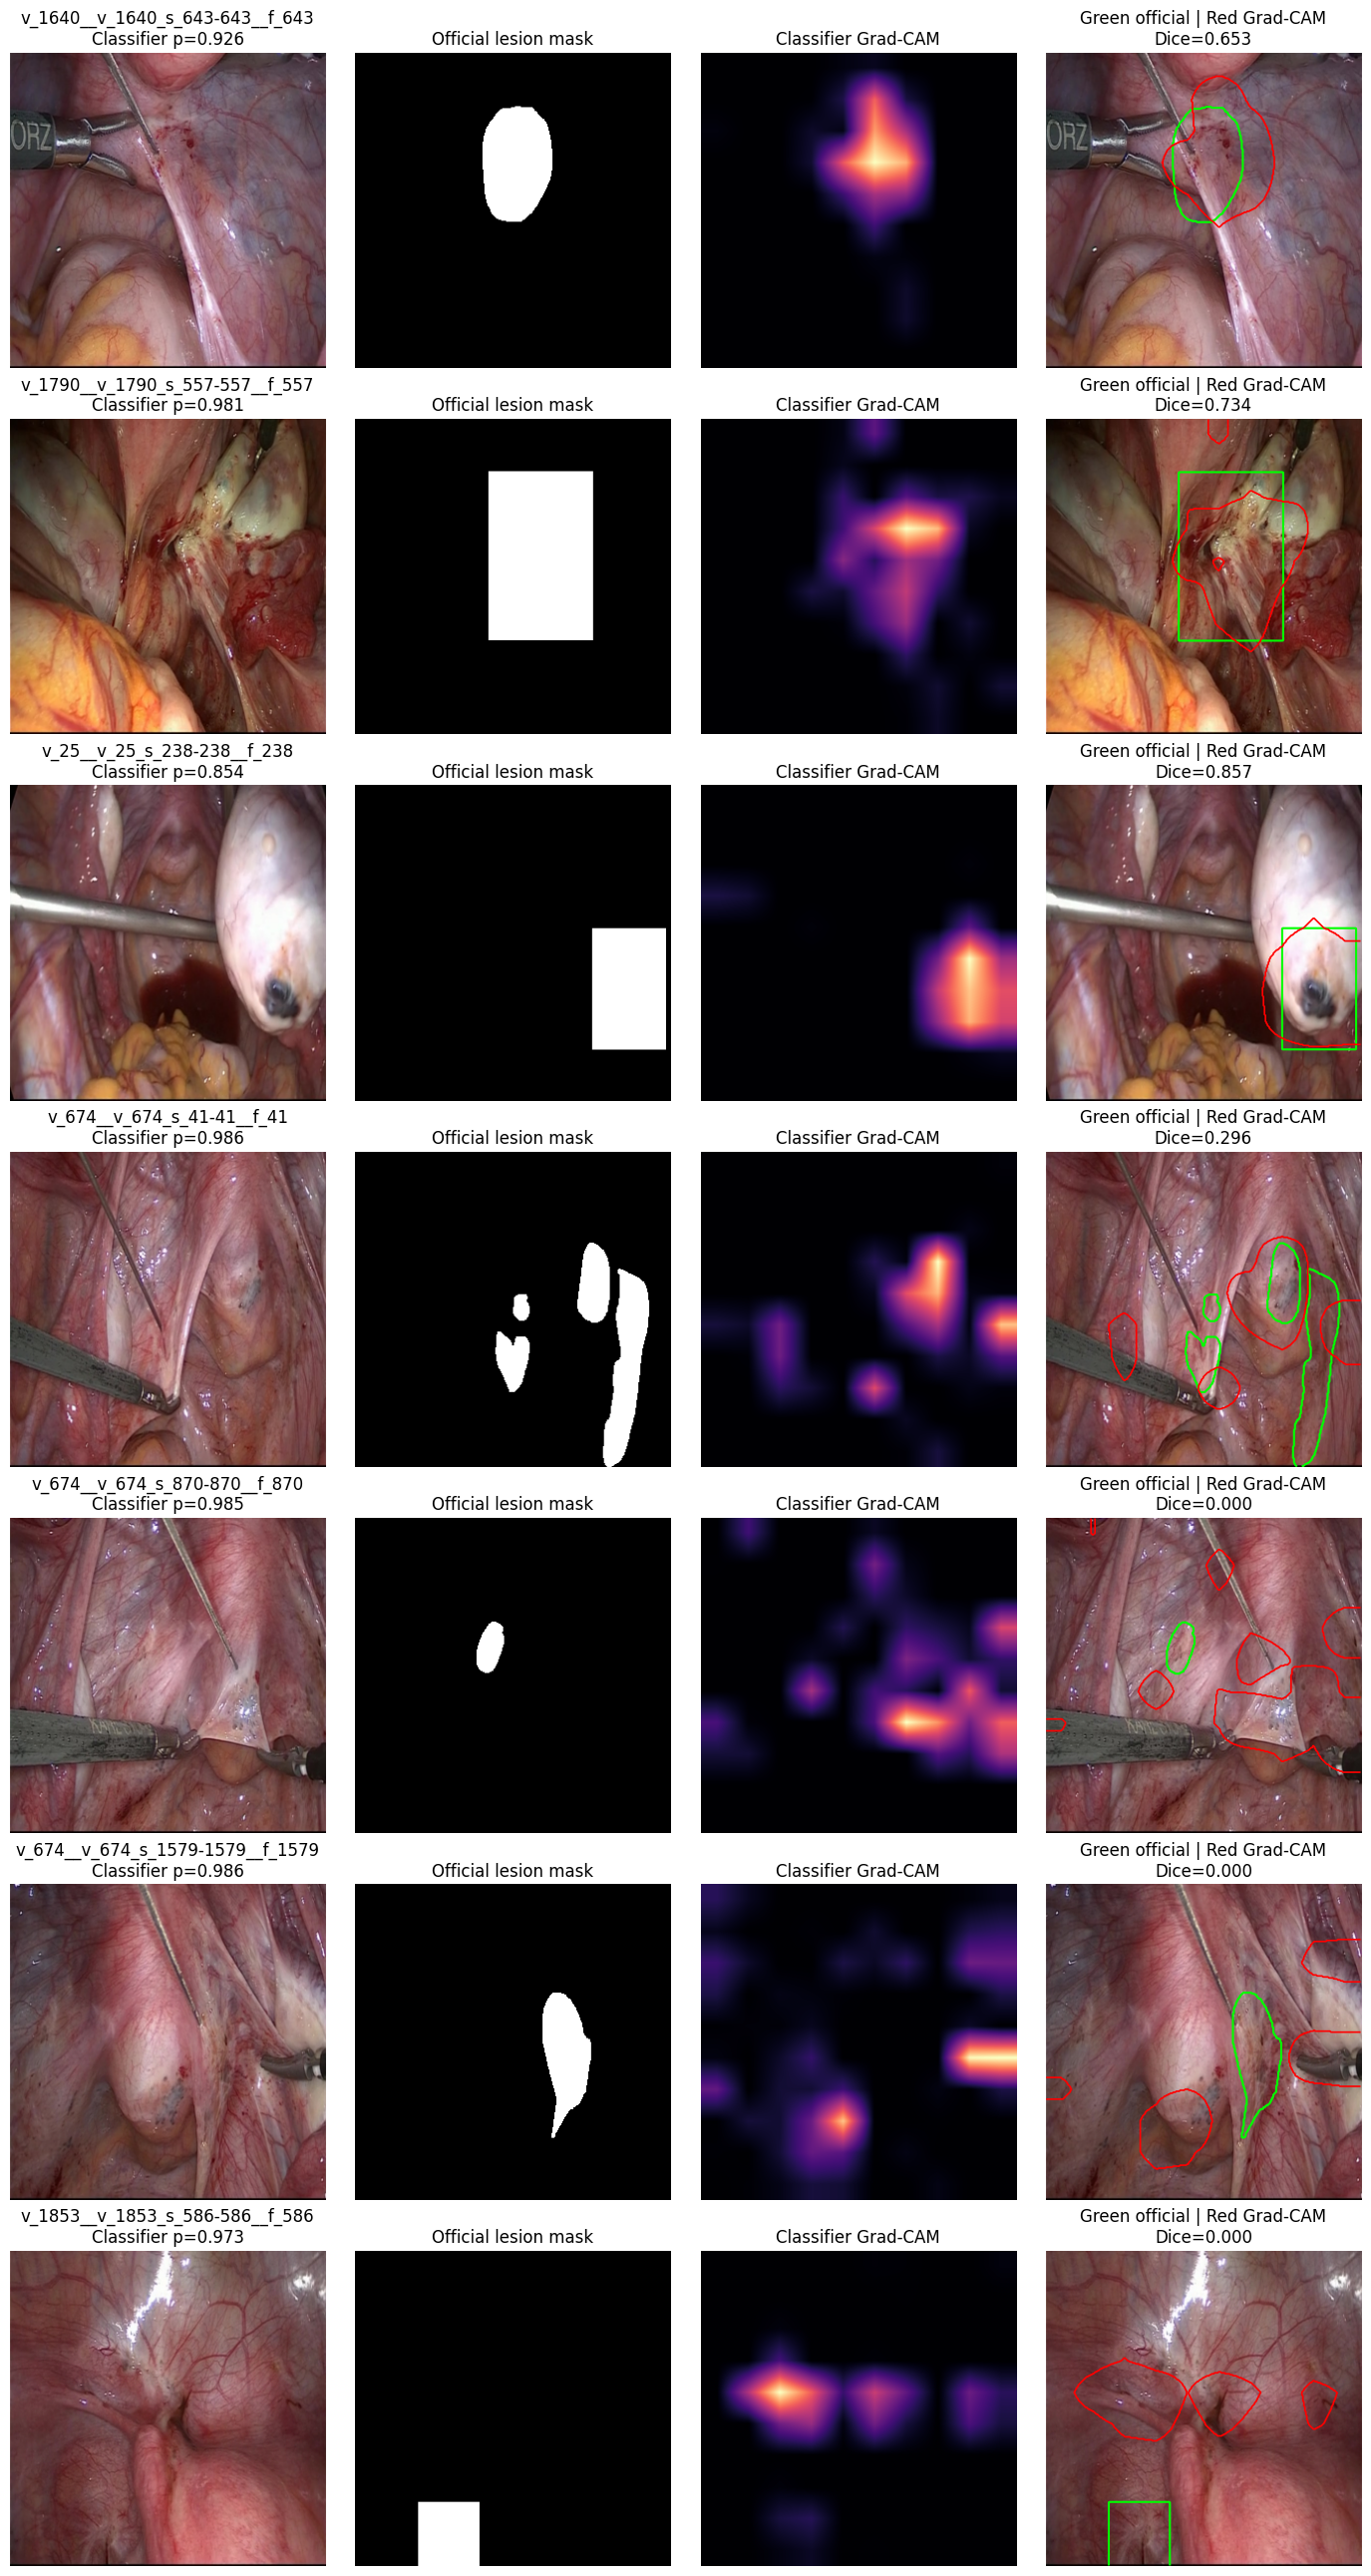


================ GRAD-CAM EVALUATION COMPLETE ================


,classifier_checkpoint_epoch,selected_gradcam_threshold_from_fold0_validation,mean_positive_gradcam_dice,median_positive_gradcam_dice,mean_positive_gradcam_iou,median_positive_gradcam_iou,mean_negative_gradcam_attention_fraction,validation_images,validation_pathology_images,validation_no_pathology_images,validation_videos,outer_test_used
0,3,0.2,0.284101,0.29574,0.181601,0.17353,0.170025,105,65,40,36,False



Grad-CAM threshold comparison:


,threshold,mean_positive_gradcam_dice,median_positive_gradcam_dice,mean_positive_gradcam_iou,median_positive_gradcam_iou
0,0.10,0.279199,0.273468,0.176375,0.158392
1,0.15,0.283230,0.285508,0.180150,0.166526
2,0.20,0.284101,0.295740,0.181601,0.173530
3,0.25,0.281842,0.278248,0.180785,0.161608
4,0.30,0.275098,0.259240,0.177059,0.148923
5,0.35,0.264496,0.249708,0.170269,0.142667
6,0.40,0.250509,0.229079,0.161455,0.129356
7,0.45,0.234971,0.210071,0.151434,0.117363
8,0.50,0.220818,0.169530,0.142633,0.092616
9,0.55,0.206995,0.129918,0.134015,0.069472



Saved:
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/gradcam_fold_0/gradcam_validation_per_image.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/gradcam_fold_0/gradcam_validation_threshold_comparison.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/gradcam_fold_0/gradcam_validation_summary.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/gradcam_fold_0/gradcam_validation_examples.png
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/gradcam_fold_0/gradcam_validation_summary.json

Important: this is Fold-0 validation analysis only.


In [ ]:
# ============================================================
# STEP 11 — FOLD-0 GRAD-CAM EXPLANATIONS AND MASK ALIGNMENT
#
# Uses:
#   - saved best EdgeNeXt classifier checkpoint (epoch 3)
#   - the same 105 held-out Fold-0 validation images
#   - official binary lesion masks
#
# Produces:
#   - Grad-CAM heatmaps
#   - classifier probabilities
#   - Grad-CAM-to-mask overlap metrics for pathology images
#   - visual examples
#
# No training. Safe after runtime disconnect.
# ============================================================

from google.colab import drive
from pathlib import Path
import sys
import subprocess
import importlib.util
import json

# ------------------------------------------------------------
# 1. Install packages missing after a Colab runtime reset
# ------------------------------------------------------------
required_packages = {
    "timm": "timm",
    "albumentations": "albumentations",
    "cv2": "opencv-python-headless",
    "pytorch_grad_cam": "grad-cam",
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing missing package: {package_name}")
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package_name]
        )

import cv2
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

# ------------------------------------------------------------
# 2. Paths
# ------------------------------------------------------------
PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

REPO_DIR = PROJECT_DIR / "baseline_repository" / "glenda-xai"
FOLD_DIR = PROJECT_DIR / "processed" / "fixed_folds" / "fold_0"

VALIDATION_CSV = FOLD_DIR / "classifier_validation.csv"

CLASSIFIER_CHECKPOINT = (
    PROJECT_DIR / "checkpoints" / "classifier_edgenext_fold_0"
    / "best_validation_auc.pt"
)

OUTPUT_DIR = PROJECT_DIR / "outputs" / "gradcam_fold_0"
HEATMAP_DIR = OUTPUT_DIR / "heatmaps"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
HEATMAP_DIR.mkdir(parents=True, exist_ok=True)

PER_IMAGE_CSV = OUTPUT_DIR / "gradcam_validation_per_image.csv"
THRESHOLDS_CSV = OUTPUT_DIR / "gradcam_validation_threshold_comparison.csv"
SUMMARY_CSV = OUTPUT_DIR / "gradcam_validation_summary.csv"
SUMMARY_JSON = OUTPUT_DIR / "gradcam_validation_summary.json"
EXAMPLES_FIGURE = OUTPUT_DIR / "gradcam_validation_examples.png"

assert REPO_DIR.exists(), f"Repository missing: {REPO_DIR}"
assert VALIDATION_CSV.exists(), f"Validation CSV missing: {VALIDATION_CSV}"
assert CLASSIFIER_CHECKPOINT.exists(), (
    f"Classifier checkpoint missing: {CLASSIFIER_CHECKPOINT}"
)

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from glenda.dataset import GlendaDataset
from glenda.models import make_model, get_default_target_layer

# ------------------------------------------------------------
# 3. Load validation data and classifier
# ------------------------------------------------------------
validation_metadata = pd.read_csv(VALIDATION_CSV)

assert len(validation_metadata) == 105
assert set(validation_metadata["label"].unique()) == {0, 1}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

dataset = GlendaDataset(
    validation_metadata,
    img_size=320,
    train=False,
    img_root="",
)

loader = DataLoader(
    dataset,
    batch_size=1,          # Grad-CAM is most reliable one image at a time
    shuffle=False,
    num_workers=0,
)

checkpoint = torch.load(
    CLASSIFIER_CHECKPOINT,
    map_location=device,
    weights_only=False,
)

model = make_model(
    name="edgenext_small",
    num_classes=2,
    pretrained=False,
).to(device)

model.load_state_dict(checkpoint["model_state"])
model.eval()

target_layer = get_default_target_layer(model, "edgenext_small")
assert target_layer is not None, "Could not find the classifier CAM layer."

print("Loaded classifier checkpoint from epoch:", checkpoint["completed_epoch"])
print("Grad-CAM target layer:", target_layer.__class__.__name__)

# ------------------------------------------------------------
# 4. Helper metrics
# ------------------------------------------------------------
def dice_score(prediction, target, epsilon=1e-6):
    intersection = np.logical_and(prediction, target).sum()
    total = prediction.sum() + target.sum()
    return float((2.0 * intersection + epsilon) / (total + epsilon))

def iou_score(prediction, target, epsilon=1e-6):
    intersection = np.logical_and(prediction, target).sum()
    union = np.logical_or(prediction, target).sum()
    return float((intersection + epsilon) / (union + epsilon))

# ------------------------------------------------------------
# 5. Generate a pathology-targeted Grad-CAM map per image
# ------------------------------------------------------------
records = []
heatmaps_by_id = {}

cam = GradCAM(model=model, target_layers=[target_layer])

for index, batch in enumerate(loader):
    sample_id = batch["path"][0]
    row = validation_metadata[
        validation_metadata["image_path"] == sample_id
    ].iloc[0]

    input_tensor = batch["image"].to(device)

    with torch.no_grad():
        logits = model(input_tensor)
        pathology_probability = float(
            torch.softmax(logits, dim=1)[0, 1].cpu()
        )

    # Target class 1 = pathology. This tells Grad-CAM:
    # "show evidence that increases the pathology score."
    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(1)],
    )[0]

    # Save map as a compact PNG, preserving values 0–255.
    heatmap_uint8 = np.clip(grayscale_cam * 255, 0, 255).astype(np.uint8)
    heatmap_path = HEATMAP_DIR / f"{row['sample_id']}_gradcam.png"
    Image.fromarray(heatmap_uint8).save(heatmap_path)

    heatmaps_by_id[row["sample_id"]] = grayscale_cam

    # Official binary mask, resized exactly as classifier input.
    with Image.open(row["image_path"]) as image:
        original_size = image.size

    # Find segmentation mask for exactly this image.
    segmentation_row = (
        pd.read_csv(
            PROJECT_DIR / "processed" / "fixed_folds" / "fold_0"
            / "segmentation_validation.csv"
        )
        .query("sample_id == @row.sample_id")
        .iloc[0]
    )

    with Image.open(segmentation_row["mask_path"]) as mask:
        assert mask.size == original_size
        mask = mask.convert("L").resize(
            (320, 320),
            resample=Image.Resampling.NEAREST,
        )
        official_mask = np.asarray(mask) > 0

    records.append(
        {
            "sample_id": row["sample_id"],
            "video_id": row["video_id"],
            "label": int(row["label"]),
            "classifier_pathology_probability": pathology_probability,
            "heatmap_path": str(heatmap_path),
            "official_mask_foreground_fraction": float(official_mask.mean()),
        }
    )

    if (index + 1) % 20 == 0 or (index + 1) == len(dataset):
        print(f"Generated/verified Grad-CAM {index + 1}/{len(dataset)}")

del cam

# ------------------------------------------------------------
# 6. Calculate Grad-CAM / official-mask overlap for positives
# ------------------------------------------------------------
per_image = pd.DataFrame(records)

segmentation_validation = pd.read_csv(
    PROJECT_DIR / "processed" / "fixed_folds" / "fold_0"
    / "segmentation_validation.csv"
)

per_image = per_image.merge(
    segmentation_validation[
        ["sample_id", "mask_path", "lesion_classes", "image_path"]
    ],
    on="sample_id",
    how="left",
    validate="one_to_one",
)

threshold_rows = []

for threshold in np.arange(0.10, 0.91, 0.05):
    dice_values = []
    iou_values = []

    for _, row in per_image[per_image["label"] == 1].iterrows():
        heatmap = heatmaps_by_id[row["sample_id"]]
        predicted_region = heatmap >= threshold

        with Image.open(row["mask_path"]) as mask:
            official_mask = np.asarray(
                mask.convert("L").resize(
                    (320, 320),
                    resample=Image.Resampling.NEAREST,
                )
            ) > 0

        dice_values.append(dice_score(predicted_region, official_mask))
        iou_values.append(iou_score(predicted_region, official_mask))

    threshold_rows.append(
        {
            "threshold": round(float(threshold), 2),
            "mean_positive_gradcam_dice": float(np.mean(dice_values)),
            "median_positive_gradcam_dice": float(np.median(dice_values)),
            "mean_positive_gradcam_iou": float(np.mean(iou_values)),
            "median_positive_gradcam_iou": float(np.median(iou_values)),
        }
    )

threshold_table = pd.DataFrame(threshold_rows)
selected_threshold = float(
    threshold_table.loc[
        threshold_table["mean_positive_gradcam_dice"].idxmax(),
        "threshold",
    ]
)

# Per-image overlap at selected Grad-CAM threshold.
selected_dice = []
selected_iou = []
selected_area = []

for _, row in per_image.iterrows():
    heatmap = heatmaps_by_id[row["sample_id"]]
    predicted_region = heatmap >= selected_threshold
    selected_area.append(float(predicted_region.mean()))

    if row["label"] == 1:
        with Image.open(row["mask_path"]) as mask:
            official_mask = np.asarray(
                mask.convert("L").resize(
                    (320, 320),
                    resample=Image.Resampling.NEAREST,
                )
            ) > 0

        selected_dice.append(dice_score(predicted_region, official_mask))
        selected_iou.append(iou_score(predicted_region, official_mask))
    else:
        selected_dice.append(np.nan)
        selected_iou.append(np.nan)

per_image["selected_gradcam_threshold"] = selected_threshold
per_image["gradcam_foreground_fraction"] = selected_area
per_image["gradcam_dice"] = selected_dice
per_image["gradcam_iou"] = selected_iou

per_image.to_csv(PER_IMAGE_CSV, index=False)
threshold_table.to_csv(THRESHOLDS_CSV, index=False)

positive_rows = per_image[per_image["label"] == 1]
negative_rows = per_image[per_image["label"] == 0]

summary = pd.DataFrame(
    [{
        "classifier_checkpoint_epoch": int(checkpoint["completed_epoch"]),
        "selected_gradcam_threshold_from_fold0_validation": selected_threshold,
        "mean_positive_gradcam_dice": float(positive_rows["gradcam_dice"].mean()),
        "median_positive_gradcam_dice": float(
            positive_rows["gradcam_dice"].median()
        ),
        "mean_positive_gradcam_iou": float(positive_rows["gradcam_iou"].mean()),
        "median_positive_gradcam_iou": float(
            positive_rows["gradcam_iou"].median()
        ),
        "mean_negative_gradcam_attention_fraction": float(
            negative_rows["gradcam_foreground_fraction"].mean()
        ),
        "validation_images": len(per_image),
        "validation_pathology_images": len(positive_rows),
        "validation_no_pathology_images": len(negative_rows),
        "validation_videos": int(per_image["video_id"].nunique()),
        "outer_test_used": False,
    }]
)

summary.to_csv(SUMMARY_CSV, index=False)

# ------------------------------------------------------------
# 7. Visual examples: best, middle, worst pathology maps
# ------------------------------------------------------------
positive_sorted = positive_rows.sort_values("gradcam_dice").reset_index(drop=True)

example_ids = (
    positive_sorted.tail(3)["sample_id"].tolist()
    + [positive_sorted.iloc[len(positive_sorted) // 2]["sample_id"]]
    + positive_sorted.head(3)["sample_id"].tolist()
)
example_ids = list(dict.fromkeys(example_ids))

fig, axes = plt.subplots(
    len(example_ids), 4, figsize=(14, 3.7 * len(example_ids))
)

for axis_row, sample_id in zip(axes, example_ids):
    row = per_image[per_image["sample_id"] == sample_id].iloc[0]

    with Image.open(row["image_path"]) as image:
        image = image.convert("RGB").resize(
            (320, 320),
            resample=Image.Resampling.BILINEAR,
        )
        image_array = np.asarray(image)

    with Image.open(row["mask_path"]) as mask:
        official_mask = np.asarray(
            mask.convert("L").resize(
                (320, 320),
                resample=Image.Resampling.NEAREST,
            )
        ) > 0

    heatmap = heatmaps_by_id[sample_id]
    heatmap_region = heatmap >= selected_threshold

    axis_row[0].imshow(image_array)
    axis_row[0].set_title(
        f"{sample_id}\nClassifier p={row['classifier_pathology_probability']:.3f}"
    )
    axis_row[0].axis("off")

    axis_row[1].imshow(official_mask, cmap="gray", vmin=0, vmax=1)
    axis_row[1].set_title("Official lesion mask")
    axis_row[1].axis("off")

    axis_row[2].imshow(heatmap, cmap="magma", vmin=0, vmax=1)
    axis_row[2].set_title("Classifier Grad-CAM")
    axis_row[2].axis("off")

    axis_row[3].imshow(image_array)
    axis_row[3].contour(official_mask, colors="lime", linewidths=1.5)
    if heatmap_region.any():
        axis_row[3].contour(heatmap_region, colors="red", linewidths=1.2)
    axis_row[3].set_title(
        "Green official | Red Grad-CAM\n"
        f"Dice={row['gradcam_dice']:.3f}"
    )
    axis_row[3].axis("off")

plt.tight_layout()
plt.savefig(EXAMPLES_FIGURE, dpi=180, bbox_inches="tight")
plt.show()

summary_dict = summary.iloc[0].to_dict()
summary_dict["classifier_checkpoint"] = str(CLASSIFIER_CHECKPOINT)
summary_dict["per_image_results"] = str(PER_IMAGE_CSV)
summary_dict["threshold_results"] = str(THRESHOLDS_CSV)

with open(SUMMARY_JSON, "w", encoding="utf-8") as file:
    json.dump(summary_dict, file, indent=2)

print("\n================ GRAD-CAM EVALUATION COMPLETE ================")
display(summary)

print("\nGrad-CAM threshold comparison:")
display(threshold_table)

print("\nSaved:")
print("-", PER_IMAGE_CSV)
print("-", THRESHOLDS_CSV)
print("-", SUMMARY_CSV)
print("-", EXAMPLES_FIGURE)
print("-", SUMMARY_JSON)

print("\nImportant: this is Fold-0 validation analysis only.")

Drive already mounted at /content/project_drive_2026; to attempt to forcibly remount, call drive.mount("/content/project_drive_2026", force_remount=True).


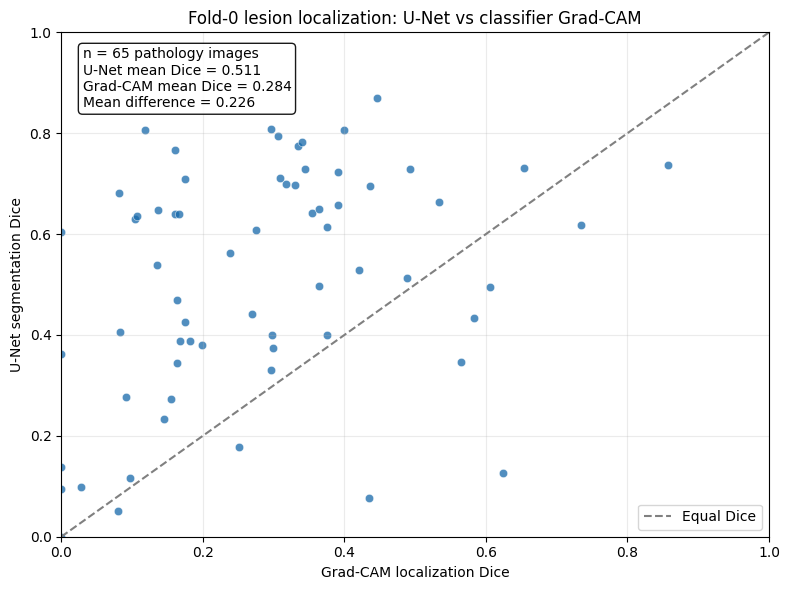

================ FOLD-0 METHOD COMPARISON COMPLETE ================



,fold,shared_unseen_pathology_images,shared_unseen_videos,unet_mean_dice,unet_median_dice,gradcam_mean_dice,gradcam_median_dice,mean_dice_difference_unet_minus_gradcam,bootstrap_95ci_low_mean_dice_difference,bootstrap_95ci_high_mean_dice_difference,unet_better_dice_cases,gradcam_better_dice_cases,tied_dice_cases,exploratory_one_sided_wilcoxon_p_value,important_interpretation
0,0,65,33,0.510575,0.562594,0.284101,0.29574,0.226474,0.167844,0.283339,56,9,0,8.682989e-09,Fold-0 validation comparison only. Both thresh...



Saved:
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/fold_0_method_comparison/fold0_paired_localization_comparison.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/fold_0_method_comparison/fold0_localization_comparison_summary.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/fold_0_method_comparison/fold0_unet_vs_gradcam_localization.png
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/fold_0_method_comparison/fold0_localization_comparison_summary.json

Important: this is an exploratory Fold-0 comparison.
We will repeat the same protocol across Folds 1–4 before
reporting a final cross-validation result.


In [ ]:
# ============================================================
# STEP 12 — DIRECT FOLD-0 COMPARISON:
#            U-NET SEGMENTATION vs CLASSIFIER GRAD-CAM
#
# Compares exact-lesion localization on the same 65 unseen
# pathology images from the fixed Fold-0 validation set.
#
# No training. No new inference. CPU-safe and quick.
# ============================================================

from google.colab import drive
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

UNET_DIR = PROJECT_DIR / "outputs" / "segmentation_unet_fold_0"
GRADCAM_DIR = PROJECT_DIR / "outputs" / "gradcam_fold_0"

UNET_PREDICTIONS = UNET_DIR / "best_unet_validation_predictions.csv"
GRADCAM_PREDICTIONS = GRADCAM_DIR / "gradcam_validation_per_image.csv"

OUTPUT_DIR = PROJECT_DIR / "outputs" / "fold_0_method_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

COMPARISON_CSV = OUTPUT_DIR / "fold0_paired_localization_comparison.csv"
SUMMARY_CSV = OUTPUT_DIR / "fold0_localization_comparison_summary.csv"
SUMMARY_JSON = OUTPUT_DIR / "fold0_localization_comparison_summary.json"
FIGURE_PATH = OUTPUT_DIR / "fold0_unet_vs_gradcam_localization.png"

assert UNET_PREDICTIONS.exists(), f"Missing: {UNET_PREDICTIONS}"
assert GRADCAM_PREDICTIONS.exists(), f"Missing: {GRADCAM_PREDICTIONS}"

unet = pd.read_csv(UNET_PREDICTIONS)
gradcam = pd.read_csv(GRADCAM_PREDICTIONS)

# Keep pathology images only: localization Dice is defined against lesions.
unet_positive = unet[unet["image_label"] == 1][
    ["sample_id", "video_id", "lesion_classes", "dice", "iou"]
].rename(
    columns={
        "dice": "unet_dice",
        "iou": "unet_iou",
    }
)

gradcam_positive = gradcam[gradcam["label"] == 1][
    [
        "sample_id",
        "classifier_pathology_probability",
        "gradcam_dice",
        "gradcam_iou",
    ]
]

paired = unet_positive.merge(
    gradcam_positive,
    on="sample_id",
    how="inner",
    validate="one_to_one",
)

assert len(paired) == 65, (
    f"Expected 65 shared pathology validation images, found {len(paired)}"
)
assert paired[["unet_dice", "gradcam_dice"]].notna().all().all()

paired["dice_difference_unet_minus_gradcam"] = (
    paired["unet_dice"] - paired["gradcam_dice"]
)
paired["iou_difference_unet_minus_gradcam"] = (
    paired["unet_iou"] - paired["gradcam_iou"]
)

paired.to_csv(COMPARISON_CSV, index=False)

# Paired, non-parametric test: appropriate for Dice distributions.
wilcoxon_result = wilcoxon(
    paired["unet_dice"],
    paired["gradcam_dice"],
    alternative="greater",
    zero_method="wilcox",
)

# Simple bootstrap confidence interval for mean Dice difference.
rng = np.random.default_rng(2026)
differences = paired["dice_difference_unet_minus_gradcam"].to_numpy()

bootstrap_means = np.array([
    rng.choice(differences, size=len(differences), replace=True).mean()
    for _ in range(5000)
])

ci_low, ci_high = np.quantile(bootstrap_means, [0.025, 0.975])

summary = pd.DataFrame([{
    "fold": 0,
    "shared_unseen_pathology_images": len(paired),
    "shared_unseen_videos": int(paired["video_id"].nunique()),
    "unet_mean_dice": float(paired["unet_dice"].mean()),
    "unet_median_dice": float(paired["unet_dice"].median()),
    "gradcam_mean_dice": float(paired["gradcam_dice"].mean()),
    "gradcam_median_dice": float(paired["gradcam_dice"].median()),
    "mean_dice_difference_unet_minus_gradcam": float(differences.mean()),
    "bootstrap_95ci_low_mean_dice_difference": float(ci_low),
    "bootstrap_95ci_high_mean_dice_difference": float(ci_high),
    "unet_better_dice_cases": int((differences > 0).sum()),
    "gradcam_better_dice_cases": int((differences < 0).sum()),
    "tied_dice_cases": int((differences == 0).sum()),
    "exploratory_one_sided_wilcoxon_p_value": float(wilcoxon_result.pvalue),
    "important_interpretation": (
        "Fold-0 validation comparison only. Both thresholds were selected "
        "on Fold-0 validation, so this is exploratory and must be repeated "
        "across folds before making a final claim."
    ),
}])

summary.to_csv(SUMMARY_CSV, index=False)

# ------------------------------------------------------------
# Publication-style visual comparison
# ------------------------------------------------------------
plt.figure(figsize=(8, 6))

plt.scatter(
    paired["gradcam_dice"],
    paired["unet_dice"],
    alpha=0.75,
    color="#1769aa",
    edgecolor="white",
    linewidth=0.4,
)

plt.plot([0, 1], [0, 1], "--", color="gray", label="Equal Dice")

plt.xlabel("Grad-CAM localization Dice")
plt.ylabel("U-Net segmentation Dice")
plt.title("Fold-0 lesion localization: U-Net vs classifier Grad-CAM")

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()

text = (
    f"n = {len(paired)} pathology images\n"
    f"U-Net mean Dice = {paired['unet_dice'].mean():.3f}\n"
    f"Grad-CAM mean Dice = {paired['gradcam_dice'].mean():.3f}\n"
    f"Mean difference = {differences.mean():.3f}"
)

plt.gca().text(
    0.03,
    0.97,
    text,
    transform=plt.gca().transAxes,
    va="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.9),
)

plt.tight_layout()
plt.savefig(FIGURE_PATH, dpi=200, bbox_inches="tight")
plt.show()

summary_dict = summary.iloc[0].to_dict()
summary_dict["paired_results_path"] = str(COMPARISON_CSV)
summary_dict["figure_path"] = str(FIGURE_PATH)

with open(SUMMARY_JSON, "w", encoding="utf-8") as file:
    json.dump(summary_dict, file, indent=2)

print("================ FOLD-0 METHOD COMPARISON COMPLETE ================\n")
display(summary)

print("\nSaved:")
print("-", COMPARISON_CSV)
print("-", SUMMARY_CSV)
print("-", FIGURE_PATH)
print("-", SUMMARY_JSON)

print("\nImportant: this is an exploratory Fold-0 comparison.")
print("We will repeat the same protocol across Folds 1–4 before")
print("reporting a final cross-validation result.")

Drive already mounted at /content/project_drive_2026; to attempt to forcibly remount, call drive.mount("/content/project_drive_2026", force_remount=True).


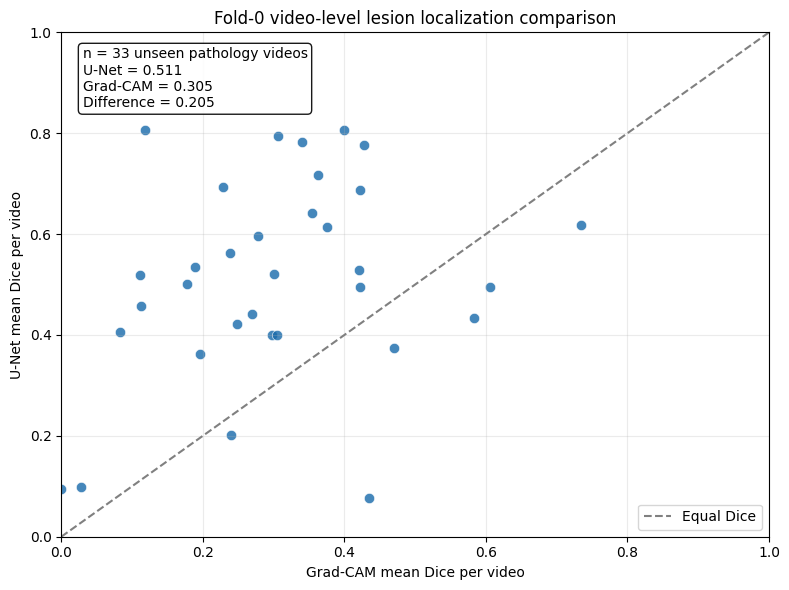

================ VIDEO-LEVEL COMPARISON COMPLETE ================



,fold,independent_unit,held_out_pathology_videos,held_out_pathology_frames,unet_mean_video_dice,gradcam_mean_video_dice,mean_video_dice_difference_unet_minus_gradcam,bootstrap_95ci_low_video_mean_difference,bootstrap_95ci_high_video_mean_difference,unet_better_videos,gradcam_better_videos,tied_videos,one_sided_video_level_wilcoxon_p_value,interpretation
0,0,video_id,33,65,0.510813,0.305448,0.205366,0.128966,0.280183,27,6,0,0.000017,Exploratory Fold-0 comparison. Statistics use ...



Saved:
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/fold_0_method_comparison/fold0_video_level_localization_comparison.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/fold_0_method_comparison/fold0_video_level_localization_summary.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/fold_0_method_comparison/fold0_video_level_unet_vs_gradcam.png
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/fold_0_method_comparison/fold0_video_level_localization_summary.json

This is now the correct Fold-0 statistical comparison.
Final conclusions still require repeating the pipeline on Folds 1–4.


In [ ]:
# ============================================================
# STEP 12B — VIDEO-LEVEL FOLD-0 METHOD COMPARISON
#
# Corrects the statistics for correlated video frames:
# each video contributes one average Dice value.
#
# No training. No inference. CPU-safe.
# ============================================================

from google.colab import drive
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

INPUT_CSV = (
    PROJECT_DIR / "outputs" / "fold_0_method_comparison"
    / "fold0_paired_localization_comparison.csv"
)

OUTPUT_DIR = PROJECT_DIR / "outputs" / "fold_0_method_comparison"
VIDEO_RESULTS_CSV = OUTPUT_DIR / "fold0_video_level_localization_comparison.csv"
VIDEO_SUMMARY_CSV = OUTPUT_DIR / "fold0_video_level_localization_summary.csv"
VIDEO_SUMMARY_JSON = OUTPUT_DIR / "fold0_video_level_localization_summary.json"
VIDEO_FIGURE = OUTPUT_DIR / "fold0_video_level_unet_vs_gradcam.png"

assert INPUT_CSV.exists(), f"Missing paired results: {INPUT_CSV}"

frame_results = pd.read_csv(INPUT_CSV)

required = {"video_id", "unet_dice", "gradcam_dice"}
assert required.issubset(frame_results.columns)

# One average score per held-out pathology video.
video_results = (
    frame_results
    .groupby("video_id", as_index=False)
    .agg(
        pathology_frames=("sample_id", "count"),
        unet_mean_dice=("unet_dice", "mean"),
        gradcam_mean_dice=("gradcam_dice", "mean"),
        unet_median_dice=("unet_dice", "median"),
        gradcam_median_dice=("gradcam_dice", "median"),
    )
)

video_results["dice_difference_unet_minus_gradcam"] = (
    video_results["unet_mean_dice"]
    - video_results["gradcam_mean_dice"]
)

assert len(video_results) == 33, (
    f"Expected 33 held-out pathology videos, found {len(video_results)}"
)

differences = video_results[
    "dice_difference_unet_minus_gradcam"
].to_numpy()

# Paired test at the correct independent unit: video.
wilcoxon_result = wilcoxon(
    video_results["unet_mean_dice"],
    video_results["gradcam_mean_dice"],
    alternative="greater",
    zero_method="wilcox",
)

# Bootstrap resamples videos, not individual frames.
rng = np.random.default_rng(2026)
bootstrap_means = np.array([
    rng.choice(differences, size=len(differences), replace=True).mean()
    for _ in range(5000)
])

ci_low, ci_high = np.quantile(bootstrap_means, [0.025, 0.975])

video_results.to_csv(VIDEO_RESULTS_CSV, index=False)

summary = pd.DataFrame([{
    "fold": 0,
    "independent_unit": "video_id",
    "held_out_pathology_videos": len(video_results),
    "held_out_pathology_frames": int(video_results["pathology_frames"].sum()),
    "unet_mean_video_dice": float(video_results["unet_mean_dice"].mean()),
    "gradcam_mean_video_dice": float(
        video_results["gradcam_mean_dice"].mean()
    ),
    "mean_video_dice_difference_unet_minus_gradcam": float(
        differences.mean()
    ),
    "bootstrap_95ci_low_video_mean_difference": float(ci_low),
    "bootstrap_95ci_high_video_mean_difference": float(ci_high),
    "unet_better_videos": int((differences > 0).sum()),
    "gradcam_better_videos": int((differences < 0).sum()),
    "tied_videos": int((differences == 0).sum()),
    "one_sided_video_level_wilcoxon_p_value": float(
        wilcoxon_result.pvalue
    ),
    "interpretation": (
        "Exploratory Fold-0 comparison. Statistics use video-level "
        "aggregation to avoid treating correlated frames as independent."
    ),
}])

summary.to_csv(VIDEO_SUMMARY_CSV, index=False)

# Video-level scatter plot.
plt.figure(figsize=(8, 6))

plt.scatter(
    video_results["gradcam_mean_dice"],
    video_results["unet_mean_dice"],
    s=55,
    alpha=0.8,
    color="#1769aa",
    edgecolor="white",
    linewidth=0.5,
)

plt.plot([0, 1], [0, 1], "--", color="gray", label="Equal Dice")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("Grad-CAM mean Dice per video")
plt.ylabel("U-Net mean Dice per video")
plt.title("Fold-0 video-level lesion localization comparison")
plt.grid(alpha=0.25)
plt.legend()

plt.gca().text(
    0.03,
    0.97,
    (
        f"n = {len(video_results)} unseen pathology videos\n"
        f"U-Net = {video_results['unet_mean_dice'].mean():.3f}\n"
        f"Grad-CAM = {video_results['gradcam_mean_dice'].mean():.3f}\n"
        f"Difference = {differences.mean():.3f}"
    ),
    transform=plt.gca().transAxes,
    va="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.9),
)

plt.tight_layout()
plt.savefig(VIDEO_FIGURE, dpi=200, bbox_inches="tight")
plt.show()

summary_dict = summary.iloc[0].to_dict()
summary_dict["video_results_path"] = str(VIDEO_RESULTS_CSV)
summary_dict["figure_path"] = str(VIDEO_FIGURE)

with open(VIDEO_SUMMARY_JSON, "w", encoding="utf-8") as file:
    json.dump(summary_dict, file, indent=2)

print("================ VIDEO-LEVEL COMPARISON COMPLETE ================\n")
display(summary)

print("\nSaved:")
print("-", VIDEO_RESULTS_CSV)
print("-", VIDEO_SUMMARY_CSV)
print("-", VIDEO_FIGURE)
print("-", VIDEO_SUMMARY_JSON)

print("\nThis is now the correct Fold-0 statistical comparison.")
print("Final conclusions still require repeating the pipeline on Folds 1–4.")

In [ ]:
# ============================================================
# STEP 13 — PREPARE FIXED FOLD-1 DATA FOR BOTH MODELS
# No GPU. No training.
# ============================================================

from google.colab import drive
from pathlib import Path
import json
import pandas as pd

try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

SPLIT_MANIFEST = (
    PROJECT_DIR / "processed" / "manifests"
    / "glenda_video_level_5fold_splits.csv"
)

FOLD = 1
FOLD_DIR = PROJECT_DIR / "processed" / "fixed_folds" / f"fold_{FOLD}"
FOLD_DIR.mkdir(parents=True, exist_ok=True)

assert SPLIT_MANIFEST.exists(), f"Missing: {SPLIT_MANIFEST}"

data = pd.read_csv(SPLIT_MANIFEST)

train = data[data["validation_fold"] != FOLD].copy()
validation = data[data["validation_fold"] == FOLD].copy()

assert set(train["video_id"]).isdisjoint(set(validation["video_id"]))
assert set(train["binary_label"].unique()) == {0, 1}
assert set(validation["binary_label"].unique()) == {0, 1}

# Classifier metadata: compatible with the published repository.
classifier_train = pd.DataFrame({
    "image_path": train["image_path"],
    "label": train["binary_label"].astype(int),
    "patient_id": train["video_id"].astype(str),
    "video_id": train["video_id"].astype(str),
    "sample_id": train["sample_id"],
    "fold_role": "train",
})

classifier_validation = pd.DataFrame({
    "image_path": validation["image_path"],
    "label": validation["binary_label"].astype(int),
    "patient_id": validation["video_id"].astype(str),
    "video_id": validation["video_id"].astype(str),
    "sample_id": validation["sample_id"],
    "fold_role": "validation",
})

# Segmentation metadata: image plus official binary lesion mask.
segmentation_columns = [
    "sample_id", "image_path", "binary_mask_path", "binary_label",
    "video_id", "sequence_id", "frame_id", "lesion_classes",
]

segmentation_train = train[segmentation_columns].rename(columns={
    "binary_mask_path": "mask_path",
    "binary_label": "image_label",
})

segmentation_validation = validation[segmentation_columns].rename(columns={
    "binary_mask_path": "mask_path",
    "binary_label": "image_label",
})

# Check every selected file is present.
for table in [
    classifier_train, classifier_validation,
    segmentation_train, segmentation_validation,
]:
    assert table["image_path"].map(lambda p: Path(p).exists()).all()

for table in [segmentation_train, segmentation_validation]:
    assert table["mask_path"].map(lambda p: Path(p).exists()).all()

# Save stable Fold-1 files.
classifier_train.to_csv(FOLD_DIR / "classifier_train.csv", index=False)
classifier_validation.to_csv(FOLD_DIR / "classifier_validation.csv", index=False)
segmentation_train.to_csv(FOLD_DIR / "segmentation_train.csv", index=False)
segmentation_validation.to_csv(
    FOLD_DIR / "segmentation_validation.csv", index=False
)

summary = pd.DataFrame([
    {
        "role": "training",
        "images": len(train),
        "pathology_images": int(train["binary_label"].sum()),
        "no_pathology_images": int((train["binary_label"] == 0).sum()),
        "videos": train["video_id"].nunique(),
    },
    {
        "role": "validation",
        "images": len(validation),
        "pathology_images": int(validation["binary_label"].sum()),
        "no_pathology_images": int((validation["binary_label"] == 0).sum()),
        "videos": validation["video_id"].nunique(),
    },
])

protocol = {
    "fold": FOLD,
    "training_folds": [0, 2, 3, 4],
    "validation_fold": FOLD,
    "split_unit": "video_id",
    "outer_test_used": False,
    "leakage_check_passed": True,
}

with open(FOLD_DIR / "fold_1_protocol.json", "w") as file:
    json.dump(protocol, file, indent=2)

print("================ FOLD-1 DATA PREPARATION COMPLETE ================\n")
display(summary)

print("\nSaved to:", FOLD_DIR)
print("PASSED: Fold 1 is ready for classifier training.")

Drive already mounted at /content/project_drive_2026; to attempt to forcibly remount, call drive.mount("/content/project_drive_2026", force_remount=True).
================ FOLD-1 DATA PREPARATION COMPLETE ================



,role,images,pathology_images,no_pathology_images,videos
0,training,474,254,220,148
1,validation,98,48,50,36



Saved to: /content/project_drive_2026/MyDrive/glenda_xai_localization/processed/fixed_folds/fold_1
PASSED: Fold 1 is ready for classifier training.


In [ ]:
# ============================================================
# STEP 14 — CHECKPOINTED FOLD-1 CLASSIFIER TRAINING
#
# Model: ImageNet-pretrained EdgeNeXt-Small
# Task: pathology (1) vs no-pathology (0)
# Split: fixed video-level Fold-1 split
#
# CPU or GPU safe. Saves every completed epoch to Drive.
# ============================================================

from google.colab import drive
from pathlib import Path
import sys
import subprocess
import importlib.util
import json
import random
import time

# Reinstall packages only if this Colab runtime was reset.
required_packages = {
    "timm": "timm",
    "albumentations": "albumentations",
    "cv2": "opencv-python-headless",
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing missing package: {package_name}")
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package_name]
        )

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
SEED = 2026

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

# ------------------------------------------------------------
# Paths and settings
# ------------------------------------------------------------
PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

REPO_DIR = PROJECT_DIR / "baseline_repository" / "glenda-xai"
FOLD = 1
FOLD_DIR = PROJECT_DIR / "processed" / "fixed_folds" / f"fold_{FOLD}"

TRAIN_CSV = FOLD_DIR / "classifier_train.csv"
VALIDATION_CSV = FOLD_DIR / "classifier_validation.csv"

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints" / f"classifier_edgenext_fold_{FOLD}"
)
OUTPUT_DIR = PROJECT_DIR / "outputs" / f"classifier_fold_{FOLD}"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LAST_CHECKPOINT = CHECKPOINT_DIR / "last_checkpoint.pt"
BEST_CHECKPOINT = CHECKPOINT_DIR / "best_validation_auc.pt"
HISTORY_CSV = OUTPUT_DIR / "classifier_training_history.csv"
CONFIG_JSON = OUTPUT_DIR / "classifier_training_configuration.json"

assert REPO_DIR.exists()
assert TRAIN_CSV.exists()
assert VALIDATION_CSV.exists()

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from glenda.dataset import GlendaDataset
from glenda.models import make_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Keep the same protocol as Fold 0.
EPOCHS_THIS_RUN = 20
MAX_TOTAL_EPOCHS = 20
BATCH_SIZE = 16 if device.type == "cuda" else 8
IMAGE_SIZE = 320
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 5

print("Device:", device)
print("Epochs in this run:", EPOCHS_THIS_RUN)
print("Maximum total epochs:", MAX_TOTAL_EPOCHS)
print("Batch size:", BATCH_SIZE)

# ------------------------------------------------------------
# Load the fixed Fold-1 split
# ------------------------------------------------------------
train_metadata = pd.read_csv(TRAIN_CSV)
validation_metadata = pd.read_csv(VALIDATION_CSV)

assert set(train_metadata["video_id"]).isdisjoint(
    set(validation_metadata["video_id"])
), "Video leakage detected."

assert set(train_metadata["label"].unique()) == {0, 1}
assert set(validation_metadata["label"].unique()) == {0, 1}

print(
    "Training images:", len(train_metadata),
    "| pathology:", int(train_metadata["label"].sum()),
    "| no-pathology:", int((train_metadata["label"] == 0).sum()),
)
print(
    "Validation images:", len(validation_metadata),
    "| pathology:", int(validation_metadata["label"].sum()),
    "| no-pathology:", int((validation_metadata["label"] == 0).sum()),
)
print("Outer-test videos used during training: 0")

train_dataset = GlendaDataset(
    train_metadata, img_size=IMAGE_SIZE, train=True, img_root=""
)
validation_dataset = GlendaDataset(
    validation_metadata, img_size=IMAGE_SIZE, train=False, img_root=""
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

# ------------------------------------------------------------
# Model, weighted loss, and optimiser
# ------------------------------------------------------------
resuming = LAST_CHECKPOINT.exists()

model = make_model(
    name="edgenext_small",
    num_classes=2,
    pretrained=not resuming,
).to(device)

class_counts = train_metadata["label"].value_counts().to_dict()
class_weights = torch.tensor(
    [
        1.0 / class_counts.get(0, 1),
        1.0 / class_counts.get(1, 1),
    ],
    dtype=torch.float32,
)
class_weights = (class_weights / class_weights.mean()).to(device)

criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.03,
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=MAX_TOTAL_EPOCHS,
)

def move_optimizer_state_to_device(optimizer, target_device):
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(target_device)

def evaluate_classifier():
    model.eval()
    labels_all = []
    probabilities_all = []
    total_loss = 0.0
    total_images = 0

    with torch.no_grad():
        for batch in validation_loader:
            images = batch["image"].to(device, non_blocking=True)
            labels = batch["label"].to(device, non_blocking=True)

            logits = model(images)
            loss = criterion(logits, labels)
            probabilities = torch.softmax(logits, dim=1)[:, 1]

            total_loss += float(loss.item()) * len(labels)
            total_images += len(labels)

            labels_all.extend(labels.cpu().numpy().tolist())
            probabilities_all.extend(probabilities.cpu().numpy().tolist())

    labels_all = np.asarray(labels_all)
    probabilities_all = np.asarray(probabilities_all)
    predictions_all = (probabilities_all >= 0.5).astype(int)

    return {
        "validation_loss": total_loss / max(total_images, 1),
        "validation_auc": float(roc_auc_score(labels_all, probabilities_all)),
        "validation_accuracy": float(
            accuracy_score(labels_all, predictions_all)
        ),
        "validation_balanced_accuracy": float(
            balanced_accuracy_score(labels_all, predictions_all)
        ),
        "validation_f1": float(
            f1_score(labels_all, predictions_all, zero_division=0)
        ),
    }

def save_checkpoint_safely(path, data):
    temporary_path = path.with_suffix(path.suffix + ".temporary")
    torch.save(data, temporary_path)
    temporary_path.replace(path)

# ------------------------------------------------------------
# Resume safely if needed
# ------------------------------------------------------------
history = []
best_validation_auc = -float("inf")
completed_epoch = 0
epochs_without_improvement = 0

if resuming:
    checkpoint = torch.load(
        LAST_CHECKPOINT, map_location=device, weights_only=False
    )

    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])
    move_optimizer_state_to_device(optimizer, device)
    scheduler.load_state_dict(checkpoint["scheduler_state"])

    completed_epoch = int(checkpoint["completed_epoch"])
    best_validation_auc = float(checkpoint["best_validation_auc"])
    epochs_without_improvement = int(
        checkpoint.get("epochs_without_improvement", 0)
    )
    history = checkpoint.get("history", [])

    print(
        f"Resuming after epoch {completed_epoch}. "
        f"Best validation AUC: {best_validation_auc:.4f}"
    )
else:
    print("Starting a new ImageNet-pretrained Fold-1 classifier run.")

target_epoch = min(
    completed_epoch + EPOCHS_THIS_RUN,
    MAX_TOTAL_EPOCHS,
)

# ------------------------------------------------------------
# Train, validate, and checkpoint every epoch
# ------------------------------------------------------------
for epoch in range(completed_epoch + 1, target_epoch + 1):
    epoch_start = time.time()

    model.train()
    training_loss_sum = 0.0
    training_images = 0

    for batch in train_loader:
        images = batch["image"].to(device, non_blocking=True)
        labels = batch["label"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        training_loss_sum += float(loss.item()) * len(labels)
        training_images += len(labels)

    scheduler.step()

    metrics = evaluate_classifier()

    record = {
        "epoch": epoch,
        "training_loss": training_loss_sum / max(training_images, 1),
        "learning_rate": optimizer.param_groups[0]["lr"],
        **metrics,
        "epoch_minutes": (time.time() - epoch_start) / 60.0,
    }

    history = [
        item for item in history
        if int(item.get("epoch", -1)) != epoch
    ]
    history.append(record)
    history = sorted(history, key=lambda item: int(item["epoch"]))

    improved = record["validation_auc"] > best_validation_auc

    if improved:
        best_validation_auc = record["validation_auc"]
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    checkpoint_data = {
        "model_name": "edgenext_small",
        "initialization": "ImageNet pretrained",
        "fold": FOLD,
        "completed_epoch": epoch,
        "best_validation_auc": best_validation_auc,
        "epochs_without_improvement": epochs_without_improvement,
        "model_state": {
            key: value.detach().cpu()
            for key, value in model.state_dict().items()
        },
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "history": history,
        "outer_test_used": False,
    }

    save_checkpoint_safely(LAST_CHECKPOINT, checkpoint_data)

    if improved:
        save_checkpoint_safely(BEST_CHECKPOINT, checkpoint_data)

    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)

    print(
        f"Epoch {epoch:02d}/{MAX_TOTAL_EPOCHS} | "
        f"train loss={record['training_loss']:.4f} | "
        f"val AUC={record['validation_auc']:.4f} | "
        f"val balanced accuracy={record['validation_balanced_accuracy']:.4f} | "
        f"time={record['epoch_minutes']:.1f} min | "
        f"{'BEST checkpoint saved' if improved else 'checkpoint saved'}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"Early stopping: no validation-AUC improvement for "
            f"{PATIENCE} consecutive epochs."
        )
        break

# ------------------------------------------------------------
# Save settings
# ------------------------------------------------------------
config = {
    "fold": FOLD,
    "model": "EdgeNeXt-Small",
    "initialization": "ImageNet pretrained",
    "split_unit": "video_id",
    "loss": "weighted cross entropy with label smoothing",
    "best_checkpoint_metric": "validation ROC-AUC",
    "checkpoint_frequency": "every epoch",
    "outer_test_used": False,
    "device_used": str(device),
}

with open(CONFIG_JSON, "w", encoding="utf-8") as file:
    json.dump(config, file, indent=2)

print("\n================ FOLD-1 CLASSIFIER TRAINING COMPLETE ================")
print("Latest checkpoint:", LAST_CHECKPOINT)
print("Best checkpoint:", BEST_CHECKPOINT)
print("History:", HISTORY_CSV)
print("\nIf interrupted, rerun this same cell to resume safely.")

Drive already mounted at /content/project_drive_2026; to attempt to forcibly remount, call drive.mount("/content/project_drive_2026", force_remount=True).
Device: cpu
Epochs in this run: 20
Maximum total epochs: 20
Batch size: 8
Training images: 474 | pathology: 254 | no-pathology: 220
Validation images: 98 | pathology: 48 | no-pathology: 50
Outer-test videos used during training: 0


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Starting a new ImageNet-pretrained Fold-1 classifier run.
Epoch 01/20 | train loss=0.5532 | val AUC=0.9529 | val balanced accuracy=0.9079 | time=5.3 min | BEST checkpoint saved
Epoch 02/20 | train loss=0.3363 | val AUC=0.9571 | val balanced accuracy=0.7925 | time=3.3 min | BEST checkpoint saved
Epoch 03/20 | train loss=0.1952 | val AUC=0.9683 | val balanced accuracy=0.8500 | time=3.3 min | BEST checkpoint saved
Epoch 04/20 | train loss=0.1426 | val AUC=0.9646 | val balanced accuracy=0.9296 | time=3.3 min | checkpoint saved
Epoch 05/20 | train loss=0.1027 | val AUC=0.9292 | val balanced accuracy=0.8292 | time=3.2 min | checkpoint saved
Epoch 06/20 | train loss=0.0902 | val AUC=0.9154 | val balanced accuracy=0.7996 | time=3.2 min | checkpoint saved
Epoch 07/20 | train loss=0.0907 | val AUC=0.9817 | val balanced accuracy=0.9596 | time=3.4 min | BEST checkpoint saved
Epoch 08/20 | train loss=0.0847 | val AUC=0.9792 | val balanced accuracy=0.9700 | time=3.4 min | checkpoint saved
Epoch 09/2

Drive already mounted at /content/project_drive_2026; to attempt to forcibly remount, call drive.mount("/content/project_drive_2026", force_remount=True).


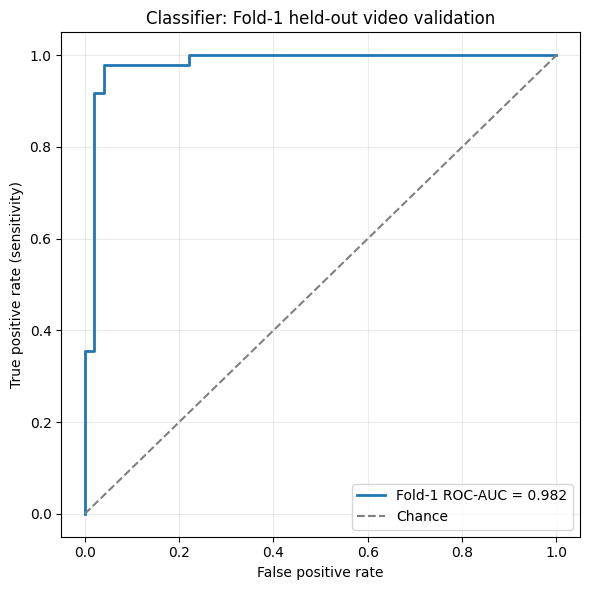

================ FOLD-1 CLASSIFIER VALIDATION COMPLETE ================



,checkpoint_epoch,selection_metric,roc_auc,selected_threshold_from_validation,accuracy_at_selected_threshold,balanced_accuracy_at_selected_threshold,sensitivity_at_selected_threshold,specificity_at_selected_threshold,precision_at_selected_threshold,f1_at_selected_threshold,validation_images,validation_pathology_images,validation_no_pathology_images,validation_videos,outer_test_used
0,7,validation ROC-AUC,0.981667,0.55,0.969388,0.969583,0.979167,0.96,0.959184,0.969072,98,48,50,36,False



Threshold comparison:


,threshold,balanced_accuracy,sensitivity,specificity,precision,f1_score
0,0.10,0.949583,0.979167,0.92,0.921569,0.949495
1,0.15,0.949583,0.979167,0.92,0.921569,0.949495
2,0.20,0.949583,0.979167,0.92,0.921569,0.949495
3,0.25,0.949583,0.979167,0.92,0.921569,0.949495
4,0.30,0.959583,0.979167,0.94,0.940000,0.959184
5,0.35,0.959583,0.979167,0.94,0.940000,0.959184
6,0.40,0.959583,0.979167,0.94,0.940000,0.959184
7,0.45,0.959583,0.979167,0.94,0.940000,0.959184
8,0.50,0.959583,0.979167,0.94,0.940000,0.959184
9,0.55,0.969583,0.979167,0.96,0.959184,0.969072



Saved:
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/classifier_fold_1/best_classifier_validation_predictions.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/classifier_fold_1/best_classifier_validation_metrics.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/classifier_fold_1/best_classifier_validation_thresholds.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/classifier_fold_1/best_classifier_validation_roc_curve.png
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/classifier_fold_1/best_classifier_validation_summary.json


In [ ]:
# ============================================================
# STEP 15 — DETAILED FOLD-1 CLASSIFIER VALIDATION
# Uses the saved best checkpoint only. No training.
# ============================================================

from google.colab import drive
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix,
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
)

try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

REPO_DIR = PROJECT_DIR / "baseline_repository" / "glenda-xai"
FOLD = 1
FOLD_DIR = PROJECT_DIR / "processed" / "fixed_folds" / f"fold_{FOLD}"

VALIDATION_CSV = FOLD_DIR / "classifier_validation.csv"
CHECKPOINT_PATH = (
    PROJECT_DIR / "checkpoints" / f"classifier_edgenext_fold_{FOLD}"
    / "best_validation_auc.pt"
)

OUTPUT_DIR = PROJECT_DIR / "outputs" / f"classifier_fold_{FOLD}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PREDICTIONS_CSV = OUTPUT_DIR / "best_classifier_validation_predictions.csv"
METRICS_CSV = OUTPUT_DIR / "best_classifier_validation_metrics.csv"
THRESHOLDS_CSV = OUTPUT_DIR / "best_classifier_validation_thresholds.csv"
ROC_FIGURE = OUTPUT_DIR / "best_classifier_validation_roc_curve.png"
SUMMARY_JSON = OUTPUT_DIR / "best_classifier_validation_summary.json"

assert REPO_DIR.exists()
assert VALIDATION_CSV.exists()
assert CHECKPOINT_PATH.exists()

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from glenda.dataset import GlendaDataset
from glenda.models import make_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
validation_metadata = pd.read_csv(VALIDATION_CSV)

dataset = GlendaDataset(
    validation_metadata, img_size=320, train=False, img_root=""
)

loader = DataLoader(
    dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

checkpoint = torch.load(
    CHECKPOINT_PATH, map_location=device, weights_only=False
)

model = make_model(
    name="edgenext_small", num_classes=2, pretrained=False
).to(device)

model.load_state_dict(checkpoint["model_state"])
model.eval()

labels, probabilities, paths = [], [], []

with torch.no_grad():
    for batch in loader:
        images = batch["image"].to(device, non_blocking=True)
        logits = model(images)
        pathology_probability = torch.softmax(logits, dim=1)[:, 1]

        labels.extend(batch["label"].numpy().tolist())
        probabilities.extend(pathology_probability.cpu().numpy().tolist())
        paths.extend(batch["path"])

labels = np.asarray(labels, dtype=int)
probabilities = np.asarray(probabilities, dtype=float)

assert len(labels) == len(validation_metadata)
assert np.isfinite(probabilities).all()

auc = float(roc_auc_score(labels, probabilities))

# Evaluate thresholds transparently.
threshold_rows = []

for threshold in np.arange(0.10, 0.91, 0.05):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        labels, predictions, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else 0.0
    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "accuracy": accuracy_score(labels, predictions),
        "balanced_accuracy": balanced_accuracy_score(labels, predictions),
        "sensitivity": sensitivity,
        "specificity": specificity,
        "precision": precision_score(labels, predictions, zero_division=0),
        "f1_score": f1_score(labels, predictions, zero_division=0),
        "youden_j": sensitivity + specificity - 1.0,
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    })

threshold_table = pd.DataFrame(threshold_rows)
selected_row = threshold_table.loc[threshold_table["youden_j"].idxmax()]

selected_threshold = float(selected_row["threshold"])
selected_predictions = (probabilities >= selected_threshold).astype(int)

predictions_table = validation_metadata.copy()
predictions_table["true_label"] = labels
predictions_table["pathology_probability"] = probabilities
predictions_table["prediction_at_selected_threshold"] = selected_predictions
predictions_table["selected_threshold"] = selected_threshold
predictions_table.to_csv(PREDICTIONS_CSV, index=False)

threshold_table.to_csv(THRESHOLDS_CSV, index=False)

metrics = pd.DataFrame([{
    "checkpoint_epoch": int(checkpoint["completed_epoch"]),
    "selection_metric": "validation ROC-AUC",
    "roc_auc": auc,
    "selected_threshold_from_validation": selected_threshold,
    "accuracy_at_selected_threshold": float(selected_row["accuracy"]),
    "balanced_accuracy_at_selected_threshold": float(
        selected_row["balanced_accuracy"]
    ),
    "sensitivity_at_selected_threshold": float(
        selected_row["sensitivity"]
    ),
    "specificity_at_selected_threshold": float(
        selected_row["specificity"]
    ),
    "precision_at_selected_threshold": float(
        selected_row["precision"]
    ),
    "f1_at_selected_threshold": float(selected_row["f1_score"]),
    "validation_images": len(labels),
    "validation_pathology_images": int(labels.sum()),
    "validation_no_pathology_images": int((labels == 0).sum()),
    "validation_videos": int(validation_metadata["video_id"].nunique()),
    "outer_test_used": False,
}])

metrics.to_csv(METRICS_CSV, index=False)

fpr, tpr, _ = roc_curve(labels, probabilities)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, linewidth=2, label=f"Fold-1 ROC-AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (sensitivity)")
plt.title("Classifier: Fold-1 held-out video validation")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(ROC_FIGURE, dpi=180, bbox_inches="tight")
plt.show()

summary = metrics.iloc[0].to_dict()
summary["checkpoint_path"] = str(CHECKPOINT_PATH)
summary["predictions_path"] = str(PREDICTIONS_CSV)
summary["threshold_results_path"] = str(THRESHOLDS_CSV)

with open(SUMMARY_JSON, "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)

print("================ FOLD-1 CLASSIFIER VALIDATION COMPLETE ================\n")
display(metrics)

print("\nThreshold comparison:")
display(
    threshold_table[
        [
            "threshold", "balanced_accuracy", "sensitivity",
            "specificity", "precision", "f1_score"
        ]
    ]
)

print("\nSaved:")
print("-", PREDICTIONS_CSV)
print("-", METRICS_CSV)
print("-", THRESHOLDS_CSV)
print("-", ROC_FIGURE)
print("-", SUMMARY_JSON)

In [2]:
# ============================================================
# MASTER TRAINING — ALL 5 VIDEO-LEVEL FOLDS
#
# Trains/resumes, independently for each fold:
#   1. ImageNet-pretrained EdgeNeXt-Small classifier
#   2. ImageNet-pretrained ResNet-34 U-Net segmenter
#
# All checkpoints are saved every epoch to Google Drive.
# Safe to rerun after interruption.
# ============================================================

from google.colab import drive
from pathlib import Path
import sys
import subprocess
import importlib.util
import json
import random
import shutil
import time

# ------------------------------------------------------------
# Install required packages only if this runtime was reset
# ------------------------------------------------------------
required_packages = {
    "timm": "timm",
    "albumentations": "albumentations",
    "cv2": "opencv-python-headless",
    "segmentation_models_pytorch": "segmentation-models-pytorch",
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing missing package: {package_name}")
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", package_name
        ])

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import segmentation_models_pytorch as smp
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

# ============================================================
# 1. SETTINGS
# ============================================================

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

REPO_DIR = PROJECT_DIR / "baseline_repository" / "glenda-xai"

SPLIT_MANIFEST = (
    PROJECT_DIR / "processed" / "manifests"
    / "glenda_video_level_5fold_splits.csv"
)

MASTER_OUTPUT_DIR = PROJECT_DIR / "outputs" / "all_folds_training"
MASTER_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MASTER_STATUS_CSV = MASTER_OUTPUT_DIR / "all_folds_training_status.csv"

assert REPO_DIR.exists(), f"Missing repository: {REPO_DIR}"
assert SPLIT_MANIFEST.exists(), f"Missing split file: {SPLIT_MANIFEST}"

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from glenda.dataset import GlendaDataset
from glenda.models import make_model

SEED = 2026
N_FOLDS = 5
FOLDS_TO_RUN = [0, 1, 2, 3, 4]

IMAGE_SIZE = 320
MAX_TOTAL_EPOCHS = 20
PATIENCE = 5

CLASSIFIER_LEARNING_RATE = 2e-4
SEGMENTATION_LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
POSITIVE_PIXEL_WEIGHT = 5.0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASSIFIER_BATCH_SIZE = 16 if device.type == "cuda" else 8
SEGMENTATION_BATCH_SIZE = 16 if device.type == "cuda" else 8

print("================ MASTER TRAINING SETUP ================")
print("Device:", device)
print("Folds to process:", FOLDS_TO_RUN)
print("Maximum epochs per model per fold:", MAX_TOTAL_EPOCHS)
print("Classifier batch size:", CLASSIFIER_BATCH_SIZE)
print("Segmentation batch size:", SEGMENTATION_BATCH_SIZE)

# ============================================================
# 2. COMMON HELPERS
# ============================================================

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def save_checkpoint_safely(path, checkpoint_data):
    temporary_path = path.with_suffix(path.suffix + ".temporary")
    torch.save(checkpoint_data, temporary_path)
    temporary_path.replace(path)

def move_optimizer_state_to_device(optimizer, target_device):
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(target_device)

def fold_is_finished(last_checkpoint_path):
    """
    Returns True only if a prior run reached 20 epochs or stopped
    because validation did not improve for the configured patience.
    """
    if not last_checkpoint_path.exists():
        return False

    checkpoint = torch.load(
        last_checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    completed_epoch = int(checkpoint.get("completed_epoch", 0))
    no_improvement = int(
        checkpoint.get("epochs_without_improvement", 0)
    )

    return (
        completed_epoch >= MAX_TOTAL_EPOCHS
        or no_improvement >= PATIENCE
    )

# ============================================================
# 3. PREPARE ALL FOLD METADATA
# ============================================================

all_data = pd.read_csv(SPLIT_MANIFEST)

required_columns = {
    "sample_id", "image_path", "binary_mask_path", "binary_label",
    "video_id", "sequence_id", "frame_id", "lesion_classes",
    "validation_fold",
}

missing_columns = required_columns - set(all_data.columns)
assert not missing_columns, f"Missing columns: {missing_columns}"

def prepare_fold_metadata(fold):
    fold_dir = (
        PROJECT_DIR / "processed" / "fixed_folds" / f"fold_{fold}"
    )
    fold_dir.mkdir(parents=True, exist_ok=True)

    train = all_data[all_data["validation_fold"] != fold].copy()
    validation = all_data[all_data["validation_fold"] == fold].copy()

    assert set(train["video_id"]).isdisjoint(
        set(validation["video_id"])
    ), f"Video leakage in Fold {fold}"

    assert set(train["binary_label"].unique()) == {0, 1}
    assert set(validation["binary_label"].unique()) == {0, 1}

    classifier_train = pd.DataFrame({
        "image_path": train["image_path"],
        "label": train["binary_label"].astype(int),
        "patient_id": train["video_id"].astype(str),
        "video_id": train["video_id"].astype(str),
        "sample_id": train["sample_id"],
        "fold_role": "train",
    })

    classifier_validation = pd.DataFrame({
        "image_path": validation["image_path"],
        "label": validation["binary_label"].astype(int),
        "patient_id": validation["video_id"].astype(str),
        "video_id": validation["video_id"].astype(str),
        "sample_id": validation["sample_id"],
        "fold_role": "validation",
    })

    segmentation_columns = [
        "sample_id", "image_path", "binary_mask_path", "binary_label",
        "video_id", "sequence_id", "frame_id", "lesion_classes",
    ]

    segmentation_train = train[segmentation_columns].rename(columns={
        "binary_mask_path": "mask_path",
        "binary_label": "image_label",
    })

    segmentation_validation = validation[segmentation_columns].rename(
        columns={
            "binary_mask_path": "mask_path",
            "binary_label": "image_label",
        }
    )

    classifier_train.to_csv(
        fold_dir / "classifier_train.csv", index=False
    )
    classifier_validation.to_csv(
        fold_dir / "classifier_validation.csv", index=False
    )
    segmentation_train.to_csv(
        fold_dir / "segmentation_train.csv", index=False
    )
    segmentation_validation.to_csv(
        fold_dir / "segmentation_validation.csv", index=False
    )

    return (
        fold_dir,
        classifier_train,
        classifier_validation,
        segmentation_train,
        segmentation_validation,
    )

# ============================================================
# 4. CLASSIFIER TRAINING
# ============================================================

def train_classifier_fold(
    fold,
    classifier_train,
    classifier_validation,
):
    set_seed(SEED + fold)

    checkpoint_dir = (
        PROJECT_DIR / "checkpoints"
        / f"classifier_edgenext_fold_{fold}"
    )
    output_dir = PROJECT_DIR / "outputs" / f"classifier_fold_{fold}"

    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    output_dir.mkdir(parents=True, exist_ok=True)

    last_checkpoint = checkpoint_dir / "last_checkpoint.pt"
    best_checkpoint = checkpoint_dir / "best_validation_auc.pt"
    history_csv = output_dir / "classifier_training_history.csv"

    if fold_is_finished(last_checkpoint):
        checkpoint = torch.load(
            last_checkpoint, map_location="cpu", weights_only=False
        )

        print(
            f"\nFold {fold} classifier already complete. "
            f"Last epoch: {checkpoint['completed_epoch']}"
        )

        return {
            "fold": fold,
            "model": "classifier",
            "status": "already_complete",
            "best_metric": checkpoint.get("best_validation_auc"),
            "last_epoch": checkpoint.get("completed_epoch"),
        }

    train_dataset = GlendaDataset(
        classifier_train,
        img_size=IMAGE_SIZE,
        train=True,
        img_root="",
    )

    validation_dataset = GlendaDataset(
        classifier_validation,
        img_size=IMAGE_SIZE,
        train=False,
        img_root="",
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=CLASSIFIER_BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=CLASSIFIER_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
    )

    resuming = last_checkpoint.exists()

    model = make_model(
        name="edgenext_small",
        num_classes=2,
        pretrained=not resuming,
    ).to(device)

    class_counts = classifier_train["label"].value_counts().to_dict()

    class_weights = torch.tensor(
        [
            1.0 / class_counts.get(0, 1),
            1.0 / class_counts.get(1, 1),
        ],
        dtype=torch.float32,
    )

    class_weights = (class_weights / class_weights.mean()).to(device)

    criterion = torch.nn.CrossEntropyLoss(
        weight=class_weights,
        label_smoothing=0.03,
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=CLASSIFIER_LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=MAX_TOTAL_EPOCHS,
    )

    history = []
    completed_epoch = 0
    best_auc = -float("inf")
    epochs_without_improvement = 0

    if resuming:
        checkpoint = torch.load(
            last_checkpoint,
            map_location=device,
            weights_only=False,
        )

        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        move_optimizer_state_to_device(optimizer, device)
        scheduler.load_state_dict(checkpoint["scheduler_state"])

        completed_epoch = int(checkpoint["completed_epoch"])
        best_auc = float(checkpoint["best_validation_auc"])
        epochs_without_improvement = int(
            checkpoint.get("epochs_without_improvement", 0)
        )
        history = checkpoint.get("history", [])

        print(
            f"\nResuming Fold {fold} classifier after epoch "
            f"{completed_epoch}."
        )
    else:
        print(f"\nStarting Fold {fold} classifier training.")

    def evaluate_classifier():
        model.eval()
        labels_all = []
        probabilities_all = []
        loss_sum = 0.0
        image_count = 0

        with torch.no_grad():
            for batch in validation_loader:
                images = batch["image"].to(device, non_blocking=True)
                labels = batch["label"].to(device, non_blocking=True)

                logits = model(images)
                loss = criterion(logits, labels)
                probabilities = torch.softmax(logits, dim=1)[:, 1]

                loss_sum += float(loss.item()) * len(labels)
                image_count += len(labels)

                labels_all.extend(labels.cpu().numpy().tolist())
                probabilities_all.extend(probabilities.cpu().numpy().tolist())

        labels_all = np.asarray(labels_all)
        probabilities_all = np.asarray(probabilities_all)
        predictions_all = (probabilities_all >= 0.5).astype(int)

        return {
            "validation_loss": loss_sum / max(image_count, 1),
            "validation_auc": float(
                roc_auc_score(labels_all, probabilities_all)
            ),
            "validation_accuracy": float(
                accuracy_score(labels_all, predictions_all)
            ),
            "validation_balanced_accuracy": float(
                balanced_accuracy_score(labels_all, predictions_all)
            ),
            "validation_f1": float(
                f1_score(labels_all, predictions_all, zero_division=0)
            ),
        }

    for epoch in range(completed_epoch + 1, MAX_TOTAL_EPOCHS + 1):
        epoch_start = time.time()

        model.train()
        loss_sum = 0.0
        image_count = 0

        for batch in train_loader:
            images = batch["image"].to(device, non_blocking=True)
            labels = batch["label"].to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )
            optimizer.step()

            loss_sum += float(loss.item()) * len(labels)
            image_count += len(labels)

        scheduler.step()
        validation_metrics = evaluate_classifier()

        record = {
            "epoch": epoch,
            "training_loss": loss_sum / max(image_count, 1),
            "learning_rate": optimizer.param_groups[0]["lr"],
            **validation_metrics,
            "epoch_minutes": (time.time() - epoch_start) / 60.0,
        }

        history = [
            item for item in history
            if int(item.get("epoch", -1)) != epoch
        ]
        history.append(record)
        history = sorted(history, key=lambda item: int(item["epoch"]))

        improved = record["validation_auc"] > best_auc

        if improved:
            best_auc = record["validation_auc"]
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        checkpoint_data = {
            "model_name": "edgenext_small",
            "initialization": "ImageNet pretrained",
            "fold": fold,
            "completed_epoch": epoch,
            "best_validation_auc": best_auc,
            "epochs_without_improvement": epochs_without_improvement,
            "model_state": {
                key: value.detach().cpu()
                for key, value in model.state_dict().items()
            },
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "history": history,
            "outer_test_used": False,
        }

        save_checkpoint_safely(last_checkpoint, checkpoint_data)

        if improved:
            save_checkpoint_safely(best_checkpoint, checkpoint_data)

        pd.DataFrame(history).to_csv(history_csv, index=False)

        print(
            f"Fold {fold} classifier | Epoch {epoch:02d}/20 | "
            f"loss={record['training_loss']:.4f} | "
            f"AUC={record['validation_auc']:.4f} | "
            f"time={record['epoch_minutes']:.1f} min | "
            f"{'BEST saved' if improved else 'saved'}"
        )

        if epochs_without_improvement >= PATIENCE:
            print(f"Fold {fold} classifier early stopped.")
            break

    return {
        "fold": fold,
        "model": "classifier",
        "status": "complete",
        "best_metric": best_auc,
        "last_epoch": epoch,
    }

# ============================================================
# 5. SEGMENTATION DATASET AND TRAINING
# ============================================================

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

class GlendaSegmentationDataset(Dataset):
    def __init__(self, dataframe, image_size=320, train=False):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size
        self.train = train

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["local_image_path"]) as image:
            image = image.convert("RGB").resize(
                (self.image_size, self.image_size),
                resample=Image.Resampling.BILINEAR,
            )
            image_array = np.asarray(image, dtype=np.float32) / 255.0

        with Image.open(row["local_mask_path"]) as mask:
            mask = mask.convert("L").resize(
                (self.image_size, self.image_size),
                resample=Image.Resampling.NEAREST,
            )
            mask_array = (
                np.asarray(mask, dtype=np.uint8) > 0
            ).astype(np.float32)

        if self.train:
            if random.random() < 0.5:
                image_array = np.ascontiguousarray(
                    np.flip(image_array, axis=1)
                )
                mask_array = np.ascontiguousarray(
                    np.flip(mask_array, axis=1)
                )

            if random.random() < 0.3:
                contrast = random.uniform(0.90, 1.10)
                brightness = random.uniform(-0.05, 0.05)

                image_array = np.clip(
                    image_array * contrast + brightness,
                    0.0,
                    1.0,
                )

        image_array = (image_array - IMAGENET_MEAN) / IMAGENET_STD

        return {
            "image": torch.from_numpy(
                np.transpose(image_array, (2, 0, 1)).copy()
            ).float(),
            "mask": torch.from_numpy(
                mask_array.copy()
            ).unsqueeze(0).float(),
            "label": torch.tensor(
                int(row["image_label"]),
                dtype=torch.long,
            ),
            "sample_id": row["sample_id"],
        }

def prepare_local_segmentation_cache(
    fold,
    segmentation_train,
    segmentation_validation,
):
    cache_dir = Path(f"/content/glenda_all_folds_cache_fold_{fold}")
    image_dir = cache_dir / "images"
    mask_dir = cache_dir / "masks"

    image_dir.mkdir(parents=True, exist_ok=True)
    mask_dir.mkdir(parents=True, exist_ok=True)

    all_metadata = pd.concat(
        [segmentation_train, segmentation_validation],
        ignore_index=True,
    )

    records = []

    for index, row in all_metadata.iterrows():
        source_image = Path(row["image_path"])
        source_mask = Path(row["mask_path"])

        assert source_image.exists()
        assert source_mask.exists()

        local_image = image_dir / f"{row['sample_id']}{source_image.suffix}"
        local_mask = mask_dir / f"{row['sample_id']}.png"

        if (
            not local_image.exists()
            or local_image.stat().st_size != source_image.stat().st_size
        ):
            shutil.copy2(source_image, local_image)

        if (
            not local_mask.exists()
            or local_mask.stat().st_size != source_mask.stat().st_size
        ):
            shutil.copy2(source_mask, local_mask)

        records.append({
            "sample_id": row["sample_id"],
            "local_image_path": str(local_image),
            "local_mask_path": str(local_mask),
        })

    local_paths = pd.DataFrame(records)

    segmentation_train = segmentation_train.merge(
        local_paths,
        on="sample_id",
        how="left",
        validate="one_to_one",
    )

    segmentation_validation = segmentation_validation.merge(
        local_paths,
        on="sample_id",
        how="left",
        validate="one_to_one",
    )

    return segmentation_train, segmentation_validation

def train_segmentation_fold(
    fold,
    segmentation_train,
    segmentation_validation,
):
    set_seed(SEED + 100 + fold)

    checkpoint_dir = (
        PROJECT_DIR / "checkpoints"
        / f"segmentation_unet_fold_{fold}"
    )
    output_dir = (
        PROJECT_DIR / "outputs" / f"segmentation_unet_fold_{fold}"
    )

    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    output_dir.mkdir(parents=True, exist_ok=True)

    last_checkpoint = checkpoint_dir / "last_checkpoint.pt"
    best_checkpoint = checkpoint_dir / "best_validation_dice.pt"
    history_csv = output_dir / "segmentation_training_history.csv"

    if fold_is_finished(last_checkpoint):
        checkpoint = torch.load(
            last_checkpoint, map_location="cpu", weights_only=False
        )

        print(
            f"\nFold {fold} segmentation already complete. "
            f"Last epoch: {checkpoint['completed_epoch']}"
        )

        return {
            "fold": fold,
            "model": "segmentation",
            "status": "already_complete",
            "best_metric": checkpoint.get(
                "best_validation_positive_dice"
            ),
            "last_epoch": checkpoint.get("completed_epoch"),
        }

    segmentation_train, segmentation_validation = (
        prepare_local_segmentation_cache(
            fold,
            segmentation_train,
            segmentation_validation,
        )
    )

    train_dataset = GlendaSegmentationDataset(
        segmentation_train,
        image_size=IMAGE_SIZE,
        train=True,
    )

    validation_dataset = GlendaSegmentationDataset(
        segmentation_validation,
        image_size=IMAGE_SIZE,
        train=False,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=SEGMENTATION_BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=SEGMENTATION_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
    )

    resuming = last_checkpoint.exists()

    model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights=None if resuming else "imagenet",
        in_channels=3,
        classes=1,
        activation=None,
    ).to(device)

    positive_pixel_weight = torch.tensor(
        [POSITIVE_PIXEL_WEIGHT],
        dtype=torch.float32,
        device=device,
    )

    bce_loss = torch.nn.BCEWithLogitsLoss(
        pos_weight=positive_pixel_weight
    )

    def soft_dice_loss(logits, targets, epsilon=1e-6):
        probabilities = torch.sigmoid(logits)
        intersection = (probabilities * targets).sum(dim=(1, 2, 3))
        denominator = (
            probabilities.sum(dim=(1, 2, 3))
            + targets.sum(dim=(1, 2, 3))
        )
        dice = (2 * intersection + epsilon) / (denominator + epsilon)
        return 1 - dice.mean()

    def combined_loss(logits, targets):
        bce = bce_loss(logits, targets)
        dice = soft_dice_loss(logits, targets)
        return 0.5 * bce + 0.5 * dice

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=SEGMENTATION_LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=MAX_TOTAL_EPOCHS,
    )

    history = []
    completed_epoch = 0
    best_dice = -float("inf")
    epochs_without_improvement = 0

    if resuming:
        checkpoint = torch.load(
            last_checkpoint,
            map_location=device,
            weights_only=False,
        )

        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        move_optimizer_state_to_device(optimizer, device)
        scheduler.load_state_dict(checkpoint["scheduler_state"])

        completed_epoch = int(checkpoint["completed_epoch"])
        best_dice = float(
            checkpoint["best_validation_positive_dice"]
        )
        epochs_without_improvement = int(
            checkpoint.get("epochs_without_improvement", 0)
        )
        history = checkpoint.get("history", [])

        print(
            f"\nResuming Fold {fold} segmentation after epoch "
            f"{completed_epoch}."
        )
    else:
        print(f"\nStarting Fold {fold} U-Net segmentation training.")

    def evaluate_segmentation():
        model.eval()

        loss_sum = 0.0
        image_count = 0
        positive_dice_scores = []
        negative_fp_fractions = []
        negative_fp_images = 0
        negative_images = 0

        with torch.no_grad():
            for batch in validation_loader:
                images = batch["image"].to(device, non_blocking=True)
                masks = batch["mask"].to(device, non_blocking=True)
                labels = batch["label"].cpu().numpy()

                logits = model(images)
                loss = combined_loss(logits, masks)

                loss_sum += float(loss.item()) * len(images)
                image_count += len(images)

                predictions = (torch.sigmoid(logits) >= 0.5).float()

                for item_index, label in enumerate(labels):
                    prediction = predictions[item_index, 0]
                    target = masks[item_index, 0]

                    if label == 1:
                        intersection = (prediction * target).sum()
                        denominator = prediction.sum() + target.sum()

                        dice = float(
                            (2 * intersection + 1e-6)
                            / (denominator + 1e-6)
                        )

                        positive_dice_scores.append(dice)

                    else:
                        fraction = float(prediction.mean())
                        negative_fp_fractions.append(fraction)
                        negative_fp_images += int(
                            prediction.sum().item() > 0
                        )
                        negative_images += 1

        return {
            "validation_loss": loss_sum / max(image_count, 1),
            "validation_positive_dice_mean": float(
                np.mean(positive_dice_scores)
            ),
            "validation_positive_dice_median": float(
                np.median(positive_dice_scores)
            ),
            "validation_negative_fp_fraction_mean": float(
                np.mean(negative_fp_fractions)
            ),
            "validation_negative_fp_image_rate": float(
                negative_fp_images / max(negative_images, 1)
            ),
        }

    for epoch in range(completed_epoch + 1, MAX_TOTAL_EPOCHS + 1):
        epoch_start = time.time()

        model.train()
        loss_sum = 0.0
        image_count = 0

        for batch in train_loader:
            images = batch["image"].to(device, non_blocking=True)
            masks = batch["mask"].to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = combined_loss(logits, masks)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )
            optimizer.step()

            loss_sum += float(loss.item()) * len(images)
            image_count += len(images)

        scheduler.step()
        validation_metrics = evaluate_segmentation()

        record = {
            "epoch": epoch,
            "training_loss": loss_sum / max(image_count, 1),
            "learning_rate": optimizer.param_groups[0]["lr"],
            **validation_metrics,
            "epoch_minutes": (time.time() - epoch_start) / 60,
        }

        history = [
            item for item in history
            if int(item.get("epoch", -1)) != epoch
        ]
        history.append(record)
        history = sorted(history, key=lambda item: int(item["epoch"]))

        improved = (
            record["validation_positive_dice_mean"] > best_dice
        )

        if improved:
            best_dice = record["validation_positive_dice_mean"]
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        checkpoint_data = {
            "model_name": "U-Net with ResNet-34 encoder",
            "encoder_initialization": "ImageNet pretrained",
            "fold": fold,
            "completed_epoch": epoch,
            "best_validation_positive_dice": best_dice,
            "epochs_without_improvement": epochs_without_improvement,
            "model_state": {
                key: value.detach().cpu()
                for key, value in model.state_dict().items()
            },
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "history": history,
            "outer_test_used": False,
        }

        save_checkpoint_safely(last_checkpoint, checkpoint_data)

        if improved:
            save_checkpoint_safely(best_checkpoint, checkpoint_data)

        pd.DataFrame(history).to_csv(history_csv, index=False)

        print(
            f"Fold {fold} U-Net | Epoch {epoch:02d}/20 | "
            f"loss={record['training_loss']:.4f} | "
            f"Dice={record['validation_positive_dice_mean']:.4f} | "
            f"FP rate={record['validation_negative_fp_image_rate']:.3f} | "
            f"time={record['epoch_minutes']:.1f} min | "
            f"{'BEST saved' if improved else 'saved'}"
        )

        if epochs_without_improvement >= PATIENCE:
            print(f"Fold {fold} U-Net early stopped.")
            break

    return {
        "fold": fold,
        "model": "segmentation",
        "status": "complete",
        "best_metric": best_dice,
        "last_epoch": epoch,
    }

# ============================================================
# 6. RUN OR RESUME EVERY FOLD
# ============================================================

all_status = []

for fold in FOLDS_TO_RUN:
    print("\n" + "=" * 70)
    print(f"PROCESSING FOLD {fold}")
    print("=" * 70)

    (
        fold_dir,
        classifier_train,
        classifier_validation,
        segmentation_train,
        segmentation_validation,
    ) = prepare_fold_metadata(fold)

    # First classifier, then segmentation.
    classifier_status = train_classifier_fold(
        fold,
        classifier_train,
        classifier_validation,
    )

    all_status.append(classifier_status)
    pd.DataFrame(all_status).to_csv(MASTER_STATUS_CSV, index=False)

    # Release classifier memory before U-Net training.
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    segmentation_status = train_segmentation_fold(
        fold,
        segmentation_train,
        segmentation_validation,
    )

    all_status.append(segmentation_status)
    pd.DataFrame(all_status).to_csv(MASTER_STATUS_CSV, index=False)

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\n================ ALL-FOLDS TRAINING SESSION COMPLETE ================")
display(pd.DataFrame(all_status))

print("\nMaster status saved to:")
print(MASTER_STATUS_CSV)

print("\nIf Colab disconnects, rerun this exact same cell.")
print("Completed folds will be skipped; interrupted folds will resume.")

Drive already mounted at /content/project_drive_2026; to attempt to forcibly remount, call drive.mount("/content/project_drive_2026", force_remount=True).
================ MASTER TRAINING SETUP ================
Device: cpu
Folds to process: [0, 1, 2, 3, 4]
Maximum epochs per model per fold: 20
Classifier batch size: 8
Segmentation batch size: 8

PROCESSING FOLD 0

Fold 0 classifier already complete. Last epoch: 8

Fold 0 segmentation already complete. Last epoch: 18

PROCESSING FOLD 1

Fold 1 classifier already complete. Last epoch: 12

Fold 1 segmentation already complete. Last epoch: 14

PROCESSING FOLD 2

Fold 2 classifier already complete. Last epoch: 7

Fold 2 segmentation already complete. Last epoch: 19

PROCESSING FOLD 3

Fold 3 classifier already complete. Last epoch: 7

Fold 3 segmentation already complete. Last epoch: 15

PROCESSING FOLD 4

Fold 4 classifier already complete. Last epoch: 7

Fold 4 segmentation already complete. Last epoch: 20

================ ALL-FOLDS TRAI

,fold,model,status,best_metric,last_epoch
0,0,classifier,already_complete,0.962308,8
1,0,segmentation,already_complete,0.500121,18
2,1,classifier,already_complete,0.981667,12
3,1,segmentation,already_complete,0.439677,14
4,2,classifier,already_complete,0.967488,7
5,2,segmentation,already_complete,0.362903,19
6,3,classifier,already_complete,0.964141,7
7,3,segmentation,already_complete,0.434946,15
8,4,classifier,already_complete,0.950154,7
9,4,segmentation,already_complete,0.451043,20



Master status saved to:
/content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/all_folds_training/all_folds_training_status.csv

If Colab disconnects, rerun this exact same cell.
Completed folds will be skipped; interrupted folds will resume.


Drive already mounted at /content/project_drive_2026; to attempt to forcibly remount, call drive.mount("/content/project_drive_2026", force_remount=True).
================ ALL-FOLD EVALUATION SETUP ================
Device: cpu
Segmentation threshold: 0.5
Classifier threshold: 0.5

================ EVALUATING FOLD 0 ================
Fold 0 complete | Classifier AUC=0.962 | U-Net Dice=0.500

================ EVALUATING FOLD 1 ================
Fold 1 complete | Classifier AUC=0.982 | U-Net Dice=0.440

================ EVALUATING FOLD 2 ================
Fold 2 complete | Classifier AUC=0.967 | U-Net Dice=0.363

================ EVALUATING FOLD 3 ================
Fold 3 complete | Classifier AUC=0.964 | U-Net Dice=0.435

================ EVALUATING FOLD 4 ================
Fold 4 complete | Classifier AUC=0.950 | U-Net Dice=0.451


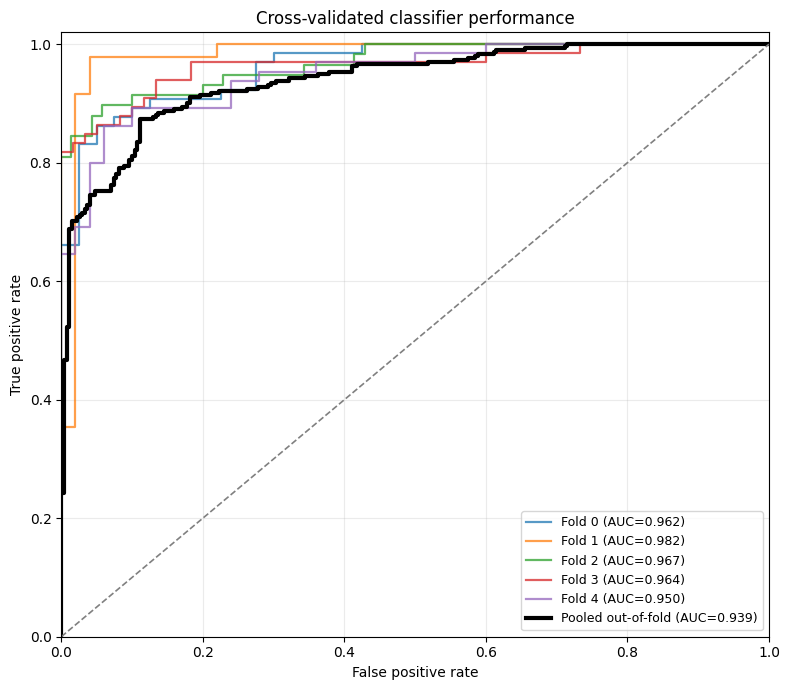

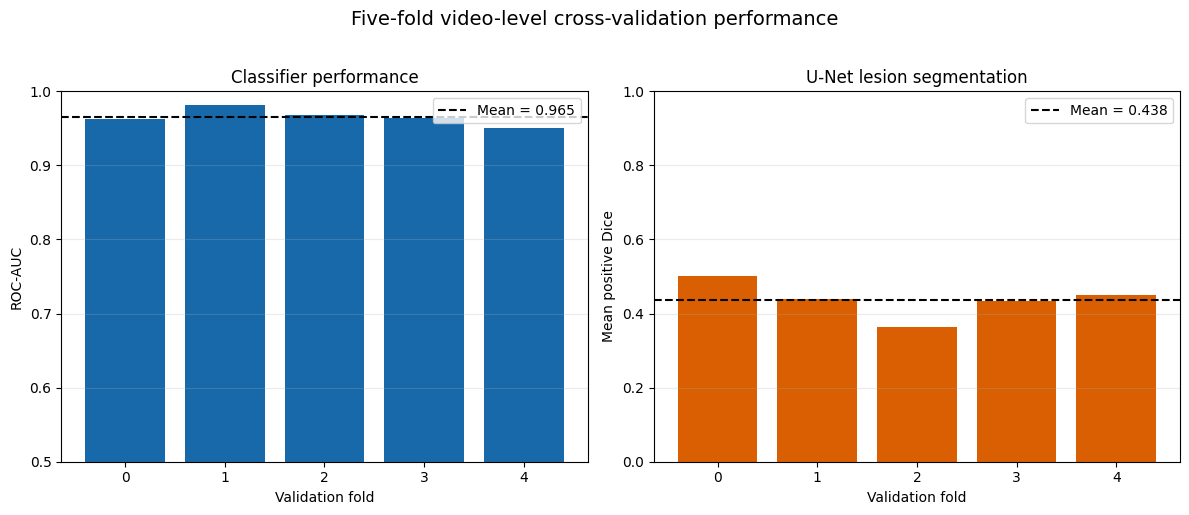

/tmp/ipykernel_1282/3903376089.py:648: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot = plt.boxplot(


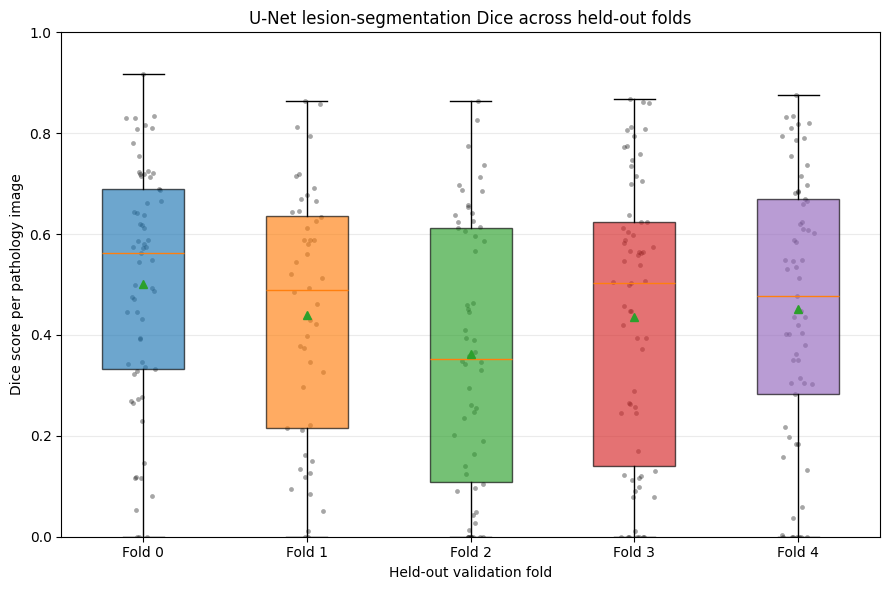


================ ALL-FOLD EVALUATION COMPLETE ================



,fold,classifier_checkpoint_epoch,classifier_auc,classifier_accuracy_at_0p50,classifier_balanced_accuracy_at_0p50,classifier_f1_at_0p50,unet_checkpoint_epoch,unet_mean_positive_dice_at_0p50,unet_median_positive_dice_at_0p50,unet_mean_positive_iou_at_0p50,unet_negative_fp_image_rate_at_0p50,validation_images,validation_pathology_images,validation_no_pathology_images,validation_videos
0,0,3,0.962308,0.895238,0.896154,0.913386,13,0.500121,0.563310,0.366561,0.700000,105,65,40,36
1,1,7,0.981667,0.959184,0.959583,0.959184,9,0.439677,0.489884,0.314309,0.340000,98,48,50,36
2,2,2,0.967488,0.656250,0.685714,0.725000,14,0.362903,0.352630,0.255042,0.500000,128,58,70,38
3,3,2,0.964141,0.904762,0.906818,0.904762,10,0.434946,0.503320,0.317858,0.316667,126,66,60,36
4,4,2,0.950154,0.878261,0.876154,0.892308,17,0.451043,0.476285,0.329261,0.540000,115,65,50,38



Cross-validation summary:
evaluation_type: 5-fold video-level cross-validation
split_unit: video_id
total_out_of_fold_images: 572
pathology_images: 302
no_pathology_images: 270
pooled_out_of_fold_classifier_auc: 0.9389379445670838
mean_fold_classifier_auc: 0.9651514607997367
std_fold_classifier_auc: 0.011316421979031226
mean_fold_unet_dice_at_0p50: 0.4377381257646116
std_fold_unet_dice_at_0p50: 0.04919497138291975
pooled_unet_mean_positive_dice_at_0p50: 0.439354320212791
pooled_unet_median_positive_dice_at_0p50: 0.4754304281284051
pooled_unet_mean_positive_iou_at_0p50: 0.3181665917917025
pooled_unet_negative_fp_image_rate_at_0p50: 0.4666666666666667
important_note: Classifier results are frame-level, with strict video-level separation. U-Net values use the prespecified default probability threshold of 0.50.

Saved data:
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/all_folds_evaluation/classifier_out_of_fold_predictions.csv
- /content/project_drive_2026/MyDrive

In [3]:
# ============================================================
# STEP 17 — ALL-FOLD CROSS-VALIDATION EVALUATION + FIGURES
#
# Evaluates all saved best checkpoints:
#   1. EdgeNeXt classifier
#   2. U-Net segmentation model
#
# Creates:
#   - out-of-fold predictions for all 572 images
#   - fold-by-fold metric table
#   - pooled classifier ROC figure
#   - fold performance figure
#   - U-Net Dice distribution figure
#
# No training occurs.
# ============================================================

from google.colab import drive
from pathlib import Path
import sys
import subprocess
import importlib.util
import json

# Install only missing packages after a Colab reset.
required_packages = {
    "timm": "timm",
    "albumentations": "albumentations",
    "cv2": "opencv-python-headless",
    "segmentation_models_pytorch": "segmentation-models-pytorch",
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing missing package: {package_name}")
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", package_name
        ])

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

# ------------------------------------------------------------
# 1. Paths and fixed evaluation settings
# ------------------------------------------------------------
PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

REPO_DIR = PROJECT_DIR / "baseline_repository" / "glenda-xai"
assert REPO_DIR.exists(), f"Missing repository: {REPO_DIR}"

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from glenda.dataset import GlendaDataset
from glenda.models import make_model

OUTPUT_DIR = PROJECT_DIR / "outputs" / "all_folds_evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSIFIER_OOF_CSV = OUTPUT_DIR / "classifier_out_of_fold_predictions.csv"
UNET_OOF_CSV = OUTPUT_DIR / "unet_out_of_fold_predictions_threshold_0p50.csv"
FOLD_METRICS_CSV = OUTPUT_DIR / "cross_validation_metrics_by_fold.csv"
SUMMARY_JSON = OUTPUT_DIR / "cross_validation_summary.json"

ROC_FIGURE = OUTPUT_DIR / "figure_classifier_cross_validated_roc.png"
FOLD_FIGURE = OUTPUT_DIR / "figure_foldwise_model_performance.png"
DICE_FIGURE = OUTPUT_DIR / "figure_unet_dice_distribution_by_fold.png"

N_FOLDS = 5
IMAGE_SIZE = 320
SEGMENTATION_THRESHOLD = 0.50
CLASSIFIER_THRESHOLD = 0.50

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("================ ALL-FOLD EVALUATION SETUP ================")
print("Device:", device)
print("Segmentation threshold:", SEGMENTATION_THRESHOLD)
print("Classifier threshold:", CLASSIFIER_THRESHOLD)

# ------------------------------------------------------------
# 2. Deterministic segmentation dataset
# ------------------------------------------------------------
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

class EvaluationSegmentationDataset(Dataset):
    def __init__(self, dataframe, image_size=320):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["image_path"]) as image:
            image = image.convert("RGB")
            original_size = image.size

            image = image.resize(
                (self.image_size, self.image_size),
                resample=Image.Resampling.BILINEAR,
            )

            image_array = np.asarray(image, dtype=np.float32) / 255.0

        with Image.open(row["mask_path"]) as mask:
            mask = mask.convert("L")

            assert mask.size == original_size, (
                f"Image-mask mismatch for {row['sample_id']}"
            )

            mask = mask.resize(
                (self.image_size, self.image_size),
                resample=Image.Resampling.NEAREST,
            )

            mask_array = (
                np.asarray(mask, dtype=np.uint8) > 0
            ).astype(np.float32)

        image_array = (image_array - IMAGENET_MEAN) / IMAGENET_STD

        return {
            "image": torch.from_numpy(
                np.transpose(image_array, (2, 0, 1)).copy()
            ).float(),
            "mask": torch.from_numpy(mask_array.copy()).unsqueeze(0).float(),
            "label": torch.tensor(
                int(row["image_label"]),
                dtype=torch.long,
            ),
            "sample_id": row["sample_id"],
        }

def dice_score(prediction, target, epsilon=1e-6):
    intersection = np.logical_and(prediction, target).sum()
    total = prediction.sum() + target.sum()
    return float((2.0 * intersection + epsilon) / (total + epsilon))

def iou_score(prediction, target, epsilon=1e-6):
    intersection = np.logical_and(prediction, target).sum()
    union = np.logical_or(prediction, target).sum()
    return float((intersection + epsilon) / (union + epsilon))

# ------------------------------------------------------------
# 3. Evaluate every saved Fold model
# ------------------------------------------------------------
classifier_records = []
unet_records = []
fold_metric_records = []

for fold in range(N_FOLDS):
    print(f"\n================ EVALUATING FOLD {fold} ================")

    fold_dir = PROJECT_DIR / "processed" / "fixed_folds" / f"fold_{fold}"

    classifier_validation_csv = fold_dir / "classifier_validation.csv"
    segmentation_validation_csv = fold_dir / "segmentation_validation.csv"

    classifier_checkpoint = (
        PROJECT_DIR / "checkpoints" / f"classifier_edgenext_fold_{fold}"
        / "best_validation_auc.pt"
    )

    unet_checkpoint = (
        PROJECT_DIR / "checkpoints" / f"segmentation_unet_fold_{fold}"
        / "best_validation_dice.pt"
    )

    assert classifier_validation_csv.exists()
    assert segmentation_validation_csv.exists()
    assert classifier_checkpoint.exists()
    assert unet_checkpoint.exists()

    classifier_validation = pd.read_csv(classifier_validation_csv)
    segmentation_validation = pd.read_csv(segmentation_validation_csv)

    # --------------------------------------------------------
    # 3A. Classifier evaluation
    # --------------------------------------------------------
    classifier_checkpoint_data = torch.load(
        classifier_checkpoint,
        map_location=device,
        weights_only=False,
    )

    classifier_model = make_model(
        name="edgenext_small",
        num_classes=2,
        pretrained=False,
    ).to(device)

    classifier_model.load_state_dict(
        classifier_checkpoint_data["model_state"]
    )
    classifier_model.eval()

    classifier_dataset = GlendaDataset(
        classifier_validation,
        img_size=IMAGE_SIZE,
        train=False,
        img_root="",
    )

    classifier_loader = DataLoader(
        classifier_dataset,
        batch_size=8,
        shuffle=False,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
    )

    classifier_labels = []
    classifier_probabilities = []
    classifier_paths = []

    with torch.no_grad():
        for batch in classifier_loader:
            images = batch["image"].to(device, non_blocking=True)

            logits = classifier_model(images)
            probabilities = torch.softmax(logits, dim=1)[:, 1]

            classifier_labels.extend(batch["label"].numpy().tolist())
            classifier_probabilities.extend(
                probabilities.cpu().numpy().tolist()
            )
            classifier_paths.extend(batch["path"])

    classifier_labels = np.asarray(classifier_labels, dtype=int)
    classifier_probabilities = np.asarray(
        classifier_probabilities,
        dtype=float,
    )

    classifier_predictions = (
        classifier_probabilities >= CLASSIFIER_THRESHOLD
    ).astype(int)

    classifier_auc = float(
        roc_auc_score(classifier_labels, classifier_probabilities)
    )

    classifier_table = classifier_validation.copy()
    classifier_table["fold"] = fold
    classifier_table["classifier_checkpoint_epoch"] = int(
        classifier_checkpoint_data["completed_epoch"]
    )
    classifier_table["true_label"] = classifier_labels
    classifier_table["pathology_probability"] = classifier_probabilities
    classifier_table["prediction_at_0p50"] = classifier_predictions

    classifier_records.append(classifier_table)

    # --------------------------------------------------------
    # 3B. U-Net segmentation evaluation
    # --------------------------------------------------------
    unet_checkpoint_data = torch.load(
        unet_checkpoint,
        map_location=device,
        weights_only=False,
    )

    unet_model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights=None,
        in_channels=3,
        classes=1,
        activation=None,
    ).to(device)

    unet_model.load_state_dict(unet_checkpoint_data["model_state"])
    unet_model.eval()

    segmentation_dataset = EvaluationSegmentationDataset(
        segmentation_validation,
        image_size=IMAGE_SIZE,
    )

    segmentation_loader = DataLoader(
        segmentation_dataset,
        batch_size=8,
        shuffle=False,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
    )

    segmentation_rows = []

    with torch.no_grad():
        for batch in segmentation_loader:
            images = batch["image"].to(device, non_blocking=True)
            masks = batch["mask"].numpy()[:, 0].astype(bool)
            labels = batch["label"].numpy()

            logits = unet_model(images)
            probabilities = torch.sigmoid(logits).cpu().numpy()[:, 0]

            predictions = probabilities >= SEGMENTATION_THRESHOLD

            for item_index, sample_id in enumerate(batch["sample_id"]):
                target = masks[item_index]
                prediction = predictions[item_index]
                label = int(labels[item_index])

                segmentation_rows.append({
                    "sample_id": sample_id,
                    "fold": fold,
                    "image_label": label,
                    "segmentation_threshold": SEGMENTATION_THRESHOLD,
                    "mean_predicted_probability": float(
                        probabilities[item_index].mean()
                    ),
                    "max_predicted_probability": float(
                        probabilities[item_index].max()
                    ),
                    "predicted_foreground_fraction": float(
                        prediction.mean()
                    ),
                    "target_foreground_fraction": float(target.mean()),
                    "dice": (
                        dice_score(prediction, target)
                        if label == 1 else np.nan
                    ),
                    "iou": (
                        iou_score(prediction, target)
                        if label == 1 else np.nan
                    ),
                })

    segmentation_table = pd.DataFrame(segmentation_rows).merge(
        segmentation_validation[
            [
                "sample_id", "video_id", "sequence_id", "frame_id",
                "lesion_classes", "image_path", "mask_path"
            ]
        ],
        on="sample_id",
        how="left",
        validate="one_to_one",
    )

    unet_records.append(segmentation_table)

    # --------------------------------------------------------
    # 3C. Fold metrics
    # --------------------------------------------------------
    positive_unet = segmentation_table[
        segmentation_table["image_label"] == 1
    ]

    negative_unet = segmentation_table[
        segmentation_table["image_label"] == 0
    ]

    fold_metric_records.append({
        "fold": fold,
        "classifier_checkpoint_epoch": int(
            classifier_checkpoint_data["completed_epoch"]
        ),
        "classifier_auc": classifier_auc,
        "classifier_accuracy_at_0p50": float(
            accuracy_score(classifier_labels, classifier_predictions)
        ),
        "classifier_balanced_accuracy_at_0p50": float(
            balanced_accuracy_score(
                classifier_labels,
                classifier_predictions,
            )
        ),
        "classifier_f1_at_0p50": float(
            f1_score(
                classifier_labels,
                classifier_predictions,
                zero_division=0,
            )
        ),
        "unet_checkpoint_epoch": int(
            unet_checkpoint_data["completed_epoch"]
        ),
        "unet_mean_positive_dice_at_0p50": float(
            positive_unet["dice"].mean()
        ),
        "unet_median_positive_dice_at_0p50": float(
            positive_unet["dice"].median()
        ),
        "unet_mean_positive_iou_at_0p50": float(
            positive_unet["iou"].mean()
        ),
        "unet_negative_fp_image_rate_at_0p50": float(
            (negative_unet["predicted_foreground_fraction"] > 0).mean()
        ),
        "validation_images": len(classifier_validation),
        "validation_pathology_images": int(classifier_labels.sum()),
        "validation_no_pathology_images": int(
            (classifier_labels == 0).sum()
        ),
        "validation_videos": int(
            classifier_validation["video_id"].nunique()
        ),
    })

    print(
        f"Fold {fold} complete | "
        f"Classifier AUC={classifier_auc:.3f} | "
        f"U-Net Dice={positive_unet['dice'].mean():.3f}"
    )

    del classifier_model, unet_model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 4. Save combined out-of-fold predictions
# ------------------------------------------------------------
classifier_oof = pd.concat(
    classifier_records,
    ignore_index=True,
).sort_values("sample_id").reset_index(drop=True)

unet_oof = pd.concat(
    unet_records,
    ignore_index=True,
).sort_values("sample_id").reset_index(drop=True)

fold_metrics = pd.DataFrame(fold_metric_records).sort_values("fold")

assert len(classifier_oof) == 572
assert len(unet_oof) == 572
assert classifier_oof["sample_id"].nunique() == 572
assert unet_oof["sample_id"].nunique() == 572

classifier_oof.to_csv(CLASSIFIER_OOF_CSV, index=False)
unet_oof.to_csv(UNET_OOF_CSV, index=False)
fold_metrics.to_csv(FOLD_METRICS_CSV, index=False)

# ------------------------------------------------------------
# 5. Cross-validation summary
# ------------------------------------------------------------
pooled_labels = classifier_oof["true_label"].to_numpy()
pooled_probabilities = classifier_oof["pathology_probability"].to_numpy()

pooled_auc = float(
    roc_auc_score(pooled_labels, pooled_probabilities)
)

positive_unet_oof = unet_oof[unet_oof["image_label"] == 1]
negative_unet_oof = unet_oof[unet_oof["image_label"] == 0]

summary = {
    "evaluation_type": "5-fold video-level cross-validation",
    "split_unit": "video_id",
    "total_out_of_fold_images": int(len(classifier_oof)),
    "pathology_images": int(pooled_labels.sum()),
    "no_pathology_images": int((pooled_labels == 0).sum()),
    "pooled_out_of_fold_classifier_auc": pooled_auc,
    "mean_fold_classifier_auc": float(
        fold_metrics["classifier_auc"].mean()
    ),
    "std_fold_classifier_auc": float(
        fold_metrics["classifier_auc"].std(ddof=1)
    ),
    "mean_fold_unet_dice_at_0p50": float(
        fold_metrics["unet_mean_positive_dice_at_0p50"].mean()
    ),
    "std_fold_unet_dice_at_0p50": float(
        fold_metrics["unet_mean_positive_dice_at_0p50"].std(ddof=1)
    ),
    "pooled_unet_mean_positive_dice_at_0p50": float(
        positive_unet_oof["dice"].mean()
    ),
    "pooled_unet_median_positive_dice_at_0p50": float(
        positive_unet_oof["dice"].median()
    ),
    "pooled_unet_mean_positive_iou_at_0p50": float(
        positive_unet_oof["iou"].mean()
    ),
    "pooled_unet_negative_fp_image_rate_at_0p50": float(
        (negative_unet_oof["predicted_foreground_fraction"] > 0).mean()
    ),
    "important_note": (
        "Classifier results are frame-level, with strict video-level "
        "separation. U-Net values use the prespecified default "
        "probability threshold of 0.50."
    ),
}

with open(SUMMARY_JSON, "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)

# ------------------------------------------------------------
# 6. Figure 1 — five ROC curves + pooled out-of-fold ROC
# ------------------------------------------------------------
plt.figure(figsize=(8, 7))

colors = plt.cm.tab10.colors

for fold in range(N_FOLDS):
    fold_data = classifier_oof[classifier_oof["fold"] == fold]

    fold_fpr, fold_tpr, _ = roc_curve(
        fold_data["true_label"],
        fold_data["pathology_probability"],
    )

    fold_auc = roc_auc_score(
        fold_data["true_label"],
        fold_data["pathology_probability"],
    )

    plt.plot(
        fold_fpr,
        fold_tpr,
        color=colors[fold],
        linewidth=1.6,
        alpha=0.75,
        label=f"Fold {fold} (AUC={fold_auc:.3f})",
    )

pooled_fpr, pooled_tpr, _ = roc_curve(
    pooled_labels,
    pooled_probabilities,
)

plt.plot(
    pooled_fpr,
    pooled_tpr,
    color="black",
    linewidth=3,
    label=f"Pooled out-of-fold (AUC={pooled_auc:.3f})",
)

plt.plot([0, 1], [0, 1], "--", color="gray", linewidth=1.2)
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Cross-validated classifier performance")
plt.grid(alpha=0.25)
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig(ROC_FIGURE, dpi=250, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 7. Figure 2 — fold-wise classifier and U-Net performance
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

fold_positions = fold_metrics["fold"].to_numpy()

axes[0].bar(
    fold_positions,
    fold_metrics["classifier_auc"],
    color="#1769aa",
)

axes[0].axhline(
    fold_metrics["classifier_auc"].mean(),
    color="black",
    linestyle="--",
    label=(
        "Mean = "
        f"{fold_metrics['classifier_auc'].mean():.3f}"
    ),
)

axes[0].set_ylim(0.5, 1.0)
axes[0].set_xticks(fold_positions)
axes[0].set_xlabel("Validation fold")
axes[0].set_ylabel("ROC-AUC")
axes[0].set_title("Classifier performance")
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend()

axes[1].bar(
    fold_positions,
    fold_metrics["unet_mean_positive_dice_at_0p50"],
    color="#d95f02",
)

axes[1].axhline(
    fold_metrics["unet_mean_positive_dice_at_0p50"].mean(),
    color="black",
    linestyle="--",
    label=(
        "Mean = "
        f"{fold_metrics['unet_mean_positive_dice_at_0p50'].mean():.3f}"
    ),
)

axes[1].set_ylim(0, 1.0)
axes[1].set_xticks(fold_positions)
axes[1].set_xlabel("Validation fold")
axes[1].set_ylabel("Mean positive Dice")
axes[1].set_title("U-Net lesion segmentation")
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend()

fig.suptitle(
    "Five-fold video-level cross-validation performance",
    fontsize=14,
    y=1.02,
)

plt.tight_layout()
plt.savefig(FOLD_FIGURE, dpi=250, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 8. Figure 3 — lesion Dice distributions across folds
# ------------------------------------------------------------
dice_by_fold = [
    unet_oof[
        (unet_oof["fold"] == fold)
        & (unet_oof["image_label"] == 1)
    ]["dice"].dropna().to_numpy()
    for fold in range(N_FOLDS)
]

plt.figure(figsize=(9, 6))

boxplot = plt.boxplot(
    dice_by_fold,
    labels=[f"Fold {fold}" for fold in range(N_FOLDS)],
    patch_artist=True,
    showmeans=True,
)

for patch, color in zip(boxplot["boxes"], colors[:N_FOLDS]):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)

for fold, values in enumerate(dice_by_fold, start=1):
    jitter = np.random.default_rng(2026 + fold).normal(
        loc=fold,
        scale=0.045,
        size=len(values),
    )

    plt.scatter(
        jitter,
        values,
        color="black",
        alpha=0.35,
        s=12,
        linewidths=0,
    )

plt.ylim(0, 1)
plt.xlabel("Held-out validation fold")
plt.ylabel("Dice score per pathology image")
plt.title("U-Net lesion-segmentation Dice across held-out folds")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(DICE_FIGURE, dpi=250, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 9. Final report
# ------------------------------------------------------------
print("\n================ ALL-FOLD EVALUATION COMPLETE ================\n")
display(fold_metrics)

print("\nCross-validation summary:")
for key, value in summary.items():
    print(f"{key}: {value}")

print("\nSaved data:")
print("-", CLASSIFIER_OOF_CSV)
print("-", UNET_OOF_CSV)
print("-", FOLD_METRICS_CSV)
print("-", SUMMARY_JSON)

print("\nSaved paper-ready figures:")
print("-", ROC_FIGURE)
print("-", FOLD_FIGURE)
print("-", DICE_FIGURE)

print("\nNext: generate Grad-CAM on the held-out pathology images")
print("from all folds and create the final U-Net vs Grad-CAM comparison.")

Installing missing package: grad-cam
Drive already mounted at /content/project_drive_2026; to attempt to forcibly remount, call drive.mount("/content/project_drive_2026", force_remount=True).
================ ALL-FOLD GRAD-CAM SETUP ================
Device: cpu
Fixed Grad-CAM threshold: 0.2

================ FOLD 0 GRAD-CAM ================
Fold 0: Grad-CAM 20/65 complete
Fold 0: Grad-CAM 40/65 complete
Fold 0: Grad-CAM 60/65 complete
Fold 0: Grad-CAM 65/65 complete

================ FOLD 1 GRAD-CAM ================
Fold 1: Grad-CAM 20/48 complete
Fold 1: Grad-CAM 40/48 complete
Fold 1: Grad-CAM 48/48 complete

================ FOLD 2 GRAD-CAM ================
Fold 2: Grad-CAM 20/58 complete
Fold 2: Grad-CAM 40/58 complete
Fold 2: Grad-CAM 58/58 complete

================ FOLD 3 GRAD-CAM ================
Fold 3: Grad-CAM 20/66 complete
Fold 3: Grad-CAM 40/66 complete
Fold 3: Grad-CAM 60/66 complete
Fold 3: Grad-CAM 66/66 complete

================ FOLD 4 GRAD-CAM ================
Fold 

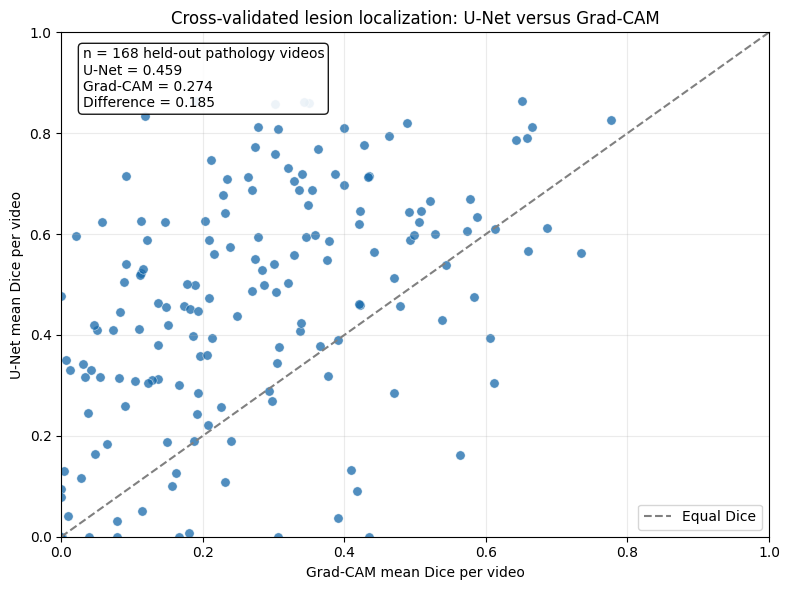

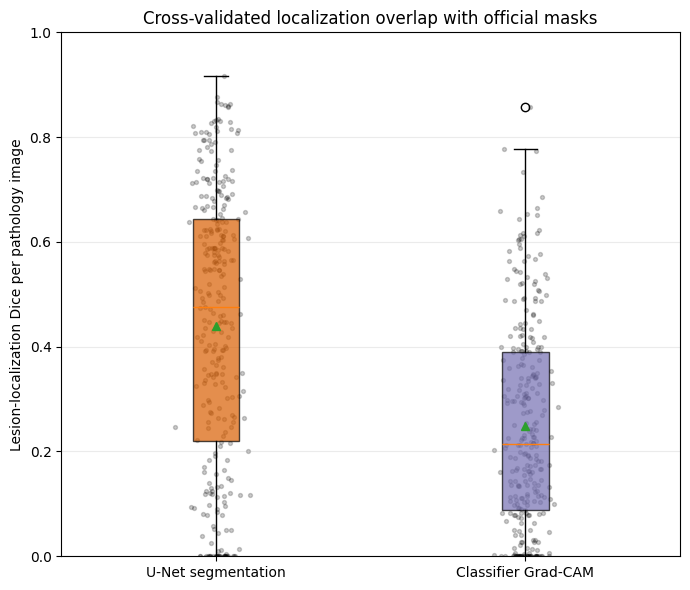


================ ALL-FOLD GRAD-CAM COMPARISON COMPLETE ================



,cross_validation_folds,held_out_pathology_images,held_out_pathology_videos,fixed_gradcam_threshold,fixed_unet_threshold,unet_mean_image_dice,gradcam_mean_image_dice,unet_mean_video_dice,gradcam_mean_video_dice,mean_video_dice_difference_unet_minus_gradcam,bootstrap_95ci_low_difference,bootstrap_95ci_high_difference,unet_better_videos,gradcam_better_videos,tied_videos,one_sided_video_level_wilcoxon_p_value,interpretation
0,5,302,168,0.2,0.5,0.439354,0.248589,0.459041,0.273856,0.185185,0.15087,0.219292,136,32,0,7.611173e-18,U-Net and Grad-CAM are compared only on held-o...



Saved:
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/all_folds_gradcam_comparison/all_folds_gradcam_vs_unet_per_image.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/all_folds_gradcam_comparison/all_folds_gradcam_vs_unet_video_level.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/all_folds_gradcam_comparison/all_folds_gradcam_vs_unet_summary.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/all_folds_gradcam_comparison/all_folds_gradcam_vs_unet_summary.json
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/all_folds_gradcam_comparison/figure_video_level_unet_vs_gradcam_scatter.png
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/all_folds_gradcam_comparison/figure_image_level_unet_vs_gradcam_distribution.png

Next: create final qualitative examples showing
the image, official mask, U-Net prediction, and Grad-CAM together.


In [4]:
# ============================================================
# STEP 18 — ALL-FOLD GRAD-CAM vs U-NET LOCALIZATION COMPARISON
#
# Uses all 302 held-out pathology images, each evaluated only
# by the classifier and U-Net that did not train on its video.
#
# Outputs:
# - Grad-CAM heatmaps
# - U-Net vs Grad-CAM per-image comparison
# - statistically appropriate video-level comparison
# - publication-quality comparison figures
#
# No training occurs.
# ============================================================

from google.colab import drive
from pathlib import Path
import sys
import subprocess
import importlib.util
import json

required_packages = {
    "timm": "timm",
    "albumentations": "albumentations",
    "cv2": "opencv-python-headless",
    "pytorch_grad_cam": "grad-cam",
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing missing package: {package_name}")
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", package_name
        ])

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader
from scipy.stats import wilcoxon

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

# ------------------------------------------------------------
# 1. Paths and evaluation settings
# ------------------------------------------------------------
PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

REPO_DIR = PROJECT_DIR / "baseline_repository" / "glenda-xai"
assert REPO_DIR.exists()

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from glenda.dataset import GlendaDataset
from glenda.models import make_model, get_default_target_layer

ALL_FOLDS_EVALUATION_DIR = (
    PROJECT_DIR / "outputs" / "all_folds_evaluation"
)

UNET_OOF_CSV = (
    ALL_FOLDS_EVALUATION_DIR
    / "unet_out_of_fold_predictions_threshold_0p50.csv"
)

OUTPUT_DIR = PROJECT_DIR / "outputs" / "all_folds_gradcam_comparison"
HEATMAP_DIR = OUTPUT_DIR / "gradcam_heatmaps"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
HEATMAP_DIR.mkdir(parents=True, exist_ok=True)

PER_IMAGE_CSV = OUTPUT_DIR / "all_folds_gradcam_vs_unet_per_image.csv"
VIDEO_CSV = OUTPUT_DIR / "all_folds_gradcam_vs_unet_video_level.csv"
SUMMARY_CSV = OUTPUT_DIR / "all_folds_gradcam_vs_unet_summary.csv"
SUMMARY_JSON = OUTPUT_DIR / "all_folds_gradcam_vs_unet_summary.json"

SCATTER_FIGURE = (
    OUTPUT_DIR / "figure_video_level_unet_vs_gradcam_scatter.png"
)

BOXPLOT_FIGURE = (
    OUTPUT_DIR / "figure_image_level_unet_vs_gradcam_distribution.png"
)

assert UNET_OOF_CSV.exists(), f"Missing: {UNET_OOF_CSV}"

# This fixed threshold was selected in the Fold-0 pilot and is
# now applied unchanged to every fold for a consistent comparison.
GRADCAM_THRESHOLD = 0.20
IMAGE_SIZE = 320
N_FOLDS = 5

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("================ ALL-FOLD GRAD-CAM SETUP ================")
print("Device:", device)
print("Fixed Grad-CAM threshold:", GRADCAM_THRESHOLD)

# ------------------------------------------------------------
# 2. Helper metrics
# ------------------------------------------------------------
def dice_score(prediction, target, epsilon=1e-6):
    intersection = np.logical_and(prediction, target).sum()
    total = prediction.sum() + target.sum()
    return float((2.0 * intersection + epsilon) / (total + epsilon))

def iou_score(prediction, target, epsilon=1e-6):
    intersection = np.logical_and(prediction, target).sum()
    union = np.logical_or(prediction, target).sum()
    return float((intersection + epsilon) / (union + epsilon))

# U-Net out-of-fold results were already generated using the
# saved best U-Net model for each held-out fold.
unet_oof = pd.read_csv(UNET_OOF_CSV)

positive_unet = unet_oof[
    unet_oof["image_label"] == 1
].copy()

assert len(positive_unet) == 302
assert positive_unet["sample_id"].nunique() == 302

unet_by_sample_id = positive_unet.set_index("sample_id")

# ------------------------------------------------------------
# 3. Generate Grad-CAM only for pathology images
#    Exact lesion-overlap metrics are meaningful for these images.
# ------------------------------------------------------------
all_records = []

for fold in range(N_FOLDS):
    print(f"\n================ FOLD {fold} GRAD-CAM ================")

    fold_dir = PROJECT_DIR / "processed" / "fixed_folds" / f"fold_{fold}"

    validation_csv = fold_dir / "classifier_validation.csv"

    checkpoint_path = (
        PROJECT_DIR / "checkpoints" / f"classifier_edgenext_fold_{fold}"
        / "best_validation_auc.pt"
    )

    assert validation_csv.exists()
    assert checkpoint_path.exists()

    validation = pd.read_csv(validation_csv)

    # Only pathology images have an official lesion mask to compare against.
    validation_positive = validation[validation["label"] == 1].copy()

    assert len(validation_positive) > 0

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False,
    )

    model = make_model(
        name="edgenext_small",
        num_classes=2,
        pretrained=False,
    ).to(device)

    model.load_state_dict(checkpoint["model_state"])
    model.eval()

    target_layer = get_default_target_layer(model, "edgenext_small")

    assert target_layer is not None, (
        f"No Grad-CAM target layer found for Fold {fold}"
    )

    dataset = GlendaDataset(
        validation_positive,
        img_size=IMAGE_SIZE,
        train=False,
        img_root="",
    )

    loader = DataLoader(
        dataset,
        batch_size=1,
        shuffle=False,
        num_workers=0,
    )

    cam = GradCAM(
        model=model,
        target_layers=[target_layer],
    )

    for index, batch in enumerate(loader):
        image_path = batch["path"][0]

        metadata_row = validation_positive[
            validation_positive["image_path"] == image_path
        ].iloc[0]

        sample_id = metadata_row["sample_id"]

        assert sample_id in unet_by_sample_id.index, (
            f"U-Net prediction missing for {sample_id}"
        )

        input_tensor = batch["image"].to(device)

        with torch.no_grad():
            logits = model(input_tensor)
            pathology_probability = float(
                torch.softmax(logits, dim=1)[0, 1].cpu()
            )

        # Grad-CAM map showing evidence for pathology class = 1.
        heatmap = cam(
            input_tensor=input_tensor,
            targets=[ClassifierOutputTarget(1)],
        )[0]

        heatmap_uint8 = np.clip(
            heatmap * 255,
            0,
            255,
        ).astype(np.uint8)

        fold_heatmap_dir = HEATMAP_DIR / f"fold_{fold}"
        fold_heatmap_dir.mkdir(parents=True, exist_ok=True)

        heatmap_path = fold_heatmap_dir / f"{sample_id}_gradcam.png"
        Image.fromarray(heatmap_uint8).save(heatmap_path)

        with Image.open(
            unet_by_sample_id.loc[sample_id, "mask_path"]
        ) as mask:
            mask = mask.convert("L").resize(
                (IMAGE_SIZE, IMAGE_SIZE),
                resample=Image.Resampling.NEAREST,
            )

            official_mask = np.asarray(mask) > 0

        gradcam_region = heatmap >= GRADCAM_THRESHOLD

        all_records.append({
            "sample_id": sample_id,
            "fold": fold,
            "video_id": unet_by_sample_id.loc[sample_id, "video_id"],
            "lesion_classes": unet_by_sample_id.loc[
                sample_id, "lesion_classes"
            ],
            "image_path": image_path,
            "mask_path": unet_by_sample_id.loc[sample_id, "mask_path"],
            "gradcam_heatmap_path": str(heatmap_path),
            "classifier_pathology_probability": pathology_probability,
            "gradcam_threshold": GRADCAM_THRESHOLD,
            "gradcam_foreground_fraction": float(
                gradcam_region.mean()
            ),
            "gradcam_dice": dice_score(gradcam_region, official_mask),
            "gradcam_iou": iou_score(gradcam_region, official_mask),
            "unet_dice_at_0p50": float(
                unet_by_sample_id.loc[sample_id, "dice"]
            ),
            "unet_iou_at_0p50": float(
                unet_by_sample_id.loc[sample_id, "iou"]
            ),
        })

        if (index + 1) % 20 == 0 or (index + 1) == len(dataset):
            print(
                f"Fold {fold}: Grad-CAM "
                f"{index + 1}/{len(dataset)} complete"
            )

    del cam, model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 4. Save per-image comparison
# ------------------------------------------------------------
per_image = pd.DataFrame(all_records).sort_values(
    ["fold", "video_id", "sample_id"]
).reset_index(drop=True)

assert len(per_image) == 302
assert per_image["sample_id"].nunique() == 302

per_image["dice_difference_unet_minus_gradcam"] = (
    per_image["unet_dice_at_0p50"]
    - per_image["gradcam_dice"]
)

per_image["iou_difference_unet_minus_gradcam"] = (
    per_image["unet_iou_at_0p50"]
    - per_image["gradcam_iou"]
)

per_image.to_csv(PER_IMAGE_CSV, index=False)

# ------------------------------------------------------------
# 5. Correct video-level comparison and statistics
# ------------------------------------------------------------
video_results = (
    per_image
    .groupby(["fold", "video_id"], as_index=False)
    .agg(
        pathology_frames=("sample_id", "count"),
        unet_mean_dice=("unet_dice_at_0p50", "mean"),
        gradcam_mean_dice=("gradcam_dice", "mean"),
        unet_mean_iou=("unet_iou_at_0p50", "mean"),
        gradcam_mean_iou=("gradcam_iou", "mean"),
        mean_classifier_probability=(
            "classifier_pathology_probability",
            "mean",
        ),
    )
)

video_results["dice_difference_unet_minus_gradcam"] = (
    video_results["unet_mean_dice"]
    - video_results["gradcam_mean_dice"]
)

video_results.to_csv(VIDEO_CSV, index=False)

differences = video_results[
    "dice_difference_unet_minus_gradcam"
].to_numpy()

wilcoxon_result = wilcoxon(
    video_results["unet_mean_dice"],
    video_results["gradcam_mean_dice"],
    alternative="greater",
    zero_method="wilcox",
)

rng = np.random.default_rng(2026)

bootstrap_means = np.array([
    rng.choice(differences, size=len(differences), replace=True).mean()
    for _ in range(5000)
])

ci_low, ci_high = np.quantile(
    bootstrap_means,
    [0.025, 0.975],
)

summary = pd.DataFrame([{
    "cross_validation_folds": N_FOLDS,
    "held_out_pathology_images": len(per_image),
    "held_out_pathology_videos": len(video_results),
    "fixed_gradcam_threshold": GRADCAM_THRESHOLD,
    "fixed_unet_threshold": 0.50,
    "unet_mean_image_dice": float(
        per_image["unet_dice_at_0p50"].mean()
    ),
    "gradcam_mean_image_dice": float(
        per_image["gradcam_dice"].mean()
    ),
    "unet_mean_video_dice": float(
        video_results["unet_mean_dice"].mean()
    ),
    "gradcam_mean_video_dice": float(
        video_results["gradcam_mean_dice"].mean()
    ),
    "mean_video_dice_difference_unet_minus_gradcam": float(
        differences.mean()
    ),
    "bootstrap_95ci_low_difference": float(ci_low),
    "bootstrap_95ci_high_difference": float(ci_high),
    "unet_better_videos": int((differences > 0).sum()),
    "gradcam_better_videos": int((differences < 0).sum()),
    "tied_videos": int((differences == 0).sum()),
    "one_sided_video_level_wilcoxon_p_value": float(
        wilcoxon_result.pvalue
    ),
    "interpretation": (
        "U-Net and Grad-CAM are compared only on held-out pathology "
        "images. Statistics aggregate frames by video_id before testing."
    ),
}])

summary.to_csv(SUMMARY_CSV, index=False)

# ------------------------------------------------------------
# 6. Figure 1 — video-level paired scatter plot
# ------------------------------------------------------------
plt.figure(figsize=(8, 6))

plt.scatter(
    video_results["gradcam_mean_dice"],
    video_results["unet_mean_dice"],
    color="#1769aa",
    s=45,
    alpha=0.75,
    edgecolor="white",
    linewidth=0.4,
)

plt.plot([0, 1], [0, 1], "--", color="gray", label="Equal Dice")

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("Grad-CAM mean Dice per video")
plt.ylabel("U-Net mean Dice per video")
plt.title(
    "Cross-validated lesion localization: U-Net versus Grad-CAM"
)
plt.grid(alpha=0.25)
plt.legend()

plt.gca().text(
    0.03,
    0.97,
    (
        f"n = {len(video_results)} held-out pathology videos\n"
        f"U-Net = {video_results['unet_mean_dice'].mean():.3f}\n"
        f"Grad-CAM = {video_results['gradcam_mean_dice'].mean():.3f}\n"
        f"Difference = {differences.mean():.3f}"
    ),
    transform=plt.gca().transAxes,
    va="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.9),
)

plt.tight_layout()
plt.savefig(SCATTER_FIGURE, dpi=250, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 7. Figure 2 — image-level Dice distribution
# This figure is descriptive; inferential statistics use videos.
# ------------------------------------------------------------
plt.figure(figsize=(7, 6))

boxplot = plt.boxplot(
    [
        per_image["unet_dice_at_0p50"],
        per_image["gradcam_dice"],
    ],
    tick_labels=["U-Net segmentation", "Classifier Grad-CAM"],
    patch_artist=True,
    showmeans=True,
)

boxplot["boxes"][0].set_facecolor("#d95f02")
boxplot["boxes"][1].set_facecolor("#7570b3")

for patch in boxplot["boxes"]:
    patch.set_alpha(0.70)

plt.scatter(
    np.random.default_rng(2026).normal(
        1, 0.035, len(per_image)
    ),
    per_image["unet_dice_at_0p50"],
    s=8,
    alpha=0.20,
    color="black",
)

plt.scatter(
    np.random.default_rng(2027).normal(
        2, 0.035, len(per_image)
    ),
    per_image["gradcam_dice"],
    s=8,
    alpha=0.20,
    color="black",
)

plt.ylim(0, 1)
plt.ylabel("Lesion-localization Dice per pathology image")
plt.title("Cross-validated localization overlap with official masks")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(BOXPLOT_FIGURE, dpi=250, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 8. Save final summary
# ------------------------------------------------------------
summary_dict = summary.iloc[0].to_dict()
summary_dict["per_image_results_path"] = str(PER_IMAGE_CSV)
summary_dict["video_results_path"] = str(VIDEO_CSV)
summary_dict["scatter_figure_path"] = str(SCATTER_FIGURE)
summary_dict["boxplot_figure_path"] = str(BOXPLOT_FIGURE)

with open(SUMMARY_JSON, "w", encoding="utf-8") as file:
    json.dump(summary_dict, file, indent=2)

print("\n================ ALL-FOLD GRAD-CAM COMPARISON COMPLETE ================\n")
display(summary)

print("\nSaved:")
print("-", PER_IMAGE_CSV)
print("-", VIDEO_CSV)
print("-", SUMMARY_CSV)
print("-", SUMMARY_JSON)
print("-", SCATTER_FIGURE)
print("-", BOXPLOT_FIGURE)

print("\nNext: create final qualitative examples showing")
print("the image, official mask, U-Net prediction, and Grad-CAM together.")

Drive already mounted at /content/project_drive_2026; to attempt to forcibly remount, call drive.mount("/content/project_drive_2026", force_remount=True).


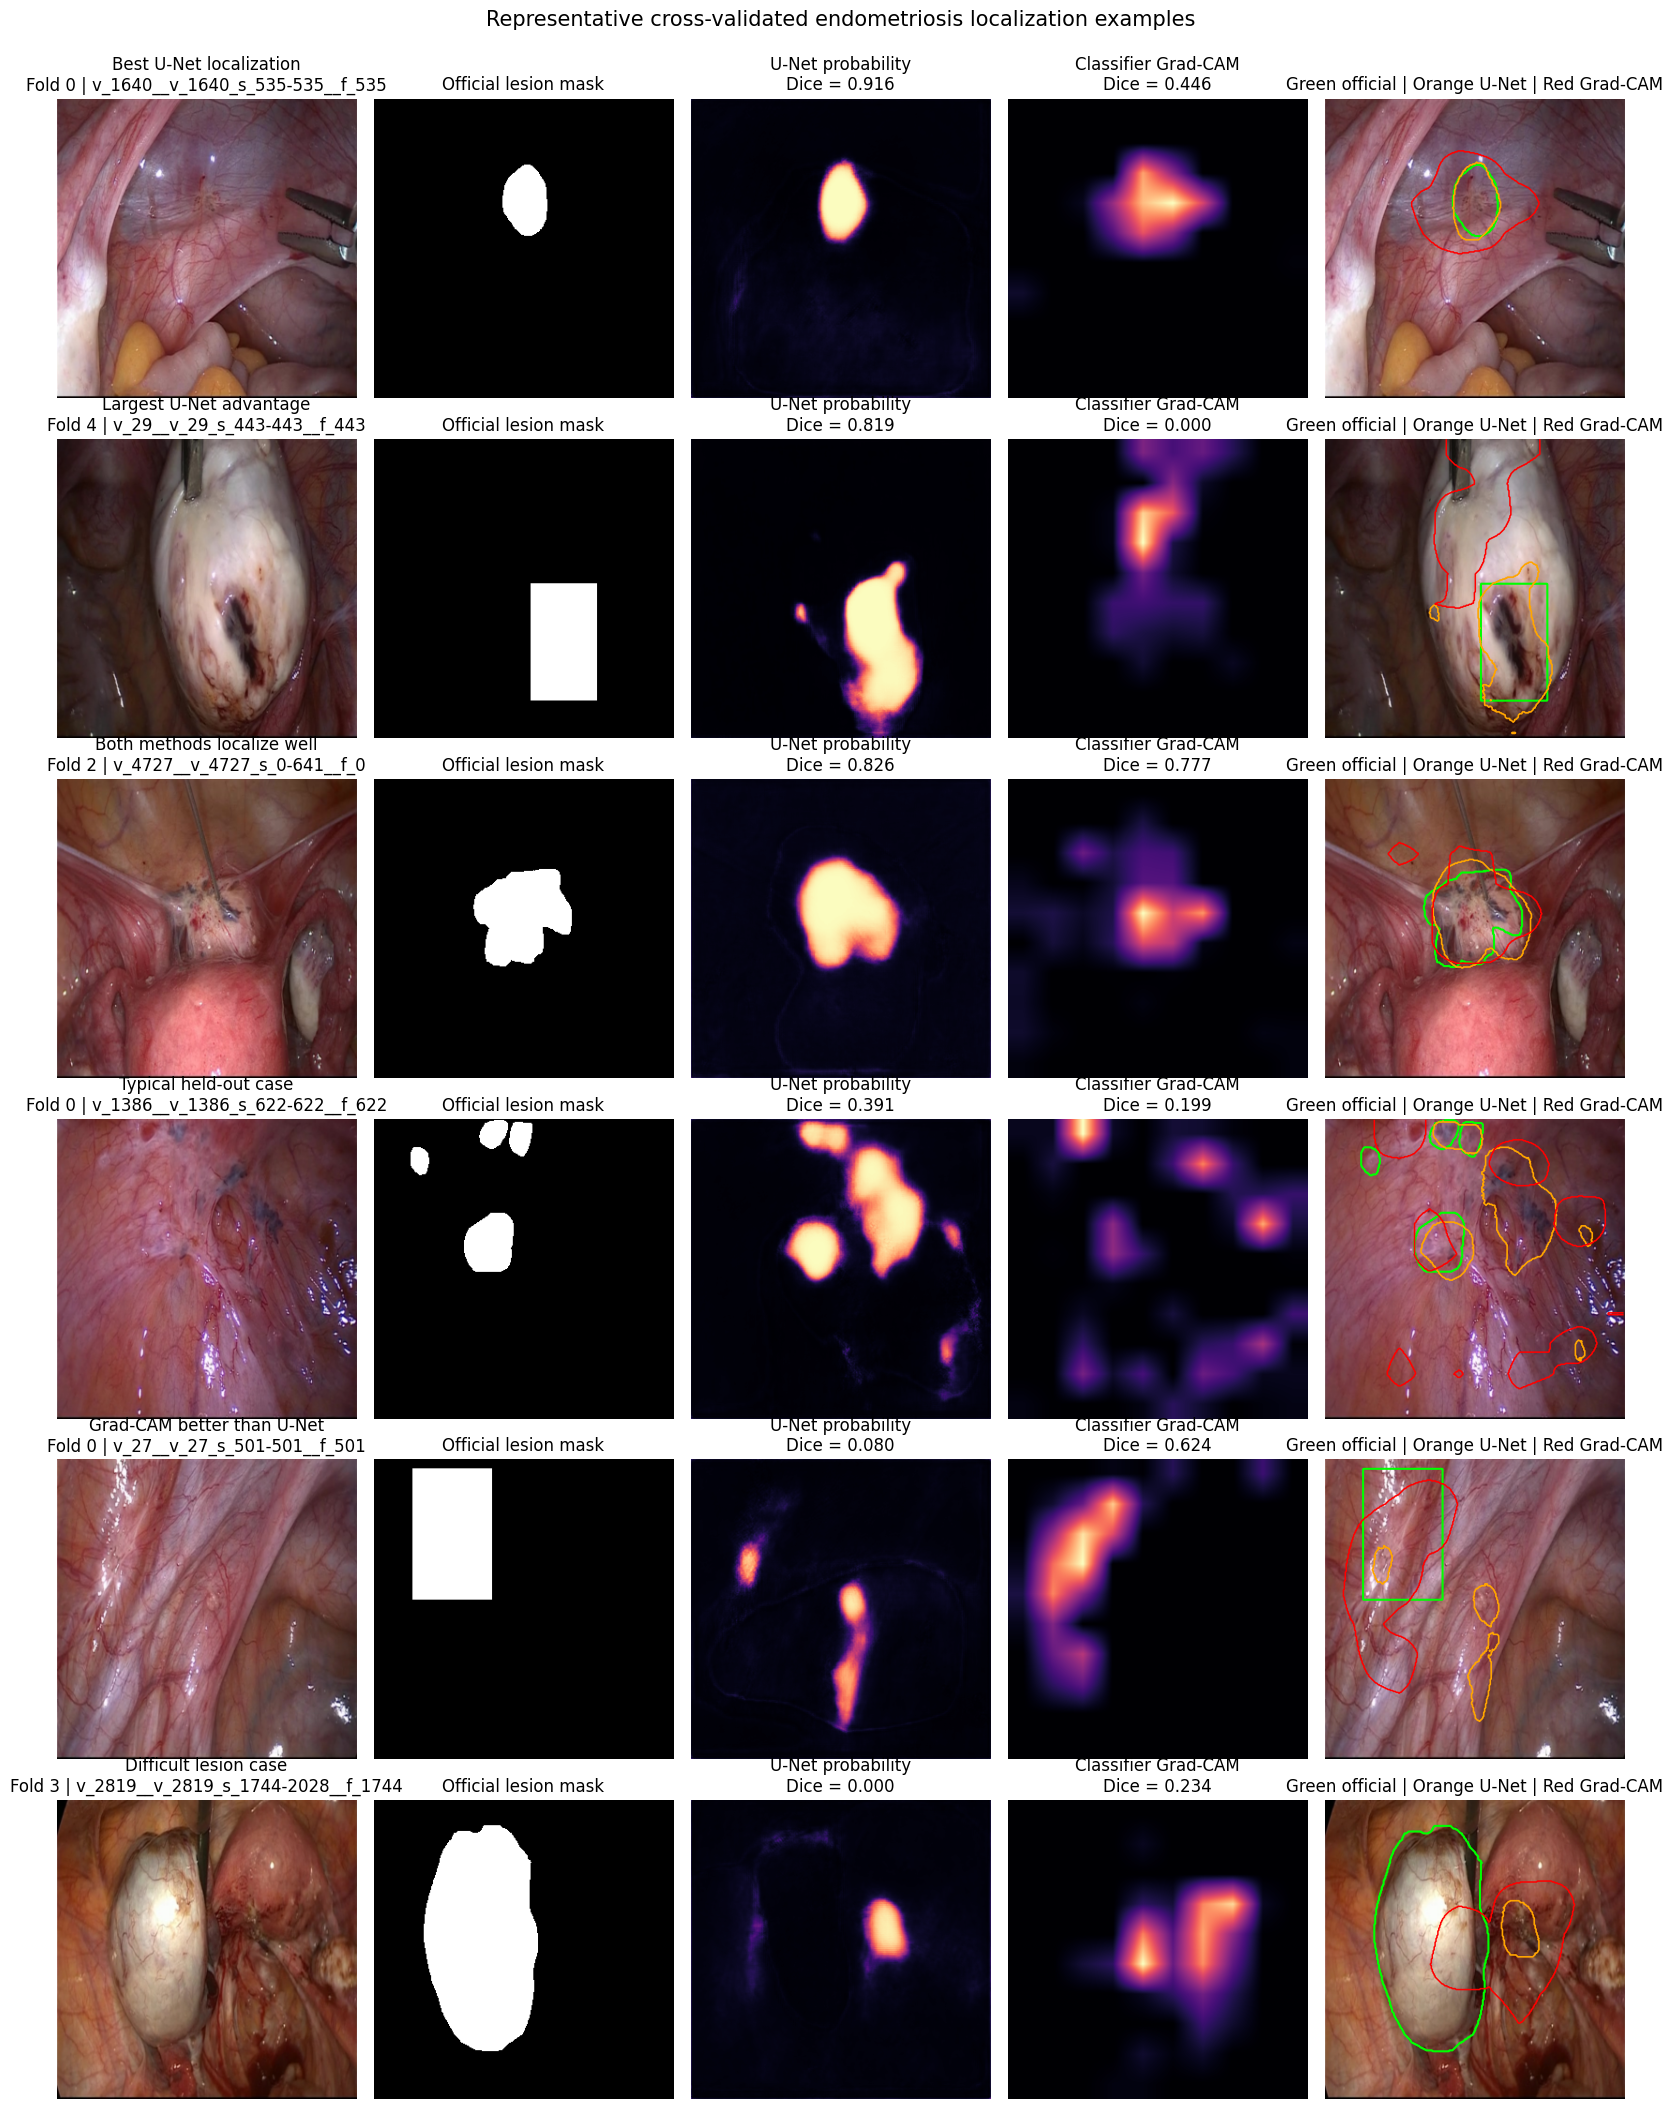

================ QUALITATIVE FIGURE COMPLETE ================
Selected cases: /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/all_folds_gradcam_comparison/qualitative_examples_selected_cases.csv
Final figure: /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/all_folds_gradcam_comparison/figure_qualitative_unet_vs_gradcam_examples.png

No training was performed.


In [5]:
# ============================================================
# STEP 19 — FINAL QUALITATIVE FIGURE FOR THE PAPER
#
# Creates representative held-out examples showing:
#   image | official mask | U-Net probability | Grad-CAM |
#   combined outline comparison
#
# No training. Only six quick U-Net inferences.
# ============================================================

from google.colab import drive
from pathlib import Path
import sys
import subprocess
import importlib.util

if importlib.util.find_spec("segmentation_models_pytorch") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "segmentation-models-pytorch"
    ])

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
import segmentation_models_pytorch as smp

try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

COMPARISON_DIR = (
    PROJECT_DIR / "outputs" / "all_folds_gradcam_comparison"
)

PER_IMAGE_CSV = (
    COMPARISON_DIR / "all_folds_gradcam_vs_unet_per_image.csv"
)

OUTPUT_FIGURE = (
    COMPARISON_DIR / "figure_qualitative_unet_vs_gradcam_examples.png"
)

SELECTED_CASES_CSV = (
    COMPARISON_DIR / "qualitative_examples_selected_cases.csv"
)

assert PER_IMAGE_CSV.exists(), f"Missing: {PER_IMAGE_CSV}"

IMAGE_SIZE = 320
UNET_THRESHOLD = 0.50
GRADCAM_THRESHOLD = 0.20

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
results = pd.read_csv(PER_IMAGE_CSV)

assert len(results) == 302

# ------------------------------------------------------------
# 1. Select six different, meaningful cases
# ------------------------------------------------------------
selected_rows = []
selected_ids = set()

def add_case(row, category):
    sample_id = row["sample_id"]

    if sample_id not in selected_ids:
        copied = row.copy()
        copied["selection_reason"] = category
        selected_rows.append(copied)
        selected_ids.add(sample_id)

# Strong U-Net segmentation.
add_case(
    results.sort_values("unet_dice_at_0p50", ascending=False).iloc[0],
    "Best U-Net localization",
)

# Largest U-Net advantage over Grad-CAM.
add_case(
    results.sort_values(
        "dice_difference_unet_minus_gradcam",
        ascending=False,
    ).iloc[0],
    "Largest U-Net advantage",
)

# Both methods provide useful localization.
both_good = results.assign(
    combined_score=(
        results["unet_dice_at_0p50"] + results["gradcam_dice"]
    )
).sort_values("combined_score", ascending=False)

for _, row in both_good.iterrows():
    if row["sample_id"] not in selected_ids:
        add_case(row, "Both methods localize well")
        break

# Typical U-Net advantage near median.
median_difference = results[
    "dice_difference_unet_minus_gradcam"
].median()

typical = results.assign(
    distance_to_median=np.abs(
        results["dice_difference_unet_minus_gradcam"]
        - median_difference
    )
).sort_values("distance_to_median")

for _, row in typical.iterrows():
    if row["sample_id"] not in selected_ids:
        add_case(row, "Typical held-out case")
        break

# Important counterexample: Grad-CAM is better than U-Net.
add_case(
    results.sort_values(
        "dice_difference_unet_minus_gradcam",
        ascending=True,
    ).iloc[0],
    "Grad-CAM better than U-Net",
)

# Difficult lesion case: poor U-Net Dice.
worst_unet = results.sort_values("unet_dice_at_0p50", ascending=True)

for _, row in worst_unet.iterrows():
    if row["sample_id"] not in selected_ids:
        add_case(row, "Difficult lesion case")
        break

selected = pd.DataFrame(selected_rows).reset_index(drop=True)

assert len(selected) == 6, "Could not select six unique cases."

selected.to_csv(SELECTED_CASES_CSV, index=False)

# ------------------------------------------------------------
# 2. Load the correct U-Net for each selected fold
# ------------------------------------------------------------
unet_models = {}

def get_unet_model(fold):
    if fold not in unet_models:
        checkpoint_path = (
            PROJECT_DIR / "checkpoints"
            / f"segmentation_unet_fold_{fold}"
            / "best_validation_dice.pt"
        )

        assert checkpoint_path.exists(), (
            f"Missing U-Net checkpoint: {checkpoint_path}"
        )

        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False,
        )

        model = smp.Unet(
            encoder_name="resnet34",
            encoder_weights=None,
            in_channels=3,
            classes=1,
            activation=None,
        ).to(device)

        model.load_state_dict(checkpoint["model_state"])
        model.eval()

        unet_models[fold] = model

    return unet_models[fold]

def unet_probability_map(image_path, fold):
    with Image.open(image_path) as image:
        image = image.convert("RGB").resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            resample=Image.Resampling.BILINEAR,
        )

        image_array = np.asarray(image, dtype=np.float32) / 255.0

    normalized = (image_array - IMAGENET_MEAN) / IMAGENET_STD

    input_tensor = torch.from_numpy(
        np.transpose(normalized, (2, 0, 1)).copy()
    ).unsqueeze(0).float().to(device)

    model = get_unet_model(int(fold))

    with torch.no_grad():
        probability = torch.sigmoid(model(input_tensor))[0, 0]

    return probability.cpu().numpy()

# ------------------------------------------------------------
# 3. Build the paper-ready figure
# ------------------------------------------------------------
fig, axes = plt.subplots(
    len(selected),
    5,
    figsize=(16, 3.5 * len(selected)),
)

for axis_row, (_, row) in zip(axes, selected.iterrows()):
    with Image.open(row["image_path"]) as image:
        image = image.convert("RGB").resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            resample=Image.Resampling.BILINEAR,
        )
        image_array = np.asarray(image)

    with Image.open(row["mask_path"]) as mask:
        mask = mask.convert("L").resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            resample=Image.Resampling.NEAREST,
        )
        official_mask = np.asarray(mask) > 0

    unet_probability = unet_probability_map(
        row["image_path"],
        row["fold"],
    )

    unet_prediction = unet_probability >= UNET_THRESHOLD

    with Image.open(row["gradcam_heatmap_path"]) as heatmap:
        gradcam_probability = (
            np.asarray(
                heatmap.convert("L").resize(
                    (IMAGE_SIZE, IMAGE_SIZE),
                    resample=Image.Resampling.BILINEAR,
                ),
                dtype=np.float32,
            )
            / 255.0
        )

    gradcam_prediction = gradcam_probability >= GRADCAM_THRESHOLD

    # Column 1: original image.
    axis_row[0].imshow(image_array)
    axis_row[0].set_title(
        f"{row['selection_reason']}\n"
        f"Fold {int(row['fold'])} | {row['sample_id']}"
    )
    axis_row[0].axis("off")

    # Column 2: official lesion mask.
    axis_row[1].imshow(official_mask, cmap="gray", vmin=0, vmax=1)
    axis_row[1].set_title("Official lesion mask")
    axis_row[1].axis("off")

    # Column 3: U-Net probability.
    axis_row[2].imshow(unet_probability, cmap="magma", vmin=0, vmax=1)
    axis_row[2].set_title(
        f"U-Net probability\nDice = {row['unet_dice_at_0p50']:.3f}"
    )
    axis_row[2].axis("off")

    # Column 4: Grad-CAM probability.
    axis_row[3].imshow(gradcam_probability, cmap="magma", vmin=0, vmax=1)
    axis_row[3].set_title(
        f"Classifier Grad-CAM\nDice = {row['gradcam_dice']:.3f}"
    )
    axis_row[3].axis("off")

    # Column 5: all boundaries together.
    axis_row[4].imshow(image_array)

    axis_row[4].contour(
        official_mask,
        colors="lime",
        linewidths=1.5,
    )

    if unet_prediction.any():
        axis_row[4].contour(
            unet_prediction,
            colors="orange",
            linewidths=1.2,
        )

    if gradcam_prediction.any():
        axis_row[4].contour(
            gradcam_prediction,
            colors="red",
            linewidths=1.1,
        )

    axis_row[4].set_title(
        "Green official | Orange U-Net | Red Grad-CAM"
    )
    axis_row[4].axis("off")

fig.suptitle(
    "Representative cross-validated endometriosis localization examples",
    fontsize=15,
    y=1.002,
)

plt.tight_layout()
plt.savefig(OUTPUT_FIGURE, dpi=250, bbox_inches="tight")
plt.show()

print("================ QUALITATIVE FIGURE COMPLETE ================")
print("Selected cases:", SELECTED_CASES_CSV)
print("Final figure:", OUTPUT_FIGURE)
print("\nNo training was performed.")

In [7]:
# ============================================================
# FINAL RESULTS PACKAGE — CORRECTED FOR SAVED GLENDA OUTPUTS
# No training. No checkpoint changes.
# ============================================================

from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd

from google.colab import drive

# ------------------------------------------------------------
# 1. Mount Drive and define folders
# ------------------------------------------------------------
try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

EVAL_DIR = PROJECT_DIR / "outputs" / "all_folds_evaluation"
COMPARE_DIR = PROJECT_DIR / "outputs" / "all_folds_gradcam_comparison"
REPORT_DIR = PROJECT_DIR / "outputs" / "final_results_package"
FIGURES_DIR = REPORT_DIR / "figures_for_paper"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

FOLD_METRICS_PATH = EVAL_DIR / "cross_validation_metrics_by_fold.csv"
CV_SUMMARY_PATH = EVAL_DIR / "cross_validation_summary.json"
GRADCAM_IMAGE_PATH = (
    COMPARE_DIR / "all_folds_gradcam_vs_unet_per_image.csv"
)
GRADCAM_VIDEO_PATH = (
    COMPARE_DIR / "all_folds_gradcam_vs_unet_video_level.csv"
)
GRADCAM_SUMMARY_PATH = (
    COMPARE_DIR / "all_folds_gradcam_vs_unet_summary.json"
)

required = [
    FOLD_METRICS_PATH,
    CV_SUMMARY_PATH,
    GRADCAM_IMAGE_PATH,
    GRADCAM_VIDEO_PATH,
    GRADCAM_SUMMARY_PATH,
]

missing = [str(path) for path in required if not path.exists()]
assert not missing, (
    "These required files are missing:\n" + "\n".join(missing)
)

# ------------------------------------------------------------
# 2. Load saved outputs
# ------------------------------------------------------------
fold_metrics = pd.read_csv(FOLD_METRICS_PATH)
gradcam_images = pd.read_csv(GRADCAM_IMAGE_PATH)
gradcam_videos = pd.read_csv(GRADCAM_VIDEO_PATH)

with open(CV_SUMMARY_PATH, "r") as f:
    cv_summary = json.load(f)

with open(GRADCAM_SUMMARY_PATH, "r") as f:
    gradcam_summary = json.load(f)

print("================ INPUT FILES LOADED ================\n")
print("Five-fold metric columns:")
print(list(fold_metrics.columns))

print("\nGrad-CAM image-level columns:")
print(list(gradcam_images.columns))

print("\nGrad-CAM video-level columns:")
print(list(gradcam_videos.columns))

# ------------------------------------------------------------
# 3. Helper functions
# ------------------------------------------------------------
def find_column(df, exact_candidates, required=True):
    """
    Finds a dataframe column by trying exact names first,
    then normalized names.
    """
    normalized_map = {
        col.lower().replace(" ", "_").replace("-", "_"): col
        for col in df.columns
    }

    for candidate in exact_candidates:
        candidate_normalized = (
            candidate.lower().replace(" ", "_").replace("-", "_")
        )
        if candidate_normalized in normalized_map:
            return normalized_map[candidate_normalized]

    if required:
        raise KeyError(
            "Could not find a required column.\n"
            f"Tried: {exact_candidates}\n"
            f"Available: {list(df.columns)}"
        )

    return None


def find_score_column(df, method_name):
    """
    Finds a Dice-score column for either U-Net or Grad-CAM,
    even if the precise saved column name differs slightly.
    """
    method_name = method_name.lower()

    preferred_candidates = {
        "unet": [
            "unet_dice_at_0p50",
            "unet_dice",
            "unet_mean_dice",
            "unet_mean_positive_dice_at_0p50",
        ],
        "gradcam": [
            "gradcam_dice_at_0p20",
            "gradcam_dice",
            "grad_cam_dice",
            "gradcam_mean_dice",
        ],
    }

    exact = find_column(
        df,
        preferred_candidates[method_name],
        required=False,
    )

    if exact is not None:
        return exact

    # Flexible fallback: search for a column containing both
    # the method name and the word "dice".
    for col in df.columns:
        name = col.lower().replace("-", "_")
        if method_name in name and "dice" in name:
            return col

    raise KeyError(
        f"Could not locate the {method_name} Dice column.\n"
        f"Available columns: {list(df.columns)}"
    )


def flatten_dictionary(data, prefix=""):
    """
    Turns nested JSON dictionaries into one flat dictionary.
    """
    flat = {}

    if isinstance(data, dict):
        for key, value in data.items():
            new_prefix = f"{prefix}.{key}" if prefix else str(key)
            flat.update(flatten_dictionary(value, new_prefix))
    else:
        flat[prefix] = data

    return flat


def find_json_value(data, required_terms, default=np.nan):
    """
    Searches the summary JSON for a numeric value whose key contains
    all requested terms. Example: ['bootstrap', 'lower'].
    """
    flat = flatten_dictionary(data)

    for key, value in flat.items():
        normalized_key = key.lower().replace("-", "_").replace(" ", "_")
        if all(term.lower() in normalized_key for term in required_terms):
            if isinstance(value, (int, float, np.integer, np.floating)):
                return float(value)

    return default


# ------------------------------------------------------------
# 4. Use the exact metric columns in your saved file
# ------------------------------------------------------------
fold_col = "fold"
auc_col = "classifier_auc"
balanced_accuracy_col = "classifier_balanced_accuracy_at_0p50"
f1_col = "classifier_f1_at_0p50"
unet_dice_col = "unet_mean_positive_dice_at_0p50"
unet_median_dice_col = "unet_median_positive_dice_at_0p50"
unet_iou_col = "unet_mean_positive_iou_at_0p50"
unet_fp_col = "unet_negative_fp_image_rate_at_0p50"

expected_columns = [
    fold_col,
    auc_col,
    balanced_accuracy_col,
    f1_col,
    unet_dice_col,
    unet_median_dice_col,
    unet_iou_col,
    unet_fp_col,
]

missing_metric_columns = [
    col for col in expected_columns if col not in fold_metrics.columns
]

assert not missing_metric_columns, (
    "Expected metric column(s) missing:\n"
    + "\n".join(missing_metric_columns)
)

# ------------------------------------------------------------
# 5. Table 1 — five-fold model performance
# ------------------------------------------------------------
table_1 = pd.DataFrame({
    "Validation fold": fold_metrics[fold_col].astype(int),
    "Classifier ROC-AUC": fold_metrics[auc_col],
    "Classifier balanced accuracy": fold_metrics[balanced_accuracy_col],
    "Classifier F1-score": fold_metrics[f1_col],
    "U-Net mean Dice": fold_metrics[unet_dice_col],
    "U-Net median Dice": fold_metrics[unet_median_dice_col],
    "U-Net mean IoU": fold_metrics[unet_iou_col],
    "U-Net negative-image FP rate": fold_metrics[unet_fp_col],
})

metric_columns = list(table_1.columns[1:])
table_1[metric_columns] = table_1[metric_columns].round(4)

mean_row = {"Validation fold": "Mean"}
std_row = {"Validation fold": "Standard deviation"}

for col in metric_columns:
    mean_row[col] = round(table_1[col].mean(), 4)
    std_row[col] = round(table_1[col].std(ddof=1), 4)

table_1 = pd.concat(
    [table_1, pd.DataFrame([mean_row, std_row])],
    ignore_index=True,
)

table_1_path = REPORT_DIR / "table_1_five_fold_performance.csv"
table_1.to_csv(table_1_path, index=False)

# ------------------------------------------------------------
# 6. Table 2 — U-Net versus classifier Grad-CAM
# ------------------------------------------------------------
unet_image_dice_col = find_score_column(gradcam_images, "unet")
gradcam_image_dice_col = find_score_column(gradcam_images, "gradcam")

unet_video_dice_col = find_score_column(gradcam_videos, "unet")
gradcam_video_dice_col = find_score_column(gradcam_videos, "gradcam")

n_pathology_images = len(gradcam_images)
n_pathology_videos = len(gradcam_videos)

unet_image_dice = gradcam_images[unet_image_dice_col].mean()
gradcam_image_dice = gradcam_images[gradcam_image_dice_col].mean()

unet_video_dice = gradcam_videos[unet_video_dice_col].mean()
gradcam_video_dice = gradcam_videos[gradcam_video_dice_col].mean()

difference_per_video = (
    gradcam_videos[unet_video_dice_col]
    - gradcam_videos[gradcam_video_dice_col]
)

mean_video_difference = difference_per_video.mean()
unet_better_videos = int((difference_per_video > 0).sum())
gradcam_better_videos = int((difference_per_video < 0).sum())
tied_videos = int((difference_per_video == 0).sum())

table_2 = pd.DataFrame([
    {
        "Analysis unit": "Pathology image",
        "Number of units": n_pathology_images,
        "U-Net mean Dice": unet_image_dice,
        "Grad-CAM mean Dice": gradcam_image_dice,
        "Difference (U-Net − Grad-CAM)": (
            unet_image_dice - gradcam_image_dice
        ),
    },
    {
        "Analysis unit": "Pathology video",
        "Number of units": n_pathology_videos,
        "U-Net mean Dice": unet_video_dice,
        "Grad-CAM mean Dice": gradcam_video_dice,
        "Difference (U-Net − Grad-CAM)": mean_video_difference,
    },
])

for col in table_2.columns[2:]:
    table_2[col] = pd.to_numeric(table_2[col], errors="coerce").round(4)

table_2_path = REPORT_DIR / "table_2_unet_vs_gradcam_localization.csv"
table_2.to_csv(table_2_path, index=False)

# ------------------------------------------------------------
# 7. Obtain optional confidence interval and p-value from JSON
# ------------------------------------------------------------
bootstrap_ci_low = find_json_value(
    gradcam_summary,
    ["bootstrap", "lower"],
)

bootstrap_ci_high = find_json_value(
    gradcam_summary,
    ["bootstrap", "upper"],
)

wilcoxon_p = find_json_value(
    gradcam_summary,
    ["wilcoxon", "p"],
)

# ------------------------------------------------------------
# 8. Make final paper-ready Results report
# ------------------------------------------------------------
classifier_auc_mean = fold_metrics[auc_col].mean()
classifier_auc_sd = fold_metrics[auc_col].std(ddof=1)

unet_dice_mean = fold_metrics[unet_dice_col].mean()
unet_dice_sd = fold_metrics[unet_dice_col].std(ddof=1)

unet_iou_mean = fold_metrics[unet_iou_col].mean()
unet_fp_mean = fold_metrics[unet_fp_col].mean()

results_report = f"""# GLENDA Cross-Validated Results Report

## Task definition

This study evaluates frame-level classification and lesion localization of
visible endometriosis pathology in selected laparoscopic images from GLENDA
v1.0. It is not a patient-level diagnostic system and does not establish
clinical diagnostic performance.

## Validation design

A strict five-fold video-level cross-validation protocol was applied. All
frames from a given video were placed in the same fold, preventing video-level
data leakage between training and held-out validation sets.

## Classification results

The ImageNet-pretrained EdgeNeXt-Small classifier achieved a mean fold-level
ROC-AUC of {classifier_auc_mean:.3f} ± {classifier_auc_sd:.3f}
(mean ± standard deviation over five held-out folds).

Fold-level ROC-AUC is the primary classification result. Pooled probabilities
from separately trained fold models should not be used as the primary metric
because their probability calibration can differ.

## Segmentation results

The U-Net with an ImageNet-pretrained ResNet-34 encoder achieved mean
positive-image Dice of {unet_dice_mean:.3f} ± {unet_dice_sd:.3f} across the
five held-out folds. Its mean positive-image IoU was {unet_iou_mean:.3f}.

At the fixed probability threshold of 0.50, the mean negative-image
false-positive image rate was {unet_fp_mean:.3f}. This is an important
limitation and should be reported transparently.

## Localization comparison: U-Net versus Grad-CAM

Across {n_pathology_images} held-out pathology images and
{n_pathology_videos} held-out pathology videos, direct U-Net segmentation
provided stronger localization than post-hoc classifier Grad-CAM.

At video level, U-Net achieved mean Dice of {unet_video_dice:.3f}, compared
with {gradcam_video_dice:.3f} for classifier Grad-CAM. The mean paired
difference was {mean_video_difference:.3f} in favour of U-Net.
"""

if pd.notna(bootstrap_ci_low) and pd.notna(bootstrap_ci_high):
    results_report += (
        f"The reported bootstrap 95% confidence interval was "
        f"[{bootstrap_ci_low:.3f}, {bootstrap_ci_high:.3f}].\n"
    )

if pd.notna(wilcoxon_p):
    results_report += (
        f"The saved Wilcoxon signed-rank test result was "
        f"p = {wilcoxon_p:.3e}.\n"
    )

results_report += f"""
U-Net localized better in {unet_better_videos} held-out pathology videos,
whereas Grad-CAM localized better in {gradcam_better_videos}; there were
{tied_videos} ties.

## Interpretation

The classifier achieved strong discrimination between selected pathology and
no-pathology laparoscopic frames. However, classification confidence and
anatomical localization are different objectives. Grad-CAM is a coarse
post-hoc explanation, whereas U-Net was trained directly with official
pixel-level lesion masks. The quantitative comparison supports U-Net as the
more accurate localization approach in this dataset.

## Limitations

- The dataset contains selected annotated laparoscopic frames, not a
  prospective clinical screening population.
- The study evaluates visible pathology within images, not patient-level
  endometriosis diagnosis.
- Results are internally cross-validated and have no external validation.
- The U-Net produced false-positive regions on a substantial proportion of
  no-pathology images.
- Grad-CAM used the fixed threshold of 0.20 selected in the Fold-0 pilot;
  this must be stated transparently in the paper.
"""

report_path = REPORT_DIR / "FINAL_RESULTS_REPORT.md"
report_path.write_text(results_report, encoding="utf-8")

# ------------------------------------------------------------
# 9. Save reproducibility information
# ------------------------------------------------------------
reproducibility = {
    "dataset": "GLENDA v1.0",
    "task": (
        "Frame-level classification and localization of visible "
        "endometriosis pathology in laparoscopic images"
    ),
    "validation_protocol": (
        "Five-fold video-level cross-validation with all frames "
        "from each video restricted to one fold"
    ),
    "classifier": "ImageNet-pretrained EdgeNeXt-Small",
    "segmentation_model": (
        "U-Net with ImageNet-pretrained ResNet-34 encoder"
    ),
    "classifier_primary_metric": "Mean fold-level ROC-AUC",
    "unet_threshold": 0.50,
    "gradcam_threshold": 0.20,
    "classifier_mean_fold_auc": float(classifier_auc_mean),
    "classifier_fold_auc_sd": float(classifier_auc_sd),
    "unet_mean_fold_dice": float(unet_dice_mean),
    "unet_fold_dice_sd": float(unet_dice_sd),
    "unet_video_dice": float(unet_video_dice),
    "gradcam_video_dice": float(gradcam_video_dice),
    "unet_minus_gradcam_video_dice": float(mean_video_difference),
}

reproducibility_path = REPORT_DIR / "reproducibility_record.json"

with open(reproducibility_path, "w") as f:
    json.dump(reproducibility, f, indent=2)

# ------------------------------------------------------------
# 10. Copy the best paper figures into one folder
# ------------------------------------------------------------
figures_to_copy = [
    EVAL_DIR / "figure_classifier_cross_validated_roc.png",
    EVAL_DIR / "figure_foldwise_model_performance.png",
    EVAL_DIR / "figure_unet_dice_distribution_by_fold.png",
    COMPARE_DIR / "figure_video_level_unet_vs_gradcam_scatter.png",
    COMPARE_DIR / "figure_image_level_unet_vs_gradcam_distribution.png",
    COMPARE_DIR / "figure_qualitative_unet_vs_gradcam_examples.png",
]

copied_figures = []

for figure_path in figures_to_copy:
    if figure_path.exists():
        destination = FIGURES_DIR / figure_path.name
        shutil.copy2(figure_path, destination)
        copied_figures.append(destination.name)

# ------------------------------------------------------------
# 11. Display final output
# ------------------------------------------------------------
print("\n================ FINAL RESULTS PACKAGE COMPLETE ================\n")

print("TABLE 1 — Five-fold cross-validation performance")
display(table_1)

print("\nTABLE 2 — U-Net versus classifier Grad-CAM localization")
display(table_2)

print("\nKey paper figures copied:")
for figure in copied_figures:
    print("-", figure)

print("\nSaved final package:")
print("-", REPORT_DIR)

print("\nImportant files:")
print("-", table_1_path)
print("-", table_2_path)
print("-", report_path)
print("-", reproducibility_path)

print("\nNo training was performed.")

Drive already mounted at /content/project_drive_2026; to attempt to forcibly remount, call drive.mount("/content/project_drive_2026", force_remount=True).
================ INPUT FILES LOADED ================

Five-fold metric columns:
['fold', 'classifier_checkpoint_epoch', 'classifier_auc', 'classifier_accuracy_at_0p50', 'classifier_balanced_accuracy_at_0p50', 'classifier_f1_at_0p50', 'unet_checkpoint_epoch', 'unet_mean_positive_dice_at_0p50', 'unet_median_positive_dice_at_0p50', 'unet_mean_positive_iou_at_0p50', 'unet_negative_fp_image_rate_at_0p50', 'validation_images', 'validation_pathology_images', 'validation_no_pathology_images', 'validation_videos']

Grad-CAM image-level columns:
['sample_id', 'fold', 'video_id', 'lesion_classes', 'image_path', 'mask_path', 'gradcam_heatmap_path', 'classifier_pathology_probability', 'gradcam_threshold', 'gradcam_foreground_fraction', 'gradcam_dice', 'gradcam_iou', 'unet_dice_at_0p50', 'unet_iou_at_0p50', 'dice_difference_unet_minus_gradcam', 'i

,Validation fold,Classifier ROC-AUC,Classifier balanced accuracy,Classifier F1-score,U-Net mean Dice,U-Net median Dice,U-Net mean IoU,U-Net negative-image FP rate
0,0,0.9623,0.8962,0.9134,0.5001,0.5633,0.3666,0.7000
1,1,0.9817,0.9596,0.9592,0.4397,0.4899,0.3143,0.3400
2,2,0.9675,0.6857,0.7250,0.3629,0.3526,0.2550,0.5000
3,3,0.9641,0.9068,0.9048,0.4349,0.5033,0.3179,0.3167
4,4,0.9502,0.8762,0.8923,0.4510,0.4763,0.3293,0.5400
5,Mean,0.9652,0.8649,0.8789,0.4377,0.4771,0.3166,0.4793
6,Standard deviation,0.0113,0.1048,0.0897,0.0492,0.0771,0.0402,0.1571



TABLE 2 — U-Net versus classifier Grad-CAM localization


,Analysis unit,Number of units,U-Net mean Dice,Grad-CAM mean Dice,Difference (U-Net − Grad-CAM)
0,Pathology image,302,0.4394,0.2486,0.1908
1,Pathology video,168,0.4590,0.2739,0.1852



Key paper figures copied:
- figure_classifier_cross_validated_roc.png
- figure_foldwise_model_performance.png
- figure_unet_dice_distribution_by_fold.png
- figure_video_level_unet_vs_gradcam_scatter.png
- figure_image_level_unet_vs_gradcam_distribution.png
- figure_qualitative_unet_vs_gradcam_examples.png

Saved final package:
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/final_results_package

Important files:
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/final_results_package/table_1_five_fold_performance.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/final_results_package/table_2_unet_vs_gradcam_localization.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/final_results_package/FINAL_RESULTS_REPORT.md
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/final_results_package/reproducibility_record.json

No training was performed.


Drive already mounted at /content/project_drive_2026; to attempt to forcibly remount, call drive.mount("/content/project_drive_2026", force_remount=True).
Available prediction columns:
['image_path', 'label', 'patient_id', 'video_id', 'sample_id', 'fold_role', 'fold', 'classifier_checkpoint_epoch', 'true_label', 'pathology_probability', 'prediction_at_0p50']


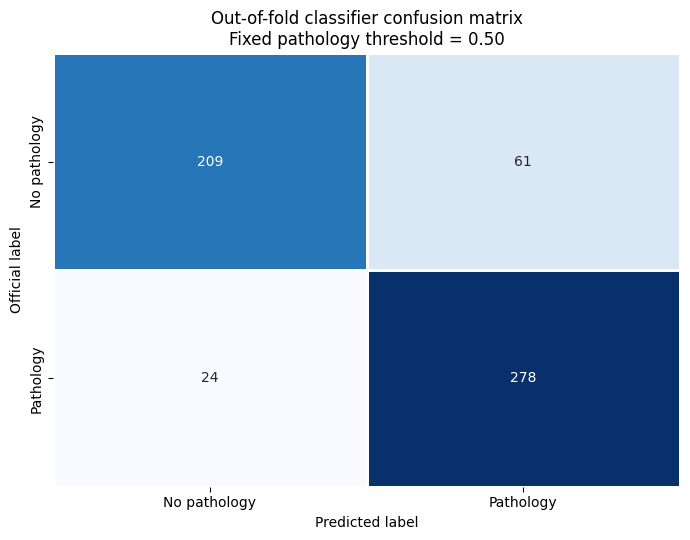

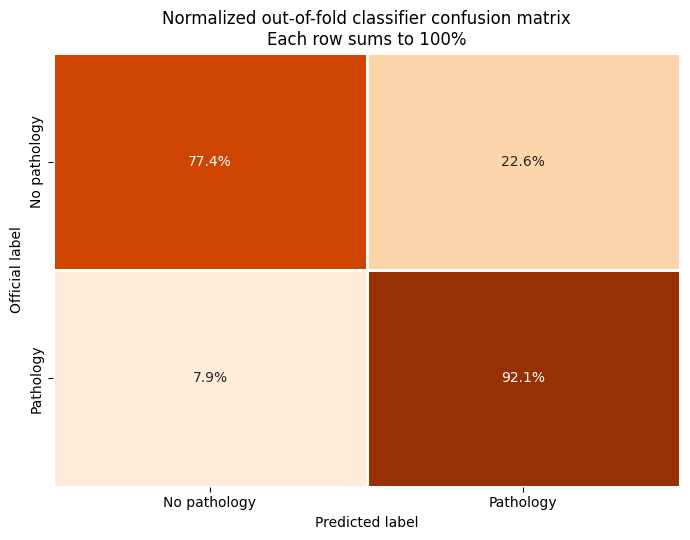


================ CONFUSION-MATRIX FIGURES COMPLETE ================

Held-out images: 572
True negatives:  209
False positives: 61
False negatives: 24
True positives:  278
Sensitivity:     0.921
Specificity:     0.774
Accuracy:        0.851

Saved:
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/additional_paper_figures/figure_classifier_confusion_matrix_counts.png
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/additional_paper_figures/figure_classifier_confusion_matrix_normalized.png
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/additional_paper_figures/classifier_oof_confusion_matrix_counts.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/additional_paper_figures/classifier_oof_confusion_matrix_metrics.json


In [8]:
# ============================================================
# ADDITIONAL FIGURE 1 — OUT-OF-FOLD CLASSIFIER CONFUSION MATRICES
# No training. Uses only saved held-out predictions.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from google.colab import drive

try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

EVAL_DIR = PROJECT_DIR / "outputs" / "all_folds_evaluation"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "additional_paper_figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PREDICTIONS_PATH = EVAL_DIR / "classifier_out_of_fold_predictions.csv"
assert PREDICTIONS_PATH.exists(), f"Missing: {PREDICTIONS_PATH}"

predictions = pd.read_csv(PREDICTIONS_PATH)

print("Available prediction columns:")
print(list(predictions.columns))

def find_column(df, candidates):
    normalized = {
        col.lower().replace(" ", "_").replace("-", "_"): col
        for col in df.columns
    }

    for candidate in candidates:
        key = candidate.lower().replace(" ", "_").replace("-", "_")
        if key in normalized:
            return normalized[key]

    raise KeyError(
        f"Could not find one of {candidates}.\n"
        f"Available columns: {list(df.columns)}"
    )

label_col = find_column(
    predictions,
    ["label", "true_label", "ground_truth_label", "target"]
)

probability_col = find_column(
    predictions,
    [
        "classifier_pathology_probability",
        "pathology_probability",
        "predicted_pathology_probability",
        "probability",
        "positive_probability",
    ]
)

y_true = predictions[label_col].astype(int).to_numpy()
y_probability = predictions[probability_col].astype(float).to_numpy()
y_pred = (y_probability >= 0.50).astype(int)

cm_counts = confusion_matrix(y_true, y_pred, labels=[0, 1])
cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1],
    normalize="true",
)

summary = pd.DataFrame(
    cm_counts,
    index=["True no-pathology", "True pathology"],
    columns=["Predicted no-pathology", "Predicted pathology"],
)

summary_path = OUTPUT_DIR / "classifier_oof_confusion_matrix_counts.csv"
summary.to_csv(summary_path)

# -------------------------
# Count confusion matrix
# -------------------------
plt.figure(figsize=(7, 5.5))
sns.heatmap(
    cm_counts,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No pathology", "Pathology"],
    yticklabels=["No pathology", "Pathology"],
    linewidths=1,
    linecolor="white",
)
plt.title(
    "Out-of-fold classifier confusion matrix\n"
    "Fixed pathology threshold = 0.50"
)
plt.xlabel("Predicted label")
plt.ylabel("Official label")
plt.tight_layout()

counts_figure_path = OUTPUT_DIR / "figure_classifier_confusion_matrix_counts.png"
plt.savefig(counts_figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# -------------------------
# Normalized confusion matrix
# -------------------------
plt.figure(figsize=(7, 5.5))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".1%",
    cmap="Oranges",
    cbar=False,
    xticklabels=["No pathology", "Pathology"],
    yticklabels=["No pathology", "Pathology"],
    linewidths=1,
    linecolor="white",
    vmin=0,
    vmax=1,
)
plt.title(
    "Normalized out-of-fold classifier confusion matrix\n"
    "Each row sums to 100%"
)
plt.xlabel("Predicted label")
plt.ylabel("Official label")
plt.tight_layout()

normalized_figure_path = (
    OUTPUT_DIR / "figure_classifier_confusion_matrix_normalized.png"
)
plt.savefig(normalized_figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

tn, fp, fn, tp = cm_counts.ravel()

metrics = {
    "threshold": 0.50,
    "held_out_images": int(len(y_true)),
    "true_negatives": int(tn),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_positives": int(tp),
    "sensitivity": float(tp / (tp + fn)) if (tp + fn) else np.nan,
    "specificity": float(tn / (tn + fp)) if (tn + fp) else np.nan,
    "accuracy": float((tp + tn) / len(y_true)),
}

metrics_path = OUTPUT_DIR / "classifier_oof_confusion_matrix_metrics.json"

import json
with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

print("\n================ CONFUSION-MATRIX FIGURES COMPLETE ================\n")
print(f"Held-out images: {metrics['held_out_images']}")
print(f"True negatives:  {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True positives:  {tp}")
print(f"Sensitivity:     {metrics['sensitivity']:.3f}")
print(f"Specificity:     {metrics['specificity']:.3f}")
print(f"Accuracy:        {metrics['accuracy']:.3f}")

print("\nSaved:")
print("-", counts_figure_path)
print("-", normalized_figure_path)
print("-", summary_path)
print("-", metrics_path)

Drive already mounted at /content/project_drive_2026; to attempt to forcibly remount, call drive.mount("/content/project_drive_2026", force_remount=True).
Device: cpu
Batch size: 8
Held-out pathology images for faithfulness test: 302
Held-out pathology videos: 168
Prepared interventions for 50/302 images
Prepared interventions for 100/302 images
Prepared interventions for 150/302 images
Prepared interventions for 200/302 images
Prepared interventions for 250/302 images
Prepared interventions for 300/302 images
Prepared interventions for 302/302 images
Loaded Fold-0 classifier checkpoint (selected epoch: unknown)
Loaded Fold-1 classifier checkpoint (selected epoch: unknown)
Loaded Fold-2 classifier checkpoint (selected epoch: unknown)
Loaded Fold-3 classifier checkpoint (selected epoch: unknown)
Loaded Fold-4 classifier checkpoint (selected epoch: unknown)


/tmp/ipykernel_1282/219941829.py:587: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


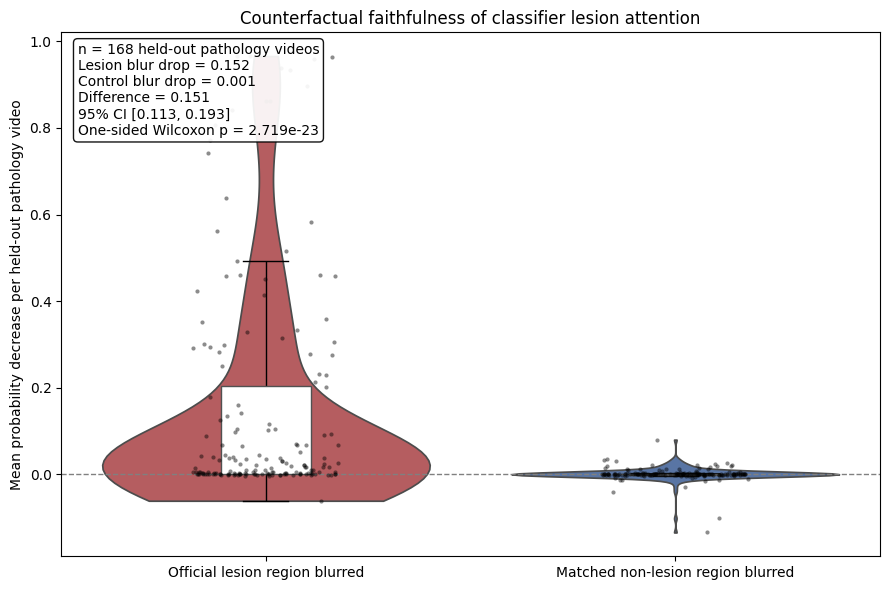


================ GRAD-CAM FAITHFULNESS TEST COMPLETE ================

Mean video-level probability drop after lesion blur: 0.1516
Mean video-level probability drop after control blur: 0.0007
Mean faithfulness difference (lesion minus control): 0.1508
Bootstrap 95% CI: [0.1129, 0.1927]
One-sided Wilcoxon p-value: 2.719e-23

Saved:
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/additional_paper_figures/gradcam_faithfulness_per_held_out_image.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/additional_paper_figures/gradcam_faithfulness_per_held_out_video.csv
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/additional_paper_figures/gradcam_faithfulness_summary.json
- /content/project_drive_2026/MyDrive/glenda_xai_localization/outputs/additional_paper_figures/figure_gradcam_counterfactual_faithfulness.png

No training was performed.


In [9]:
# ============================================================
# ADDITIONAL FIGURE 2 — GRAD-CAM FAITHFULNESS TEST
#
# Does the classifier actually rely on lesion pixels?
#
# For each held-out pathology image:
#   1. Measure the original pathology probability.
#   2. Blur the official lesion region and re-measure probability.
#   3. Blur a matched non-lesion control region and re-measure.
#
# A larger confidence drop after lesion blurring supports
# meaningful lesion-based classifier attention.
#
# No training. Uses saved best classifier checkpoints only.
# ============================================================

!pip -q install timm

from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFilter
from scipy.stats import wilcoxon
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
import timm

from google.colab import drive

try:
    drive.mount("/content/project_drive_2026")
except Exception:
    pass

# ------------------------------------------------------------
# 1. Paths and reproducibility settings
# ------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PROJECT_DIR = Path(
    "/content/project_drive_2026/MyDrive/glenda_xai_localization"
)

COMPARE_DIR = PROJECT_DIR / "outputs" / "all_folds_gradcam_comparison"
CHECKPOINT_ROOT = PROJECT_DIR / "checkpoints"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "additional_paper_figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = (
    COMPARE_DIR / "all_folds_gradcam_vs_unet_per_image.csv"
)

assert INPUT_PATH.exists(), f"Missing: {INPUT_PATH}"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 16 if DEVICE.type == "cuda" else 8

print(f"Device: {DEVICE}")
print(f"Batch size: {BATCH_SIZE}")

# ------------------------------------------------------------
# 2. Read only held-out pathology images
# ------------------------------------------------------------
data = pd.read_csv(INPUT_PATH)

required_columns = ["fold", "video_id", "image_path", "mask_path"]
missing_columns = [c for c in required_columns if c not in data.columns]

assert not missing_columns, (
    "Missing required columns: " + str(missing_columns)
)

data = data.copy()
data["fold"] = data["fold"].astype(int)

assert len(data) > 0, "No held-out pathology images were found."

for path_col in ["image_path", "mask_path"]:
    missing_paths = data.loc[
        ~data[path_col].map(lambda p: Path(p).exists()),
        path_col,
    ].tolist()

    assert not missing_paths, (
        f"Some saved paths are unavailable. First missing {path_col}: "
        f"{missing_paths[0]}"
    )

print(f"Held-out pathology images for faithfulness test: {len(data)}")
print(f"Held-out pathology videos: {data['video_id'].nunique()}")

# ------------------------------------------------------------
# 3. Image preprocessing identical in principle to validation
#    (resize to 320 x 320 and ImageNet normalization)
# ------------------------------------------------------------
IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406],
    dtype=torch.float32,
).view(3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225],
    dtype=torch.float32,
).view(3, 1, 1)

def image_to_tensor(image):
    """
    RGB PIL image -> normalized [3, 320, 320] tensor.
    """
    image = image.resize((320, 320), Image.BILINEAR)
    array = np.asarray(image, dtype=np.float32) / 255.0
    tensor = torch.from_numpy(array).permute(2, 0, 1)
    return (tensor - IMAGENET_MEAN) / IMAGENET_STD


def load_rgb_and_mask(image_path, mask_path):
    """
    Loads image and official binary lesion mask in matching original size.
    """
    image = Image.open(image_path).convert("RGB")
    mask = Image.open(mask_path).convert("L")

    if mask.size != image.size:
        mask = mask.resize(image.size, Image.NEAREST)

    mask_array = np.asarray(mask) > 0
    return image, mask_array


def shift_mask_without_wrap(mask, dx, dy):
    """
    Moves a binary mask without wrapping pixels from one image edge
    to the opposite edge.
    """
    height, width = mask.shape
    shifted = np.zeros_like(mask, dtype=bool)

    src_y0 = max(0, -dy)
    src_y1 = min(height, height - dy)
    src_x0 = max(0, -dx)
    src_x1 = min(width, width - dx)

    dst_y0 = max(0, dy)
    dst_y1 = min(height, height + dy)
    dst_x0 = max(0, dx)
    dst_x1 = min(width, width + dx)

    if src_y1 > src_y0 and src_x1 > src_x0:
        shifted[dst_y0:dst_y1, dst_x0:dst_x1] = (
            mask[src_y0:src_y1, src_x0:src_x1]
        )

    return shifted


def matched_nonlesion_control_mask(lesion_mask, rng):
    """
    Creates a translated lesion-shaped control region with minimal overlap
    with the official lesion. This gives a spatially matched intervention.
    """
    height, width = lesion_mask.shape
    lesion_pixels = lesion_mask.sum()

    best_candidate = None
    best_overlap = np.inf

    max_dx = max(1, int(width * 0.50))
    max_dy = max(1, int(height * 0.50))

    for _ in range(80):
        dx = int(rng.integers(-max_dx, max_dx + 1))
        dy = int(rng.integers(-max_dy, max_dy + 1))

        if dx == 0 and dy == 0:
            continue

        candidate = shift_mask_without_wrap(lesion_mask, dx, dy)
        candidate_pixels = candidate.sum()

        if candidate_pixels < 0.80 * lesion_pixels:
            continue

        overlap = np.logical_and(candidate, lesion_mask).sum()

        if overlap < best_overlap:
            best_overlap = overlap
            best_candidate = candidate

        if overlap <= 0.01 * lesion_pixels:
            break

    # Fallback for an unusually large lesion:
    if best_candidate is None:
        background = ~lesion_mask
        candidate = np.zeros_like(lesion_mask, dtype=bool)

        background_indices = np.flatnonzero(background)
        take = min(len(background_indices), int(lesion_pixels))

        chosen = rng.choice(
            background_indices,
            size=take,
            replace=False,
        )
        candidate.flat[chosen] = True
        best_candidate = candidate

    # Ensure the control never includes lesion pixels.
    best_candidate = np.logical_and(best_candidate, ~lesion_mask)
    return best_candidate


def blur_masked_region(image, region_mask, blur_radius=12):
    """
    Blurs only a chosen image region, preserving all other pixels.
    """
    original = np.asarray(image).copy()
    blurred = np.asarray(
        image.filter(ImageFilter.GaussianBlur(radius=blur_radius))
    )

    output = original.copy()
    output[region_mask] = blurred[region_mask]

    return Image.fromarray(output)


# ------------------------------------------------------------
# 4. Checkpoint/model helpers
# ------------------------------------------------------------
def extract_model_state(checkpoint):
    """
    Supports common checkpoint formats.
    """
    for key in [
        "model_state",
        "model_state_dict",
        "state_dict",
        "model",
    ]:
        if key in checkpoint and isinstance(checkpoint[key], dict):
            return checkpoint[key]

    # If the checkpoint itself looks like a state dictionary:
    if all(isinstance(v, torch.Tensor) for v in checkpoint.values()):
        return checkpoint

    raise KeyError(
        "Could not find model weights in the classifier checkpoint. "
        f"Available checkpoint keys: {list(checkpoint.keys())}"
    )


def load_fold_classifier(fold):
    checkpoint_path = (
        CHECKPOINT_ROOT
        / f"classifier_edgenext_fold_{fold}"
        / "best_validation_auc.pt"
    )

    assert checkpoint_path.exists(), (
        f"Missing classifier checkpoint: {checkpoint_path}"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    model = timm.create_model(
        "edgenext_small",
        pretrained=False,
        num_classes=2,
    )

    state = extract_model_state(checkpoint)

    # Handle checkpoints saved with DataParallel ("module." prefix).
    cleaned_state = {
        key.replace("module.", "", 1): value
        for key, value in state.items()
    }

    load_result = model.load_state_dict(cleaned_state, strict=True)

    assert not load_result.missing_keys, load_result.missing_keys
    assert not load_result.unexpected_keys, load_result.unexpected_keys

    model = model.to(DEVICE).eval()

    epoch = checkpoint.get("epoch", "unknown")

    print(
        f"Loaded Fold-{fold} classifier checkpoint "
        f"(selected epoch: {epoch})"
    )

    return model


@torch.no_grad()
def predict_pathology_probabilities(model, tensors):
    """
    Returns P(pathology), where pathology is class index 1.
    """
    batch = torch.stack(tensors).to(DEVICE)
    logits = model(batch)
    probabilities = torch.softmax(logits, dim=1)[:, 1]
    return probabilities.detach().cpu().numpy()


# ------------------------------------------------------------
# 5. Construct original / lesion-blurred / control-blurred data
# ------------------------------------------------------------
rng = np.random.default_rng(SEED)

records = []
all_tensors = []
all_metadata = []

for row_index, row in data.reset_index(drop=True).iterrows():
    image, lesion_mask = load_rgb_and_mask(
        row["image_path"],
        row["mask_path"],
    )

    assert lesion_mask.sum() > 0, (
        f"Expected lesion mask is empty: {row['mask_path']}"
    )

    control_mask = matched_nonlesion_control_mask(lesion_mask, rng)

    lesion_blurred_image = blur_masked_region(
        image,
        lesion_mask,
        blur_radius=12,
    )

    control_blurred_image = blur_masked_region(
        image,
        control_mask,
        blur_radius=12,
    )

    # Store three tensors in this consistent order.
    all_tensors.extend([
        image_to_tensor(image),
        image_to_tensor(lesion_blurred_image),
        image_to_tensor(control_blurred_image),
    ])

    all_metadata.append({
        "sample_id": row.get("sample_id", f"row_{row_index}"),
        "fold": int(row["fold"]),
        "video_id": str(row["video_id"]),
        "image_path": row["image_path"],
        "mask_path": row["mask_path"],
        "lesion_pixels": int(lesion_mask.sum()),
        "control_pixels": int(control_mask.sum()),
    })

    if (row_index + 1) % 50 == 0 or (row_index + 1) == len(data):
        print(
            f"Prepared interventions for {row_index + 1}/{len(data)} images"
        )

# ------------------------------------------------------------
# 6. Run each image through its correct held-out fold classifier
# ------------------------------------------------------------
results = []

for fold in sorted(data["fold"].unique()):
    model = load_fold_classifier(int(fold))

    fold_indices = [
        i for i, metadata in enumerate(all_metadata)
        if metadata["fold"] == int(fold)
    ]

    fold_tensors = []
    tensor_to_image_index = []

    for image_index in fold_indices:
        base_index = image_index * 3
        fold_tensors.extend([
            all_tensors[base_index],
            all_tensors[base_index + 1],
            all_tensors[base_index + 2],
        ])
        tensor_to_image_index.append(image_index)

    fold_probabilities = []

    for start in range(0, len(fold_tensors), BATCH_SIZE):
        batch_tensors = fold_tensors[start:start + BATCH_SIZE]
        batch_probabilities = predict_pathology_probabilities(
            model,
            batch_tensors,
        )
        fold_probabilities.extend(batch_probabilities.tolist())

    assert len(fold_probabilities) == len(fold_indices) * 3

    for local_index, image_index in enumerate(tensor_to_image_index):
        probability_index = local_index * 3

        original_probability = fold_probabilities[probability_index]
        lesion_blurred_probability = fold_probabilities[
            probability_index + 1
        ]
        control_blurred_probability = fold_probabilities[
            probability_index + 2
        ]

        lesion_drop = (
            original_probability - lesion_blurred_probability
        )
        control_drop = (
            original_probability - control_blurred_probability
        )
        faithfulness_difference = lesion_drop - control_drop

        metadata = all_metadata[image_index]

        results.append({
            **metadata,
            "original_pathology_probability": original_probability,
            "lesion_blurred_probability": lesion_blurred_probability,
            "control_blurred_probability": control_blurred_probability,
            "lesion_blur_probability_drop": lesion_drop,
            "control_blur_probability_drop": control_drop,
            "faithfulness_difference_lesion_minus_control": (
                faithfulness_difference
            ),
        })

    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

results = pd.DataFrame(results)

assert len(results) == len(data), (
    "Not every pathology image was evaluated."
)

# ------------------------------------------------------------
# 7. Aggregate at video level for the statistical test
# ------------------------------------------------------------
video_results = (
    results
    .groupby(["fold", "video_id"], as_index=False)
    .agg(
        pathology_frames=("sample_id", "count"),
        mean_original_probability=(
            "original_pathology_probability",
            "mean",
        ),
        mean_lesion_blur_drop=(
            "lesion_blur_probability_drop",
            "mean",
        ),
        mean_control_blur_drop=(
            "control_blur_probability_drop",
            "mean",
        ),
        mean_faithfulness_difference=(
            "faithfulness_difference_lesion_minus_control",
            "mean",
        ),
    )
)

# One-sided paired Wilcoxon:
# hypothesis = lesion blur produces a greater probability drop
# than matched control blur.
try:
    wilcoxon_result = wilcoxon(
        video_results["mean_lesion_blur_drop"],
        video_results["mean_control_blur_drop"],
        alternative="greater",
        zero_method="wilcox",
    )
    wilcoxon_statistic = float(wilcoxon_result.statistic)
    wilcoxon_p_value = float(wilcoxon_result.pvalue)
except ValueError:
    wilcoxon_statistic = np.nan
    wilcoxon_p_value = np.nan

# Bootstrap confidence interval for mean video-level difference.
bootstrap_rng = np.random.default_rng(SEED)
video_differences = (
    video_results["mean_faithfulness_difference"].to_numpy()
)

bootstrap_means = []
for _ in range(5000):
    sampled = bootstrap_rng.choice(
        video_differences,
        size=len(video_differences),
        replace=True,
    )
    bootstrap_means.append(sampled.mean())

ci_low, ci_high = np.percentile(bootstrap_means, [2.5, 97.5])

# ------------------------------------------------------------
# 8. Save raw data, video summaries, and formal report
# ------------------------------------------------------------
per_image_path = (
    OUTPUT_DIR / "gradcam_faithfulness_per_held_out_image.csv"
)
per_video_path = (
    OUTPUT_DIR / "gradcam_faithfulness_per_held_out_video.csv"
)

results.to_csv(per_image_path, index=False)
video_results.to_csv(per_video_path, index=False)

faithfulness_summary = {
    "method": (
        "Paired lesion-region versus translated matched non-lesion-region "
        "Gaussian-blur perturbation test"
    ),
    "analysis_unit_for_statistical_test": "Held-out pathology video",
    "held_out_pathology_images": int(len(results)),
    "held_out_pathology_videos": int(len(video_results)),
    "mean_image_lesion_blur_probability_drop": float(
        results["lesion_blur_probability_drop"].mean()
    ),
    "mean_image_control_blur_probability_drop": float(
        results["control_blur_probability_drop"].mean()
    ),
    "mean_video_lesion_blur_probability_drop": float(
        video_results["mean_lesion_blur_drop"].mean()
    ),
    "mean_video_control_blur_probability_drop": float(
        video_results["mean_control_blur_drop"].mean()
    ),
    "mean_video_faithfulness_difference": float(
        video_differences.mean()
    ),
    "bootstrap_95_ci": [float(ci_low), float(ci_high)],
    "one_sided_wilcoxon_statistic": wilcoxon_statistic,
    "one_sided_wilcoxon_p_value": wilcoxon_p_value,
    "proportion_videos_lesion_drop_greater_than_control": float(
        (
            video_results["mean_lesion_blur_drop"]
            > video_results["mean_control_blur_drop"]
        ).mean()
    ),
    "device": str(DEVICE),
    "random_seed": SEED,
}

summary_path = OUTPUT_DIR / "gradcam_faithfulness_summary.json"

with open(summary_path, "w") as f:
    json.dump(faithfulness_summary, f, indent=2)

# ------------------------------------------------------------
# 9. Create a paper-quality faithfulness figure
# ------------------------------------------------------------
plot_data = pd.DataFrame({
    "Intervention": (
        ["Official lesion region blurred"] * len(video_results)
        + ["Matched non-lesion region blurred"] * len(video_results)
    ),
    "Decrease in classifier pathology probability": np.concatenate([
        video_results["mean_lesion_blur_drop"].to_numpy(),
        video_results["mean_control_blur_drop"].to_numpy(),
    ]),
})

plt.figure(figsize=(9, 6))

sns.violinplot(
    data=plot_data,
    x="Intervention",
    y="Decrease in classifier pathology probability",
    palette=["#c44e52", "#4c72b0"],
    inner=None,
    cut=0,
)

sns.boxplot(
    data=plot_data,
    x="Intervention",
    y="Decrease in classifier pathology probability",
    width=0.22,
    showfliers=False,
    boxprops={"facecolor": "white", "zorder": 3},
    medianprops={"color": "black", "linewidth": 2},
    whiskerprops={"color": "black"},
    capprops={"color": "black"},
)

sns.stripplot(
    data=plot_data,
    x="Intervention",
    y="Decrease in classifier pathology probability",
    color="black",
    alpha=0.45,
    size=3,
    jitter=0.18,
)

plt.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1,
)

plt.title(
    "Counterfactual faithfulness of classifier lesion attention"
)
plt.xlabel("")
plt.ylabel("Mean probability decrease per held-out pathology video")

annotation = (
    f"n = {len(video_results)} held-out pathology videos\n"
    f"Lesion blur drop = "
    f"{video_results['mean_lesion_blur_drop'].mean():.3f}\n"
    f"Control blur drop = "
    f"{video_results['mean_control_blur_drop'].mean():.3f}\n"
    f"Difference = {video_differences.mean():.3f}\n"
    f"95% CI [{ci_low:.3f}, {ci_high:.3f}]\n"
    f"One-sided Wilcoxon p = {wilcoxon_p_value:.3e}"
)

plt.text(
    0.02,
    0.98,
    annotation,
    transform=plt.gca().transAxes,
    va="top",
    ha="left",
    bbox=dict(
        facecolor="white",
        edgecolor="black",
        boxstyle="round",
        alpha=0.92,
    ),
)

plt.tight_layout()

figure_path = (
    OUTPUT_DIR / "figure_gradcam_counterfactual_faithfulness.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------
# 10. Final output
# ------------------------------------------------------------
print("\n================ GRAD-CAM FAITHFULNESS TEST COMPLETE ================\n")

print(
    "Mean video-level probability drop after lesion blur: "
    f"{video_results['mean_lesion_blur_drop'].mean():.4f}"
)

print(
    "Mean video-level probability drop after control blur: "
    f"{video_results['mean_control_blur_drop'].mean():.4f}"
)

print(
    "Mean faithfulness difference (lesion minus control): "
    f"{video_differences.mean():.4f}"
)

print(f"Bootstrap 95% CI: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"One-sided Wilcoxon p-value: {wilcoxon_p_value:.3e}")

print("\nSaved:")
print("-", per_image_path)
print("-", per_video_path)
print("-", summary_path)
print("-", figure_path)

print("\nNo training was performed.")